# From Forecasts to Decisions: Inventory Planning with PyMC and PyTensor

Suppose that we sell one product and that we have to decide today how many units to order for each of the next $15$ days. This problem has two layers of uncertainty. The first one is the future demand, which we do not know. The second one follows from the first: since we do not know the demand, we do not know the best order quantities either.

The number of units to order is the decision that we have to make under this uncertainty. If we order too much, the extra units sit on the shelf and cost money, and if we order too little, we run out and customers buy elsewhere (and even worse, we lose customers' trust).

A demand forecast is the natural starting point, but it does not make the decision for us. In this notebook, we show some techniques to turn a demand forecast into a decision. We also illustrate how a probabilistic forecast model is key for optimal decision-making to account for the uncertainty and risk. To understand this point, we need to understand that the "two ways of being wrong" have asymmetric costs. For example, a unit left over costs a small holding charge per day (overstocking), while a unit we could not sell costs the whole margin (understocking). Of course, this asymmetry changes from business to business, and the decision rules below are the place where we encode it. If we were to define an ordering policy based on a point forecast, we would be ignoring this asymmetry and the uncertainty of the forecast.

Probabilistic forecasting gives us the whole distribution of future demand. This distribution encodes the uncertainty about the future, and as the asymmetry of the costs almost always exists, ignoring this distribution is suboptimal and naive. To turn this forecast distribution into an ordering policy we need two ingredients:

- A *loss function* that sets the two costs on the two errors: the cost of ordering too little and the cost of ordering too much.

- A *decision rule* that turns the forecast distribution into one objective to minimize or one constraint to satisfy. For example, minimize the expected loss, bound the probability of running out, or put extra weight on the worst outcomes. Each rule gives a different *plan*, and the choice between them is a business decision.

In this notebook we work through these ingredients on a synthetic example, with the forecast in PyMC through `pymc_forecast` and the simulator and the optimization in PyTensor. The ideas are motivated by four case studies:

- The VN2 Inventory Planning Challenge asked participants to place weekly orders for $599$ store and product pairs under shortage and holding costs. The winning entry of [Szabłowski (2026)](https://arxiv.org/abs/2601.18919) is a two-stage pipeline: a global forecasting model first, then a cost-aware order rule that targets the demand quantile implied by the costs.

- On the optimization side, [Saunders et al. (2026)](https://www.pymc-labs.com/blog-posts/probabilistic-forecasting-optimization-under-uncertainty) at PyMC Labs show how a PyMC forecast of electricity demand enters a chance-constrained plan and a conditional value at risk (CVaR) plan in FICO Xpress, and how the two plans differ in what they control.

- [Caron (2023)](https://kylejcaron.github.io/posts/censored_demand/2024-02-06-censored-demand.html) models the demand of a rental product that is out of stock a large part of the time. The post fits a demand model that treats the rentals on a stockout day as a lower bound of the demand (censored demand), simulates the stock dynamics of rentals and returns with a scan from the posterior draws, and reads the reorder quantity off the simulated stockout probability. It is a simulator of the inventory dynamics driven by posterior draws, which is what we build here.

- [Saunders (2025)](https://daniel-saunders-phil.github.io/imagination_machine/posts/a-bayesian-decision-theory-workflow/) shows the PyTensor side of the workflow: the quantity to optimize is written as a PyTensor graph, the gradient comes from `pt.grad`, and one compiled function serves the optimizer. We follow this pattern: the simulator of the inventory dynamics is a PyTensor graph, and the optimizer runs on its gradient.

We keep the forecasting model simple on purpose. You can find many forecasting examples in the [PyMC-Forecast example gallery](https://pymc-labs.github.io/pymc-forecast/examples/index.html) 😉. Here we focus on the decision step. We generate daily demand from a known model with a drifting level, a weekly pattern and price promotions, and we fit a Bayesian forecasting model with the functional API of [`pymc_forecast`](https://github.com/pymc-labs/pymc-forecast). The posterior predictive draws become a matrix of *demand scenarios*. That is, a posterior predictive draw is a path of daily demand, and a matrix of them is a set of possible futures.

From the same scenarios we build four order plans: a plan against the mean forecast, a chance-constrained plan, an expected cost plan and a conditional value at risk (CVaR) plan. We solve the last two with a projected gradient method written in PyTensor, score every plan on held-out scenarios and on the true future, and check the two solves against a linear program in [cvxpy](https://www.cvxpy.org/). Because the data are simulated, we know the truth and we can see which plan does what.

The notebook assumes that you have written a PyMC model before and that you know what a convex optimization problem is. It does not assume any background in inventory theory or stochastic programming.

Here is the outline:

1. **Prepare Notebook.** Imports and plotting defaults.
2. **The Decision Problem.** The inventory dynamics, the loss and the costs, with a plot of the daily cost and profit.
3. **Decision Rules.** The four ways of turning demand scenarios into a plan, with plots of the newsvendor trade-off and the tail risk.
4. **Generate Data.** Daily demand and a promotion calendar from a PyMC generative model.
5. **Forecasting Model.** A local level plus weekly seasonality plus price model with a negative binomial likelihood, with priors elicited with PreliZ.
6. **Prior Predictive Checks.** Draws from the priors on the training window against the data.
7. **Model Fitting.** NUTS, diagnostics and parameter recovery.
8. **Demand Scenarios.** Joint posterior predictive draws over the horizon.
9. **Inventory Simulator.** The loss function as a `pytensor.scan`, vectorized over scenarios and tested on the mean forecast plan.
10. **Decision Plans.** The three remaining plans, a myopic newsvendor reference plan and the PyTensor solver.
11. **Out of Sample Evaluation.** Cost and service level on held-out scenarios and on the true future.
12. **Pareto Frontier.** The price of tail risk reduction.
13. **Conclusion.** What we learned.
14. **Next Steps.** Extensions of the simulator, the solver and the forecast.
15. **Appendix.** The same optimization problems as a linear program in cvxpy, as a cross check of the PyTensor solver.

## Prepare Notebook

In [1]:
import logging
import math
from collections.abc import Callable
from enum import StrEnum
from typing import NamedTuple, Protocol

import arviz as az
import cvxpy as cp
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import preliz as pz
import pymc as pm
import pytensor
import pytensor.tensor as pt
import xarray as xr
from matplotlib.ticker import MaxNLocator, PercentFormatter
from pymc_forecast import (
    Horizon,
    build_model,
    crps_empirical,
    fit_mcmc,
    forecast,
    fourier_features,
    innovations,
    predict,
    predict_in_sample,
)
from pymc_forecast.data import FUTURE_DIM, TIME_DIM
from scipy.stats import norm

HDI_PROB = 0.94

az.style.use("arviz-darkgrid")
az.rcParams["stats.ci_kind"] = "hdi"
az.rcParams["stats.ci_prob"] = HDI_PROB
plt.rcParams["figure.figsize"] = [10, 6]
plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.facecolor"] = "white"

%load_ext autoreload
%autoreload 2
%config InlineBackend.figure_format = "retina"

logging.getLogger("pymc").setLevel(logging.ERROR)
logging.getLogger("pytensor").setLevel(logging.ERROR)

seed: int = 42
rng: np.random.Generator = np.random.default_rng(seed=seed)

DRAWS, TUNE, CHAINS = 1_000, 1_000, 4
N_SCENARIOS_OPT = 1_000

## The Decision Problem

We plan the orders of one product for the next $15$ days. Let $H$ be the **number of days in the planning horizon** and let $D_t$ be the **demand on day** $t = 1, \dots, H$.

At the start of day $t$ we receive $a_t \geq 0$ units that we ordered in advance. The vector $a = (a_1, \dots, a_H)$ is the **action**, the decision of this notebook. We start with $I_0$ units on hand, the **initial stock**.

Let $I_{t-1}$ be the stock left at the end of the previous day, so that $y_t = I_{t-1} + a_t$ is the **stock available** on day $t$. Customers buy what is there and go elsewhere for the rest. The **sales** $S_t$, the **lost sales** $U_t$ (the unmet demand) and the **stock on hand** $I_t$ at the end of day $t$ are

$$
S_t = \min(y_t, D_t), \qquad U_t = (D_t - y_t)^{+}, \qquad I_t = (y_t - D_t)^{+},
$$

where $(u)^{+} = \max(u, 0)$ is the **positive part** of a number $u$. In this case, we assume that unmet demand is lost, not backlogged, as in retail and in the VN2 challenge. It is easy to adapt the techniques below to the backlogging case.

Two unit costs define the loss:

- Let $h$ be the **holding cost** of one unit that sits on the shelf at the end of a day, for capital, space and handling.

- Let $p$ be the **lost margin**, the margin we lose on one unit of demand that we cannot serve.

They play the role of the $c_h$ and $c_s$ of Szabłowski (2026). The **loss** of the plan $a$ against the demand path $D = (D_1, \dots, D_H)$ is the sum of both costs over the horizon:

$$
L(a, D) = \sum_{t=1}^{H} \left[ h \, I_t + p \, U_t \right].
$$

To make these formulas concrete, we store the costs and the initial stock in an `InventoryConfig` tuple that every function below receives, and we plot the cost of a single day as a function of the gap between the stock available and the demand, $y_t - D_t$.

Let $m$ be the **margin** of one unit, the price minus the purchase cost. The profit of day $t$ is the margin on the units sold minus the holding charge on the leftovers, $m \, S_t - h \, I_t$, and since $S_t = D_t - U_t$ this is $m \, D_t - (h \, I_t + m \, U_t)$: the margin on the whole demand minus the daily cost with $p = m$. For the plot we fix a demand of $100$ units and a margin of $m = 2$ per unit.

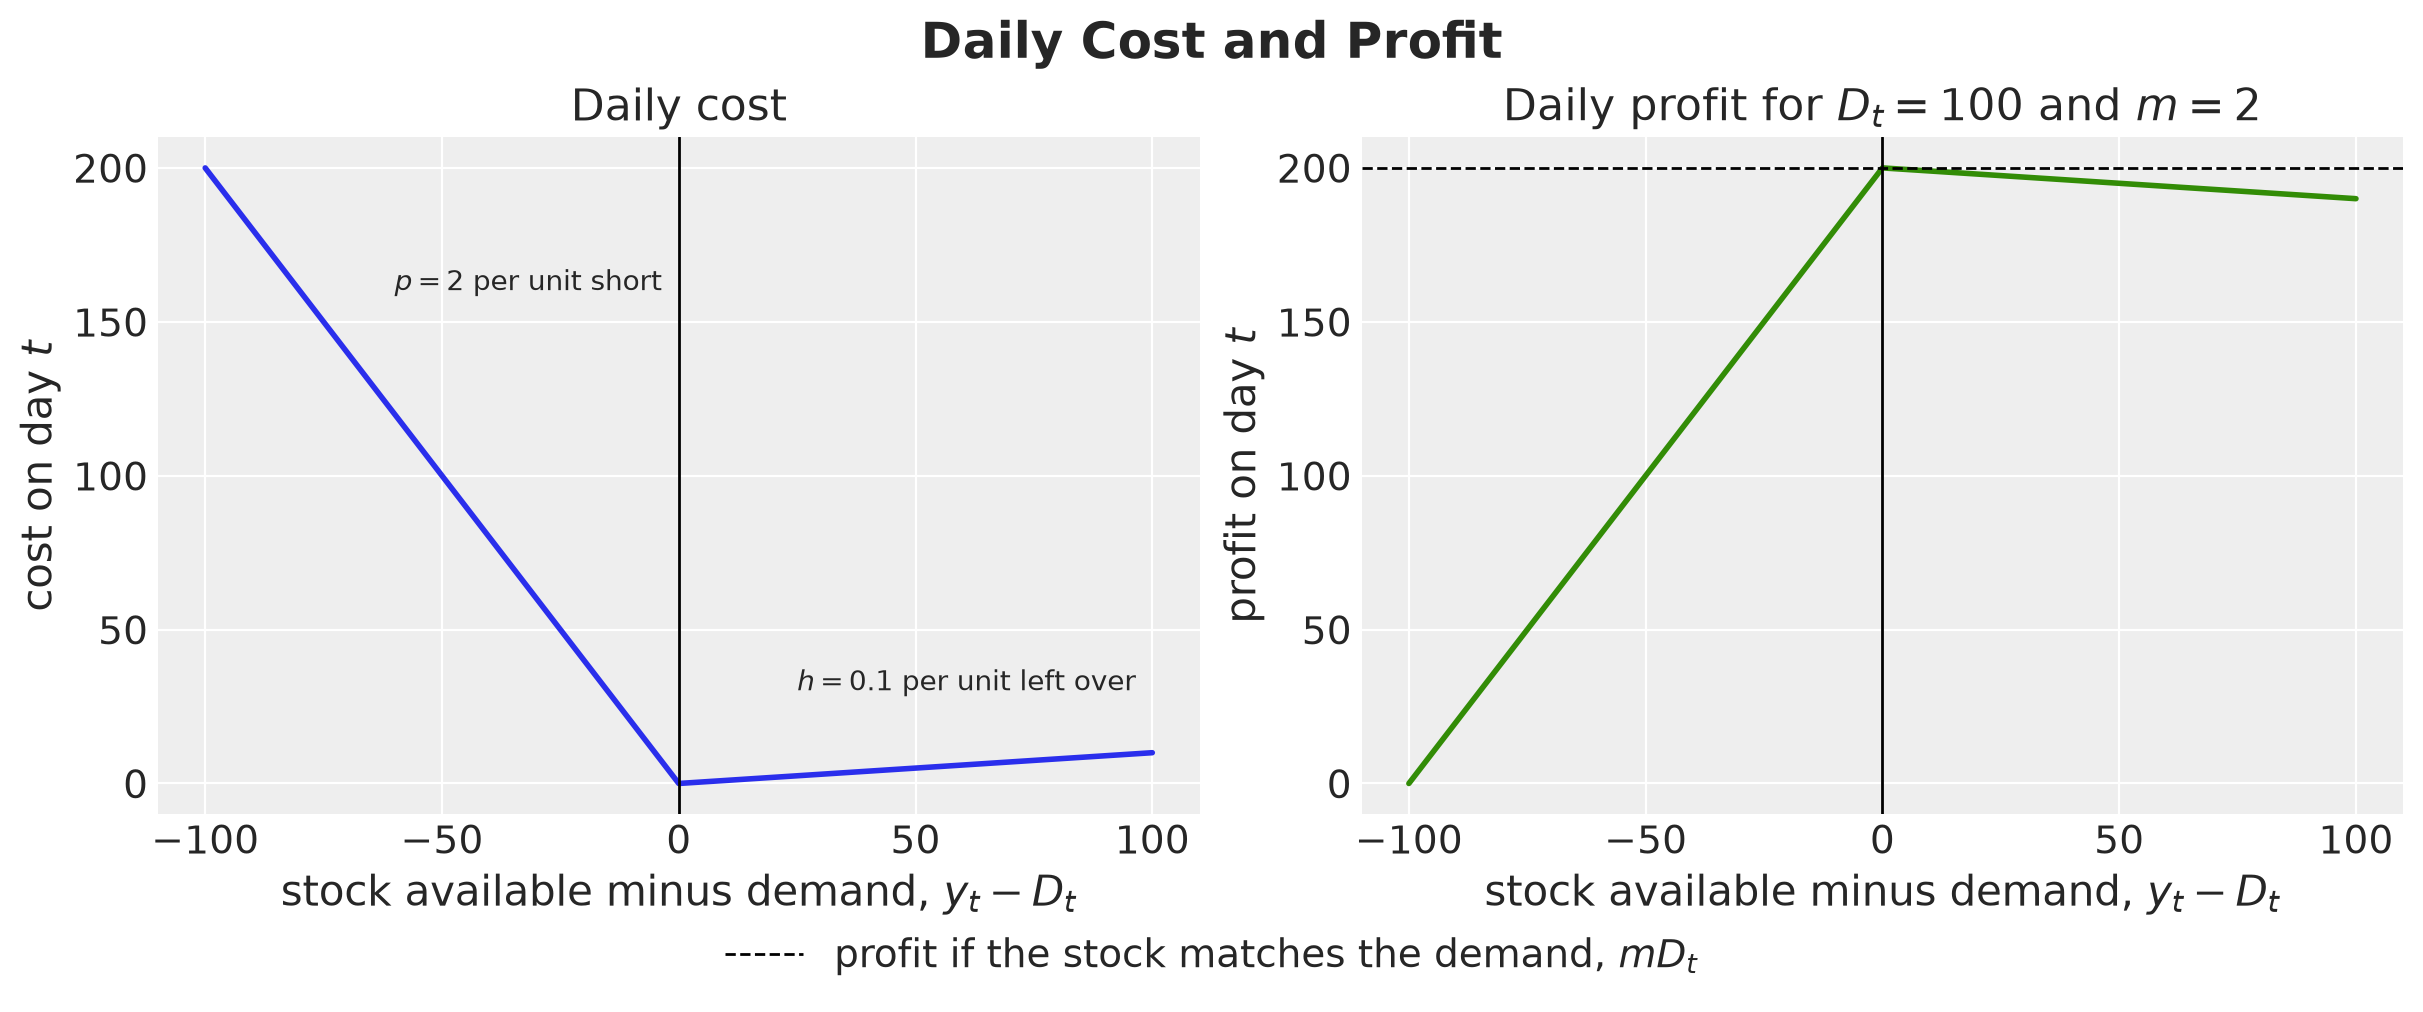

In [2]:
class InventoryConfig(NamedTuple):
    """Costs and initial stock of the inventory problem."""

    holding_cost: float
    lost_sales_cost: float
    initial_inventory: float


config = InventoryConfig(holding_cost=0.1, lost_sales_cost=2.0, initial_inventory=50.0)

gap_grid = np.linspace(-100, 100, 201)
daily_cost = config.holding_cost * np.maximum(
    gap_grid, 0.0
) + config.lost_sales_cost * np.maximum(-gap_grid, 0.0)
demand_example = 100.0
# margin on the whole demand minus the daily cost, with p equal to the margin m
daily_profit = config.lost_sales_cost * demand_example - daily_cost

fig, axes = plt.subplots(ncols=2, figsize=(12, 5))
ax = axes[0]
ax.plot(gap_grid, daily_cost, color="C0", linewidth=2)
ax.axvline(0.0, color="black", linewidth=1)
ax.text(-60, 160, f"$p = {config.lost_sales_cost:g}$ per unit short")
ax.text(25, 30, f"$h = {config.holding_cost:g}$ per unit left over")
ax.set(
    xlabel="stock available minus demand, $y_t - D_t$",
    ylabel="cost on day $t$",
    title="Daily cost",
)
ax = axes[1]
ax.plot(gap_grid, daily_profit, color="C2", linewidth=2)
ax.axvline(0.0, color="black", linewidth=1)
ax.axhline(
    config.lost_sales_cost * demand_example,
    color="black",
    linestyle="--",
    linewidth=1,
    label="profit if the stock matches the demand, $m D_t$",
)
ax.set(
    xlabel="stock available minus demand, $y_t - D_t$",
    ylabel="profit on day $t$",
    title=f"Daily profit for $D_t = {demand_example:g}$ "
    f"and $m = {config.lost_sales_cost:g}$",
)
fig.legend(loc="outside lower center")
fig.suptitle("Daily Cost and Profit", fontsize=18, fontweight="bold");

The daily cost is zero when the stock matches the demand and grows linearly on both sides, by $p = 2$ per unit short and by $h = 0.1$ per unit left over, so one unit short costs twenty times as much as one unit too many on the day itself. The two sides differ in one more way: a lost sale is charged once, while a leftover unit stays on the shelf and is charged $h$ on every later day until a customer buys it.

Note that with $h = 0.1$ and $m = 2$, a unit that waits $20$ days on the shelf costs as much as its whole margin. We chose this high holding cost so that the trade-off shows within a $15$-day horizon.

The right panel shows that the profit of a day is the margin on the whole demand minus the daily cost, so maximizing the profit is the same as minimizing the loss once we set $p$ to the margin. We set $p$ to the margin and not to the price because a lost sale loses the revenue of the unit but saves its purchase cost, while a leftover unit keeps the value we paid for it and we can still sell it after the horizon.

For a perishable product, or at the end of a season, the units left on the last day lose part of their value, and we would add that markdown to the loss as a terminal term proportional to $I_H$. We do not include it here.

The forecasting model gives us the posterior predictive distribution of the demand path $D$. We represent it by $N$ joint draws $D^{(1)}, \dots, D^{(N)}$, one path of $H$ days each. We call these paths **scenarios** and $N$ the **number of scenarios**. The plan $a$ must be fixed before we observe any demand, so one plan has to hold up across all of these scenarios. We approximate the **expected loss** of a plan by its sample average over the scenarios:

$$
\text{E}[L(a, D)] \approx \frac{1}{N} \sum_{n=1}^{N} L(a, D^{(n)}).
$$

## Decision Rules

We compare four ways of turning the scenarios into a plan. All of them use the same scenarios and are scored with the same loss, and they differ in what they ask of the scenarios: a cost to minimize, a stockout probability to bound, or a tail to penalize.

### Mean Forecast Plan

We replace the distribution by the **mean path** of the scenarios, $\bar{D} = \frac{1}{N} \sum_{n} D^{(n)}$, and solve the deterministic problem

$$
\min_{a \geq 0} \; L(a, \bar{D}).
$$

This is the plan that a point forecast gives. Against a single path, the cheapest plan brings the stock available on each day to the demand of that day and leaves nothing on the shelf, so the orders follow the mean path once the initial stock is used up.

### Chance-Constrained Plan

The chance-constrained plan does not use the costs. It fixes a **service level** instead, which is how often we are willing to run out. A **stockout** on day $t$ is the event $D_t > y_t$, and the fraction of scenarios in which it happens is our estimate of the stockout probability $\text{P}(D_t > y_t)$. We choose a small **tail probability** $\alpha$, here $\alpha = 0.05$, and require

$$
\text{P}(D_t > y_t) \leq \alpha \quad \text{for every } t = 1, \dots, H,
$$

and we look for the plan with the smallest cumulative orders that satisfies it.

Note that the constraint holds day by day. It bounds the chance of a lost sale on any single day, not the chance of at least one lost sale somewhere in the $15$ days. That probability is larger, because the plan has $15$ chances to fail: with independent days it would be $1 - (1 - \alpha)^{15} \approx 54\%$ for $\alpha = 0.05$.

The days are not independent, so we report both numbers in the evaluation: the stockout probability on a given day, which the constraint controls, and the probability of at least one stockout in the horizon, which it does not.

We build the plan with a **forward pass** over the days of the horizon, inside all the scenarios at once. Given the orders of days $1$ to $t - 1$, every scenario $n$ carries a simulated stock $I_{t-1}^{(n)}$ into day $t$, and the shortfall that the order has to cover in that scenario is $D_t^{(n)} - I_{t-1}^{(n)}$. The smallest order that leaves at most a fraction $\alpha$ of the scenarios short is the $(1 - \alpha)$ quantile of that shortfall across the scenarios,

$$
a_t = \left( Q_{1-\alpha}\!\left(D_t - I_{t-1}\right) \right)^{+}.
$$

Here is an important observation: the forward pass does not place an order each day after observing the demand. It walks through the horizon inside the scenarios, which we have today, and it never sees the real demand. Its output is the full vector $a$, and we place all $15$ orders today, as the problem statement requires.

One forward pass over the days builds the whole plan, and no optimizer is needed. The constraint counts how often we run out and ignores by how much.

**Remark:** This plan leaves the costs out, but the next two plans depend on them, so they need a good estimate of the cost of a lost sale. In many cases, not serving the demand is more costly than having leftovers. For example, there is a cost of customers having a bad experience, and therefore churning to competitors and never coming back. In real applications, it is important to account for this asymmetry in the cost function with estimates coming from customer surveys and other sources (or causal models).

### Expected Cost Plan

We minimize the sample average of the loss,

$$
\min_{a \geq 0} \; \frac{1}{N} \sum_{n=1}^{N} L(a, D^{(n)}),
$$

which is the **sample average approximation** of the Bayes decision, see [Shapiro, Dentcheva and Ruszczyński (2021)](https://doi.org/10.1137/1.9781611976595) for the general theory. To see what this plan does, let's look at one day in isolation. The stock available is $y_t$, the demand is $D_t$, a unit left over costs $h$ and a unit short costs $p$. This single-period problem has a name, the **newsvendor problem**, after the vendor who buys newspapers in the morning without knowing how many will sell. Its solution goes back to [Arrow, Harris and Marschak (1951)](https://doi.org/10.2307/1906813).

Its solution has a simple form. Suppose we raise the stock by one unit. With probability $\text{P}(D_t \leq y_t)$ the unit is left over and costs $h$, and with the remaining probability it covers a unit of demand and saves $p$. The expected cost stops decreasing when the two balance:

$$
h \, \text{P}(D_t \leq y_t) = p \, \left[1 - \text{P}(D_t \leq y_t)\right]
\quad \Longleftrightarrow \quad
\text{P}(D_t \leq y_t) = \frac{p}{p + h}.
$$

The optimal stock is the $p / (p + h)$ quantile of the demand distribution, and the ratio $p / (p + h)$ is called the **critical fractile**.

Note that with $p = h$ the critical fractile is $1 / 2$, so the optimal stock is the median of the demand. For a symmetric demand distribution, such as the Normal of the example below, the median is the mean. So with equal costs and a symmetric demand the mean forecast is the optimal single-period stock. With our costs, $p = 2$ and $h = 0.1$, the fractile is $0.952$, so the optimal stock is a high quantile of the demand, far above the mean.

Let's work a simple example with a Normal demand with mean $\mu = 60$ and standard deviation $\sigma = 15$. Let $\Phi$ and $\varphi$ be the distribution function and the density of the standard Normal. We write the demand as $D = \mu + \sigma Z$ with $Z$ standard Normal.

The stock $q$ is a number that we choose, not a random variable, and we let $z = (q - \mu) / \sigma$ be the stock in standard units. The gap between the stock and the demand is then $q - D = (q - \mu) - \sigma Z = \sigma \, (z - Z)$, so the leftover is $(q - D)^{+} = \sigma \, (z - Z)^{+}$ and the expected leftover is $\sigma \, \text{E}[(z - Z)^{+}]$, which is the integral of $(z - u) \, \varphi(u)$ over $u \leq z$:

$$
\text{E}[(q - D)^{+}] = \sigma \int_{-\infty}^{z} (z - u) \, \varphi(u) \, du = \sigma \left[ z \, \Phi(z) + \varphi(z) \right],
$$

where we used $\varphi'(u) = -u \, \varphi(u)$ for the second term.

The expected shortage follows from the identity $(D - q)^{+} = (q - D)^{+} + (D - q)$. Its expectation is the expected leftover minus $q - \mu = \sigma z$:

$$
\text{E}[(D - q)^{+}] = \sigma \left[ \varphi(z) - z \, \left(1 - \Phi(z)\right) \right].
$$

We compute both with `scipy.stats.norm`, add the two parts of the expected cost and plot it as a function of the stock, with the critical fractile of our costs.

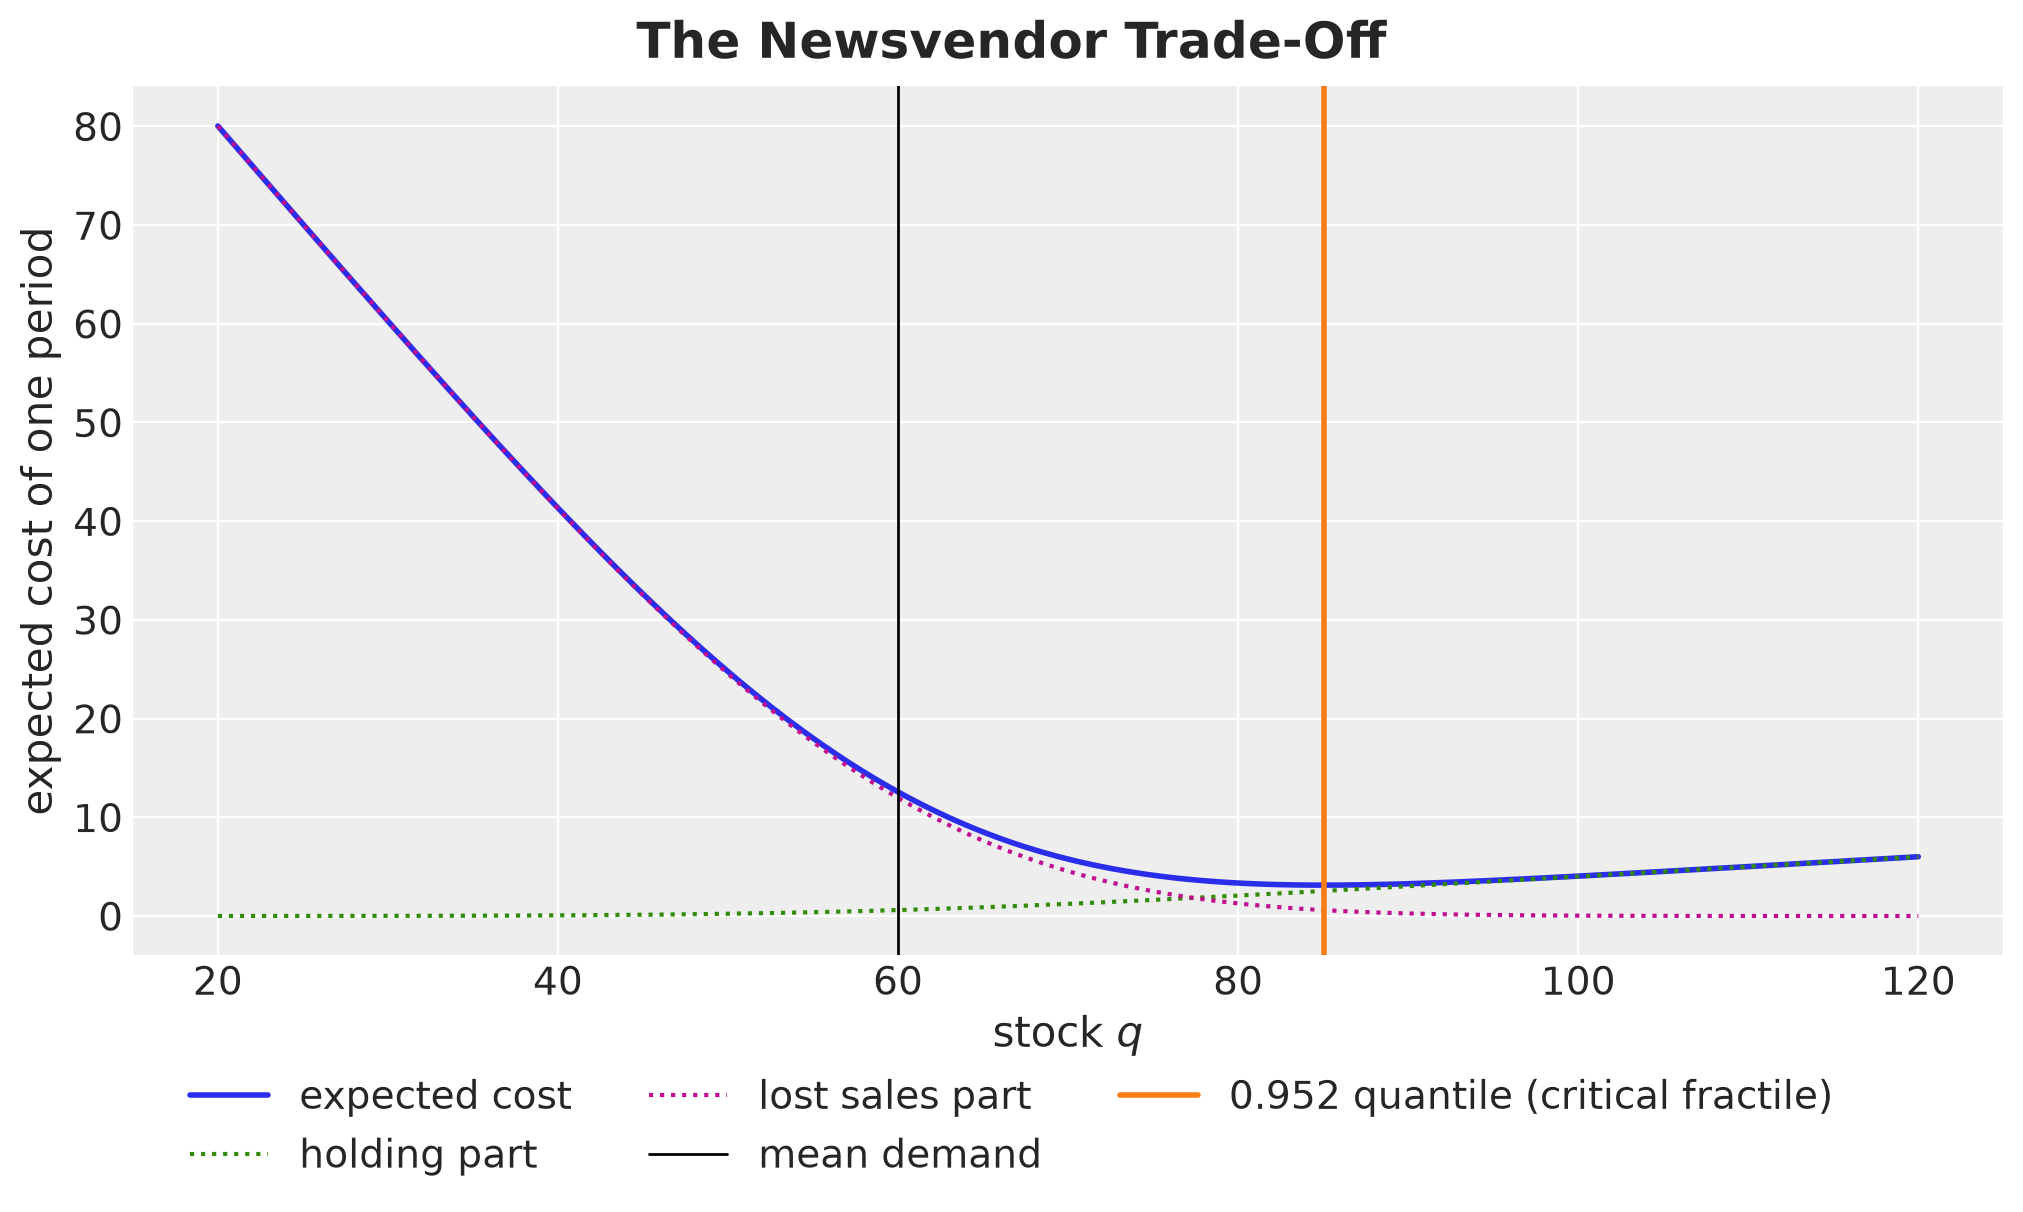

In [3]:
critical_fractile = config.lost_sales_cost / (
    config.lost_sales_cost + config.holding_cost
)

demand_mean, demand_sd = 60.0, 15.0
stock_grid = np.linspace(20, 120, 201)
z = (stock_grid - demand_mean) / demand_sd
expected_leftover = demand_sd * (z * norm.cdf(z) + norm.pdf(z))
expected_shortage = demand_sd * (norm.pdf(z) - z * (1 - norm.cdf(z)))
holding_part = config.holding_cost * expected_leftover
lost_sales_part = config.lost_sales_cost * expected_shortage
optimal_stock = demand_mean + demand_sd * norm.ppf(critical_fractile)

fig, ax = plt.subplots()
ax.plot(
    stock_grid,
    holding_part + lost_sales_part,
    color="C0",
    linewidth=2,
    label="expected cost",
)
ax.plot(stock_grid, holding_part, color="C2", linestyle=":", label="holding part")
ax.plot(stock_grid, lost_sales_part, color="C3", linestyle=":", label="lost sales part")
ax.axvline(demand_mean, color="black", linewidth=1, label="mean demand")
ax.axvline(
    optimal_stock,
    color="C1",
    linewidth=2,
    label=f"{critical_fractile:.3f} quantile (critical fractile)",
)
fig.legend(loc="outside lower center", ncol=3)
ax.set(xlabel="stock $q$", ylabel="expected cost of one period")
fig.suptitle("The Newsvendor Trade-Off", fontsize=18, fontweight="bold");

The expected cost has its minimum at the $0.952$ quantile, about $85$ units, and not at the mean of $60$. The lost sales part makes the curve steep on the left and the holding part makes it flat on the right, so a stock above the mean is cheaper than the mean itself.

Our problem has $15$ days, and the days are linked by the stock that carries over. The single-period rule charges a leftover unit one day of holding, while in the multi-period problem the unit pays $h$ on every later day until it is sold. It is also left over in the scenarios where day $t$ was slow, which carry more stock into day $t + 1$ and tend to have a low level, so the unit can take several days to sell.

So the marginal unit costs more than the single-period rule assumes. The plan that minimizes the expected loss keeps the probability $\text{P}(D_t \leq y_t)$ of covering the demand of day $t$ below $p / (p + h)$ on every day but the last, so the single-period rule, applied day by day, overstocks. We check this in the *Out of Sample Evaluation* section, where the expected cost plan runs out on $10\%$ of the days against the single-period $4.8\%$.

The general lost-sales problem, with delivery lead times and orders that react to the stock, is hard, see [Zipkin (2008)](https://doi.org/10.1287/opre.1070.0471) and the review of [Bijvank and Vis (2011)](https://doi.org/10.1016/j.ejor.2011.02.004). Our plan is fixed in advance, and this makes the problem a **convex program**: the loss is a convex function of the orders $a$, so every local minimum is the global one and a gradient method cannot get trapped in a local minimum.

The loss is convex because it can be written as a positive combination of the daily stocks plus a term that is linear in the orders, and each stock is a convex piecewise linear function of the orders. We show this in the *Appendix*, and we solve the problem numerically.

We keep the single-period rule as a reference, the **myopic newsvendor plan**: on each day, order up to the $p / (p + h)$ quantile of the shortfall $D_t - I_{t-1}$, with the same forward pass as the chance-constrained plan.

The expected cost plan has no service target of its own, i.e. we do not set a stockout probability. The stockout frequency it accepts is a consequence of the costs, and we read it from the outputs below. On the last day of the horizon the problem is a single-period one, since a leftover there is charged holding only once, so the optimal stockout probability on that day is $h / (p + h)$.

The myopic rule uses the same critical fractile as the order rule of the winning VN2 entry, where Szabłowski (2026) maps $c_s / (c_s + c_h)$ to a Normal quantile around a point forecast and re-plans every week on the observed inventory. We read the quantile from the scenarios instead, which the report itself recommends:

> In production, $q^\star$ would be implemented via empirical quantiles or a probabilistic forecast, avoiding any normality assumption.

### CVaR Plan

The CVaR plan adds a penalty on the worst outcomes. Let $\text{VaR}_\alpha(L) = Q_{1-\alpha}(L)$ be the $(1 - \alpha)$ quantile of the loss, the **value at risk**. For a continuous loss, the **conditional value at risk** is the expected loss beyond that quantile:

$$
\text{CVaR}_\alpha(L) = \text{E}\left[ L \mid L \geq \text{VaR}_\alpha(L) \right].
$$

With $N$ equally weighted scenarios, the sample estimate is the mean of the $k = \alpha N$ largest losses, and this is what the function `cvar` computes below.

Again, let's work a simple example. We draw the two quantities on a skewed loss density, a LogNormal with log-mean $\mu = 5$ and log-standard deviation $\sigma = 0.6$, for the tail probability $\alpha = 0.05$. If $L$ is LogNormal, then $W = \log L$ is $\text{Normal}(\mu, \sigma)$, and every quantity we need has a closed form. Let's derive them one at a time.

First, let's derive the density. Let $F$ be the distribution function of $L$ and $f = F'$ its density. For $x > 0$ the event $L \leq x$ is the event $W \leq \log x$, so

$$
F(x) = \text{P}(L \leq x) = \text{P}(W \leq \log x) = \Phi\!\left(\frac{\log x - \mu}{\sigma}\right).
$$

The density is the derivative of $F$, and the chain rule gives

$$
f(x) = \frac{1}{\sigma x} \, \varphi\!\left(\frac{\log x - \mu}{\sigma}\right).
$$

Next, we turn to the value at risk. Let $z_{1-\alpha} = \Phi^{-1}(1 - \alpha)$ be the $(1 - \alpha)$ quantile of the standard Normal. The value at risk is the $x$ with $F(x) = 1 - \alpha$, so $(\log x - \mu) / \sigma = z_{1-\alpha}$ and

$$
\text{VaR}_\alpha(L) = \exp\left(\mu + \sigma \, z_{1-\alpha}\right).
$$

Now we compute the mean. We write $W = \mu + \sigma Z$ with $Z$ standard Normal, so

$$
\text{E}[L] = \text{E}\left[e^{W}\right] = \int_{-\infty}^{\infty} e^{\mu + \sigma z} \, \varphi(z) \, dz.
$$

Completing the square in the exponent, $\sigma z - z^2 / 2 = \sigma^2 / 2 - (z - \sigma)^2 / 2$, so the integrand is $e^{\mu + \sigma^2 / 2} \, \varphi(z - \sigma)$, and the density $\varphi(z - \sigma)$ integrates to one:

$$
\text{E}[L] = \exp\left(\mu + \sigma^2 / 2\right).
$$

Finally, we compute the conditional value at risk. It is the same integral restricted to the tail $Z \geq z_{1-\alpha}$, divided by the probability $\alpha$ of that tail:

$$
\text{CVaR}_\alpha(L) = \frac{1}{\alpha} \int_{z_{1-\alpha}}^{\infty} e^{\mu + \sigma z} \, \varphi(z) \, dz = \frac{e^{\mu + \sigma^2 / 2}}{\alpha} \int_{z_{1-\alpha}}^{\infty} \varphi(z - \sigma) \, dz.
$$

The last integral is $1 - \Phi(z_{1-\alpha} - \sigma) = \Phi(\sigma - z_{1-\alpha})$, so

$$
\text{CVaR}_\alpha(L) = \frac{1}{\alpha} \exp\left(\mu + \sigma^2 / 2\right) \Phi\left(\sigma - z_{1-\alpha}\right).
$$

In the code we evaluate the four formulas with `scipy.stats.norm`. We fix $\alpha$ here, since the chance constraint and the CVaR share it.

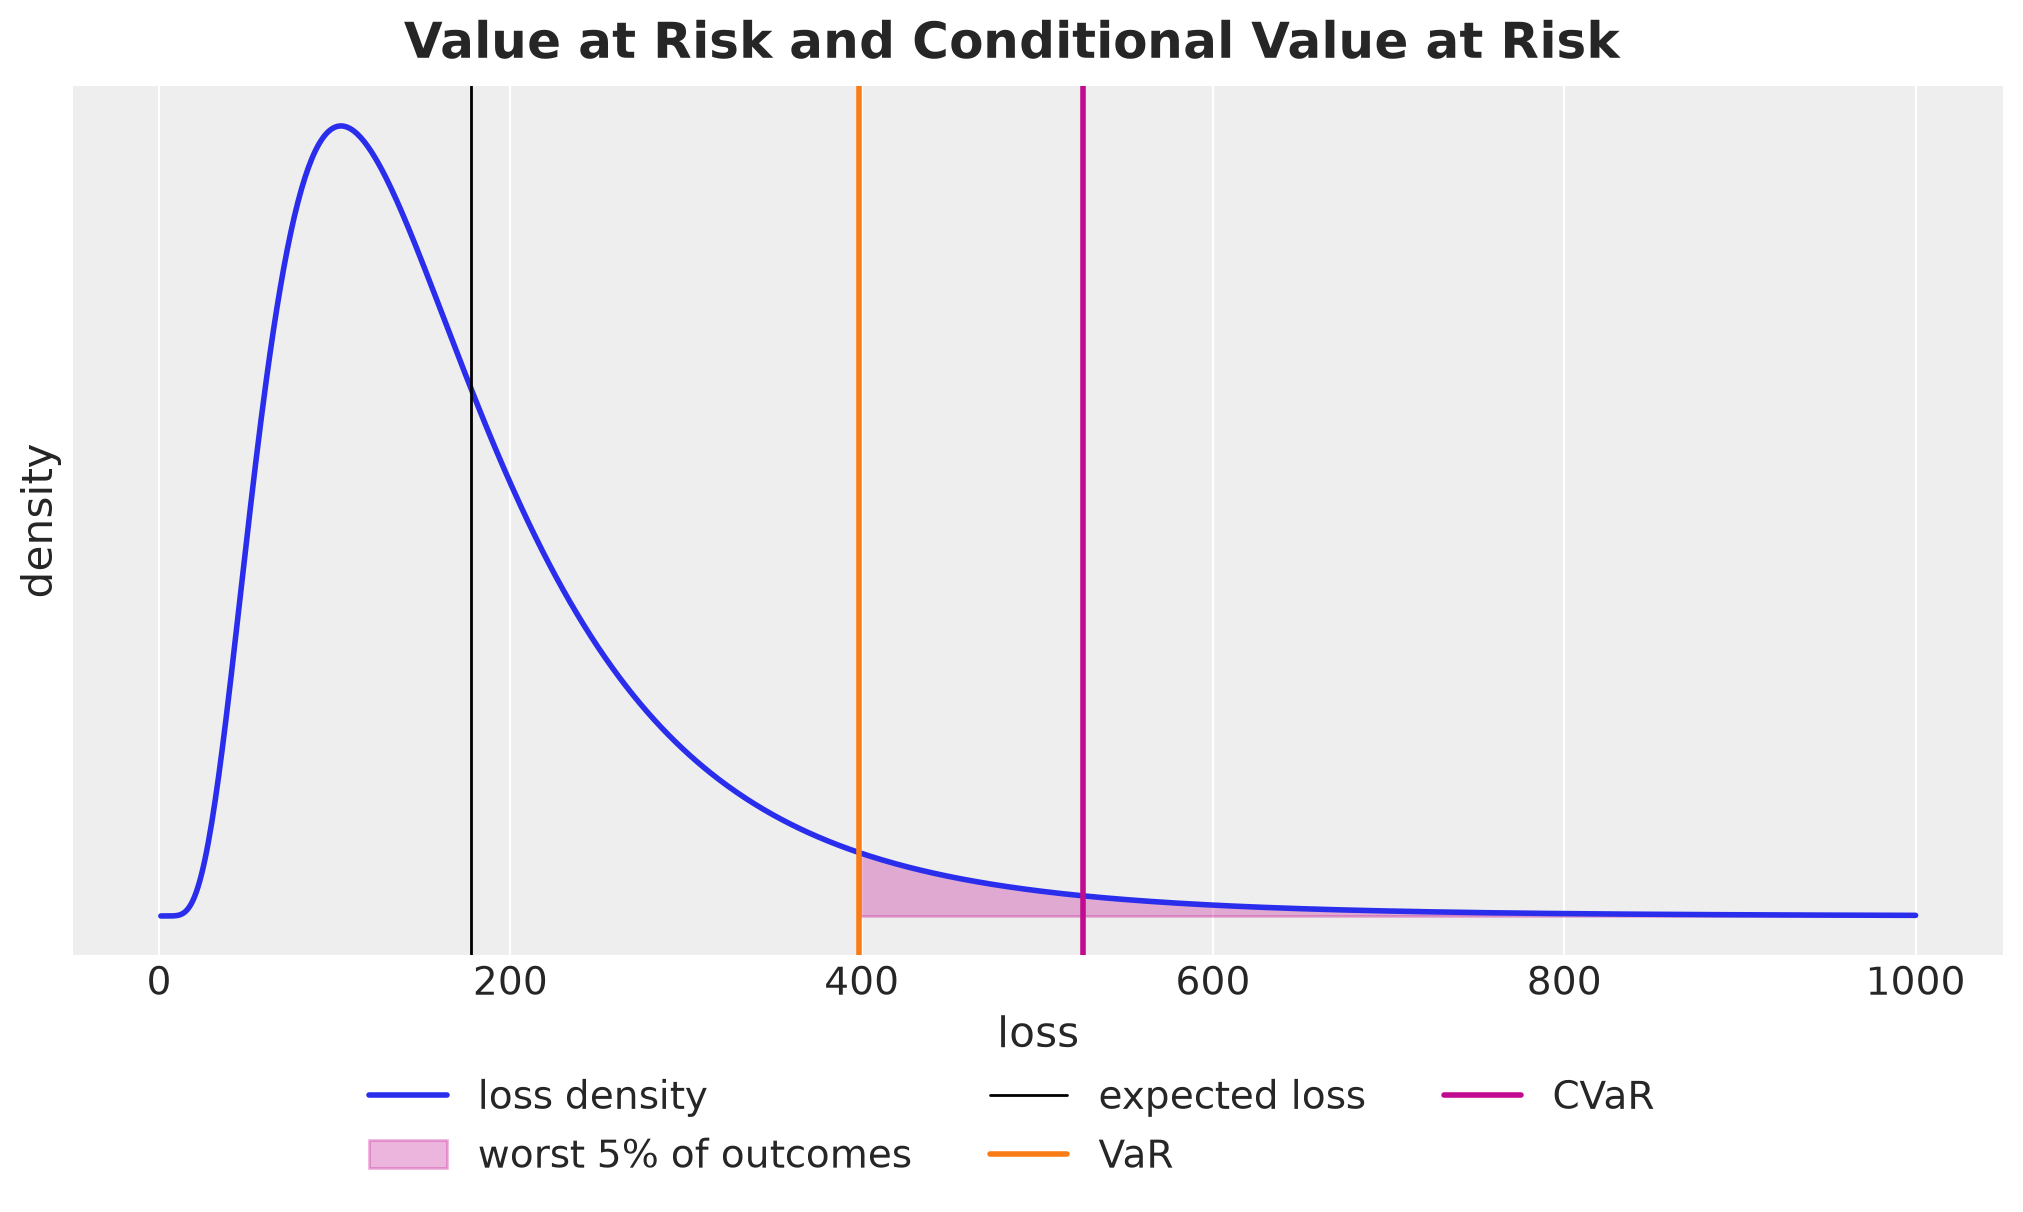

In [4]:
ALPHA = 0.05  # tail probability of the chance constraint and of the CVaR

log_mean, log_sd = 5.0, 0.6
loss_grid = np.linspace(1, 1_000, 1_000)
loss_density = norm.pdf((np.log(loss_grid) - log_mean) / log_sd) / (log_sd * loss_grid)
z_alpha = norm.ppf(1 - ALPHA)
expected_loss_example = np.exp(log_mean + log_sd**2 / 2)
var_example = np.exp(log_mean + log_sd * z_alpha)
cvar_example = expected_loss_example * norm.cdf(log_sd - z_alpha) / ALPHA

fig, ax = plt.subplots()
ax.plot(loss_grid, loss_density, color="C0", linewidth=2, label="loss density")
ax.fill_between(
    loss_grid,
    loss_density,
    where=loss_grid >= var_example,
    color="C3",
    alpha=0.3,
    label=f"worst {ALPHA:.0%} of outcomes",
)
ax.axvline(expected_loss_example, color="black", linewidth=1, label="expected loss")
ax.axvline(var_example, color="C1", linewidth=2, label="VaR")
ax.axvline(cvar_example, color="C3", linewidth=2, label="CVaR")
fig.legend(loc="outside lower center", ncol=3)
ax.set(xlabel="loss", ylabel="density", yticks=[])
fig.suptitle(
    "Value at Risk and Conditional Value at Risk", fontsize=18, fontweight="bold"
);

The value at risk is the point that the loss exceeds with probability $5\%$. The conditional value at risk is the average loss in the shaded region beyond it, so it sits further to the right, and well above the expected loss because the density has a long right tail.

Having understood the intuition of the CVaR, we can write the objective that the CVaR plan minimizes in practice:

$$
\min_{a \geq 0} \; \text{E}[L(a, D)] + \lambda \, \text{CVaR}_\alpha(L(a, D)),
$$

where $\lambda \geq 0$ is the **tail weight**, the weight we put on the worst $\alpha$ fraction of the outcomes. With $\lambda = 0$ we recover the expected cost plan. The CVaR term counts how bad the worst outcomes are, not how often they happen.

Now that we have these concepts in place, let's put them into practice on a synthetic data set.

## Generate Data

We simulate daily demand from a generative model with a slowly drifting level, a weekly pattern, price promotions and negative binomial noise.

1. We write the model in PyMC.
2. Fix the true parameters with `pm.do`.
3. Take one draw with `pm.sample_prior_predictive`.

We include the price as a covariate because the retailer sets it, so its future values are known: the promotion calendar of the horizon is fixed in advance. A covariate helps the forecast only if we know its future values, and weather or competitor actions would need a forecast of their own. Here are the specs of this promotion feature: a promotion lasts one calendar week and cuts the list price by $30\%$. In the history, each week is a promotion week with probability $0.1$. In the horizon, the second week (days $8$ to $14$) is a promotion week. We pass this calendar to the model data generator as an input.

To store this configuration we use a `Setup` named tuple as data structure.

In [5]:
class Setup(NamedTuple):
    """Length of the history and the horizon, and the promotion settings."""

    t_obs: int = 364  # one year of daily history
    horizon: int = 15  # days to plan
    discount: float = 0.3  # price cut in a promotion week
    promo_prob: float = 0.1  # chance that a given week of the history is a promotion

    @property
    def duration(self) -> int:
        return self.t_obs + self.horizon


setup = Setup()
days = np.arange(setup.duration)
days_future = days[setup.t_obs :]
# Fourier features to generate weekly seasonality, labeled along a "fourier" dim
fourier = fourier_features(days, period=7.0, num_terms=3)
FOURIER_LABELS = list(fourier["fourier"].values)
# the retailer's plan for the horizon: a promotion in its second week
promo_future = np.zeros(setup.horizon)
promo_future[7:14] = 1.0

Now, let's specify the data generating process. Let $\ell_t$ be the **latent level**, $\delta_t$ be the **daily increment** of the level, $x_t$ the **vector of Fourier features** of the weekly cycle, $r_t$ the **price relative to the list price** and $\mu_t$ the **expected demand** on day $t$:

$$
\begin{aligned}
D_t &\sim \text{NegativeBinomial}(\mu_t, \phi), \\
\log \mu_t &= \beta_0 + \ell_t + x_t^\top \beta + \gamma \log r_t, \\
\ell_t &= \sum_{\tau \leq t} \delta_\tau, \\
\delta_t &\sim \text{Normal}(0, \sigma_\delta),
\end{aligned}
$$

where $\beta_0$ is the `intercept`, $\beta$ the Fourier coefficients `beta`, $\gamma$ the price `elasticity`, $\sigma_\delta$ the `drift_scale` and $\phi$ the `concentration` of the negative binomial (a larger $\phi$ is closer to a Poisson). The price enters as a log, so $\gamma$ is an elasticity. Taking exponentials,

$$
\mu_t = \exp\left(\beta_0 + \ell_t + x_t^\top \beta\right) \cdot r_t^{\gamma},
$$

so a relative price $r_t$ multiplies the demand by $r_t^{\gamma}$. In a promotion week $r_t = 0.7$, and with $\gamma = -1.5$ the demand is multiplied by $0.7^{-1.5} \approx 1.71$.

We proceed by implementing this process in a PyMC model. The priors inside the generator play no role, since `pm.do` fixes every parameter, and we choose the priors of the forecasting model in the next section. The promotion weeks of the history are Bernoulli draws with a `week` dim, repeated over the seven days of each week. The `log_price` variable is a `pm.Deterministic` so that we can read the price path back from the draw. In PyMC, `pm.NegativeBinomial(mu, alpha)` is the mean and concentration parametrization of the formula above.

We keep the demand and the price path, and we split the demand into the observed history and the true future. The covariate matrix of the forecasting model is the Fourier design plus the log relative price as a last column.

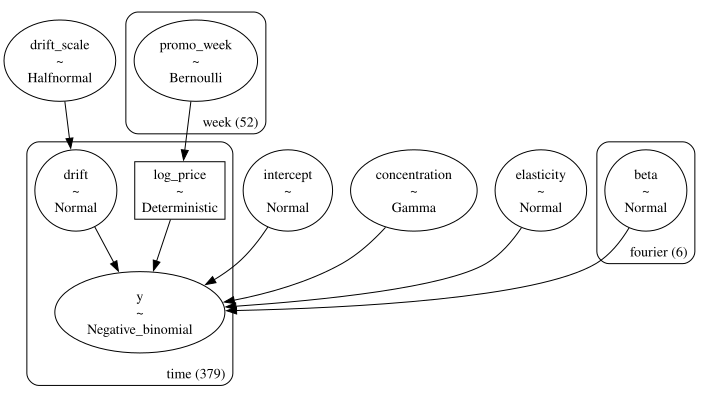

In [6]:
generator_coords = {
    "time": days,
    "fourier": FOURIER_LABELS,
    "week": np.arange(setup.t_obs // 7),
}

with pm.Model(coords=generator_coords) as demand_generator:
    intercept = pm.Normal("intercept", 4.0, 1.0)
    beta = pm.Normal("beta", 0.0, 0.3, dims="fourier")
    elasticity = pm.Normal("elasticity", 0.0, 1.0)
    drift_scale = pm.HalfNormal("drift_scale", 0.05)
    concentration = pm.Gamma("concentration", alpha=20.0, beta=1.0)

    # one Bernoulli per week of history, repeated over its seven days
    promo_week = pm.Bernoulli("promo_week", setup.promo_prob, dims="week")
    promo = pt.concatenate([pt.repeat(promo_week, 7), promo_future])
    log_price = pm.Deterministic(
        "log_price", promo * np.log(1.0 - setup.discount), dims="time"
    )

    drift = pm.Normal("drift", 0.0, drift_scale, dims="time")
    level = pt.cumsum(drift)
    log_rate = intercept + level + pt.dot(fourier.values, beta) + elasticity * log_price
    pm.NegativeBinomial("y", mu=pt.exp(log_rate), alpha=concentration, dims="time")

# Data generating process
pm.model_to_graphviz(demand_generator)

We now fix the true parameter values that we intervene on, and take one draw.

In [7]:
true_params = {
    "intercept": np.log(60.0),
    "beta": np.array([0.15, 0.05, -0.08, 0.10, 0.03, -0.02]),
    "elasticity": -1.5,
    "drift_scale": 0.01,
    "concentration": 30.0,
}

generator = pm.do(demand_generator, true_params)
draw = pm.sample_prior_predictive(
    draws=1, model=generator, var_names=["y", "log_price"], random_seed=rng
)

demand_full = draw["prior"]["y"].values[0, 0].astype("float64")
log_price = draw["prior"]["log_price"].values[0, 0]
covariates = xr.DataArray(
    np.column_stack([fourier.values, log_price]),
    dims=(TIME_DIM, "covariate"),
    coords={TIME_DIM: days, "covariate": [*FOURIER_LABELS, "log_price"]},
)
covariates_train = covariates.isel({TIME_DIM: slice(None, setup.t_obs)})

data = xr.DataArray(
    demand_full[: setup.t_obs], dims=(TIME_DIM,), coords={TIME_DIM: days[: setup.t_obs]}
)
demand_future_true = demand_full[setup.t_obs :]
promo_days_future = days_future[promo_future > 0]

We plot the demand series and the price path below it. The dashed line marks the start of the planning horizon.

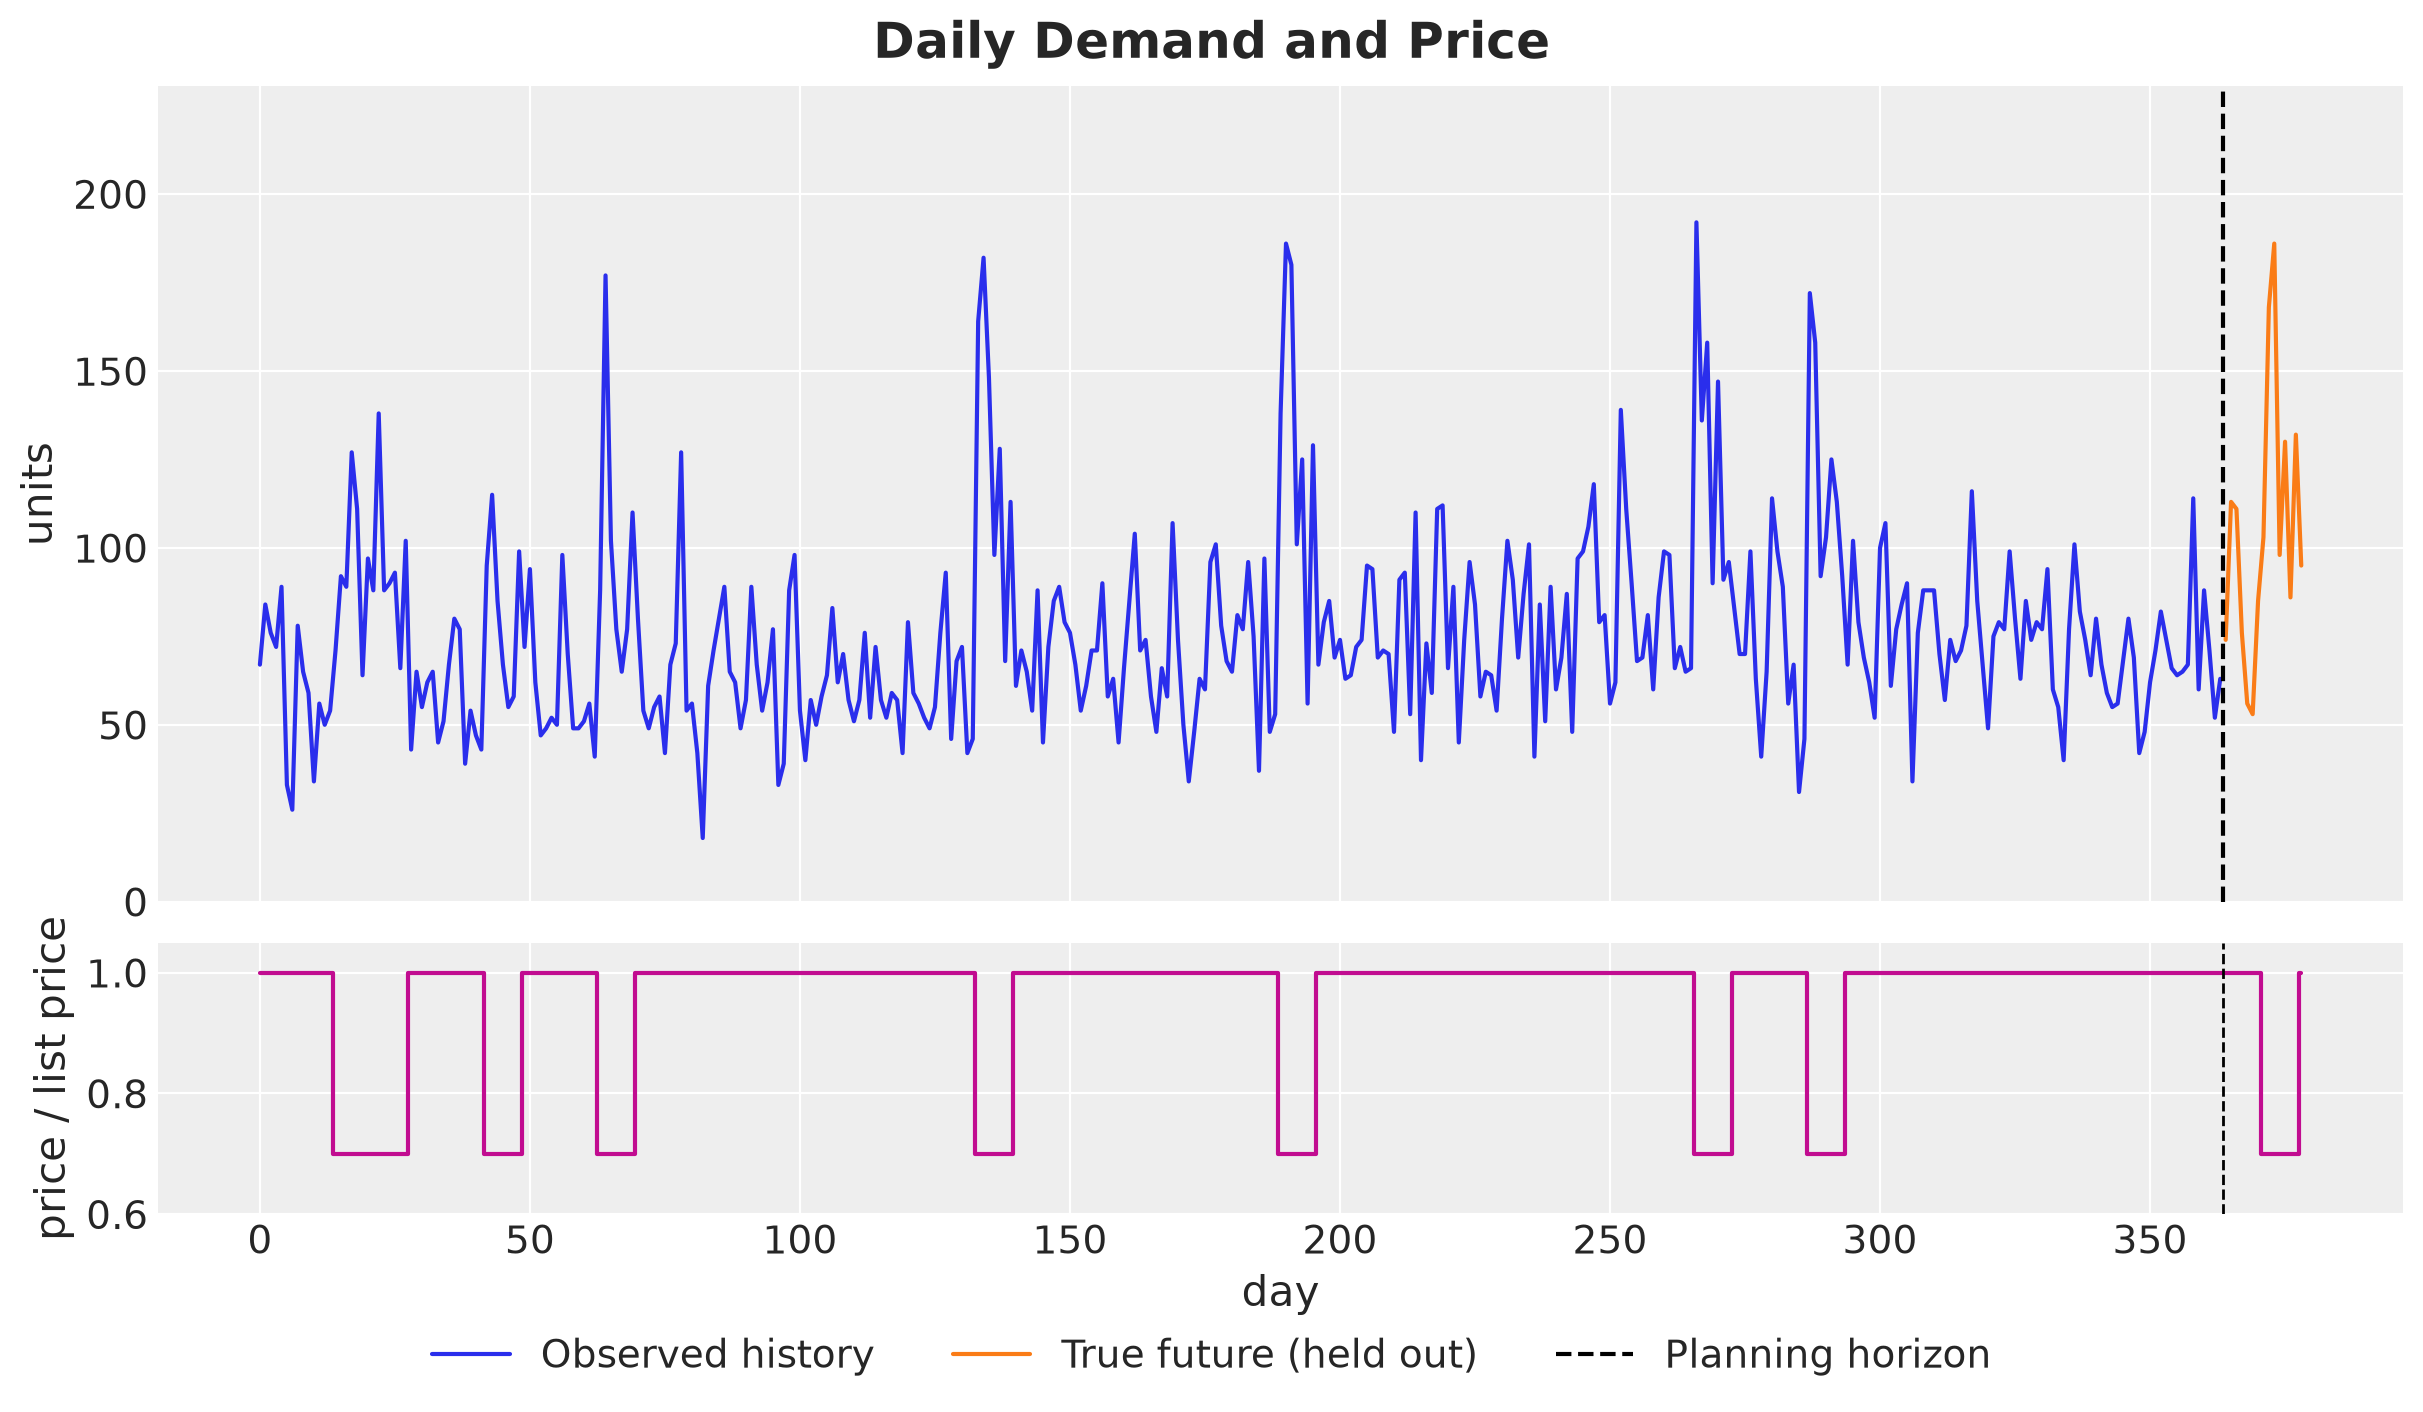

In [8]:
fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(12, 7),
    sharex=True,
    sharey=False,
    height_ratios=[3, 1],
    layout="constrained",
)

ax = axes[0]
ax.plot(days[: setup.t_obs], data.values, color="C0", label="Observed history")
ax.plot(days_future, demand_future_true, color="C1", label="True future (held out)")
ax.axvline(setup.t_obs - 0.5, color="black", linestyle="--", label="Planning horizon")
ax.set(ylabel="units", ylim=(0, 1.2 * float(demand_full.max())))
ax = axes[1]
ax.step(days, np.exp(log_price), where="mid", color="C3")
ax.axvline(setup.t_obs - 0.5, color="black", linestyle="--", linewidth=1)
ax.set(xlabel="day", ylabel="price / list price", ylim=(0.6, 1.05))
fig.legend(loc="outside lower center", ncol=3)
fig.suptitle("Daily Demand and Price", fontsize=18, fontweight="bold");

We see a weekly cycle on top of a level that drifts over the year, and a block of high demand in every promotion week. The blocks are the part of the series that the price covariate explains. The true future appears in the plots as a reference, and we score the plans on it at the end of the evaluation.

## Forecasting Model

The forecasting model has the same structure as the generator, the same latent level, covariates and likelihood, so it is well specified. Nevertheless, we need to reason about the priors and specify them ourselves.

### Prior Elicitation

The model has five global parameters. For three of them we state what we believe on the scale of the data and use [PreliZ](https://preliz.readthedocs.io/) to turn the statement into a distribution: `pz.maxent` returns the member of a family that puts a given mass between two bounds (the one with maximum entropy, so it adds nothing beyond our constraints). Here is the reasoning for each of the three.

- **`intercept`**: $\exp(\beta_0)$ is the demand per day at the start of the history at the list price, with the weekly pattern averaged out on the log scale (the Fourier terms sum to zero over a week). We believe it lies between $10$ and $300$ units, a wide range for a product that sells tens of units per day. So we ask for a Normal on $\beta_0$ with $94\%$ of its mass between $\log 10$ and $\log 300$.

- **`drift_scale`**: the level is a random walk, so after $T$ days the standard deviation of the log level is $\sigma_\delta \sqrt{T}$, and $\exp(\sigma_\delta \sqrt{T})$ is the typical factor by which the level has moved. Over the $364$ days of history we believe that factor lies between $1.04$ and $2$, that is, from a $4\%$ move to a doubling. So we ask for a LogNormal on $\sigma_\delta$ with $94\%$ of its mass between $\log(1.04) / \sqrt{T}$ and $\log(2) / \sqrt{T}$. The LogNormal density vanishes at zero, which fits a level that moves at least a little over a year.

- **`concentration`**: the negative binomial adds $\mu_t^2 / \phi$ to the Poisson variance, so the extra day-to-day noise is a fraction $1 / \sqrt{\phi}$ of the level. We believe that fraction lies between a tenth and a half, which is $\phi$ between $4$ and $100$. So we ask for a Gamma with $94\%$ of its mass in that range.

The other two priors we state directly.

- Each Fourier coefficient in `beta` gets a $\text{Normal}(0, 0.3)$, so two standard deviations multiply the demand by $e^{\pm 0.6}$, between $0.55$ and $1.8$.

- The `elasticity` gets a $\text{Normal}(-1, 1)$: a higher price should lower the demand, so we center the prior on a negative value, and the standard deviation of $1$ leaves a positive value possible if the data ask for it.

We run the three elicitations and plot the densities in two rows. The top row is the parameter scale, with the elicited density and the two bounds we asked for. The bottom row is the data scale: the density of the quantity we reasoned about (demand per day, level multiplier after one year, noise fraction), with the bounds mapped through the same transform.

The bottom row needs no draws. If $\psi = g(\theta)$ is a monotone transform of the parameter $\theta$ with density $f$, the density of $\psi$ is $f(g^{-1}(\psi)) \, |dg^{-1} / d\psi|$ by the change of variables formula. We write the inverse transforms in `pytensor.tensor`, take the derivative with `pt.grad` and compile both with `pytensor.function`. The derivative of the sum of an elementwise function with respect to its input vector is the vector of elementwise derivatives, which is the Jacobian we need.

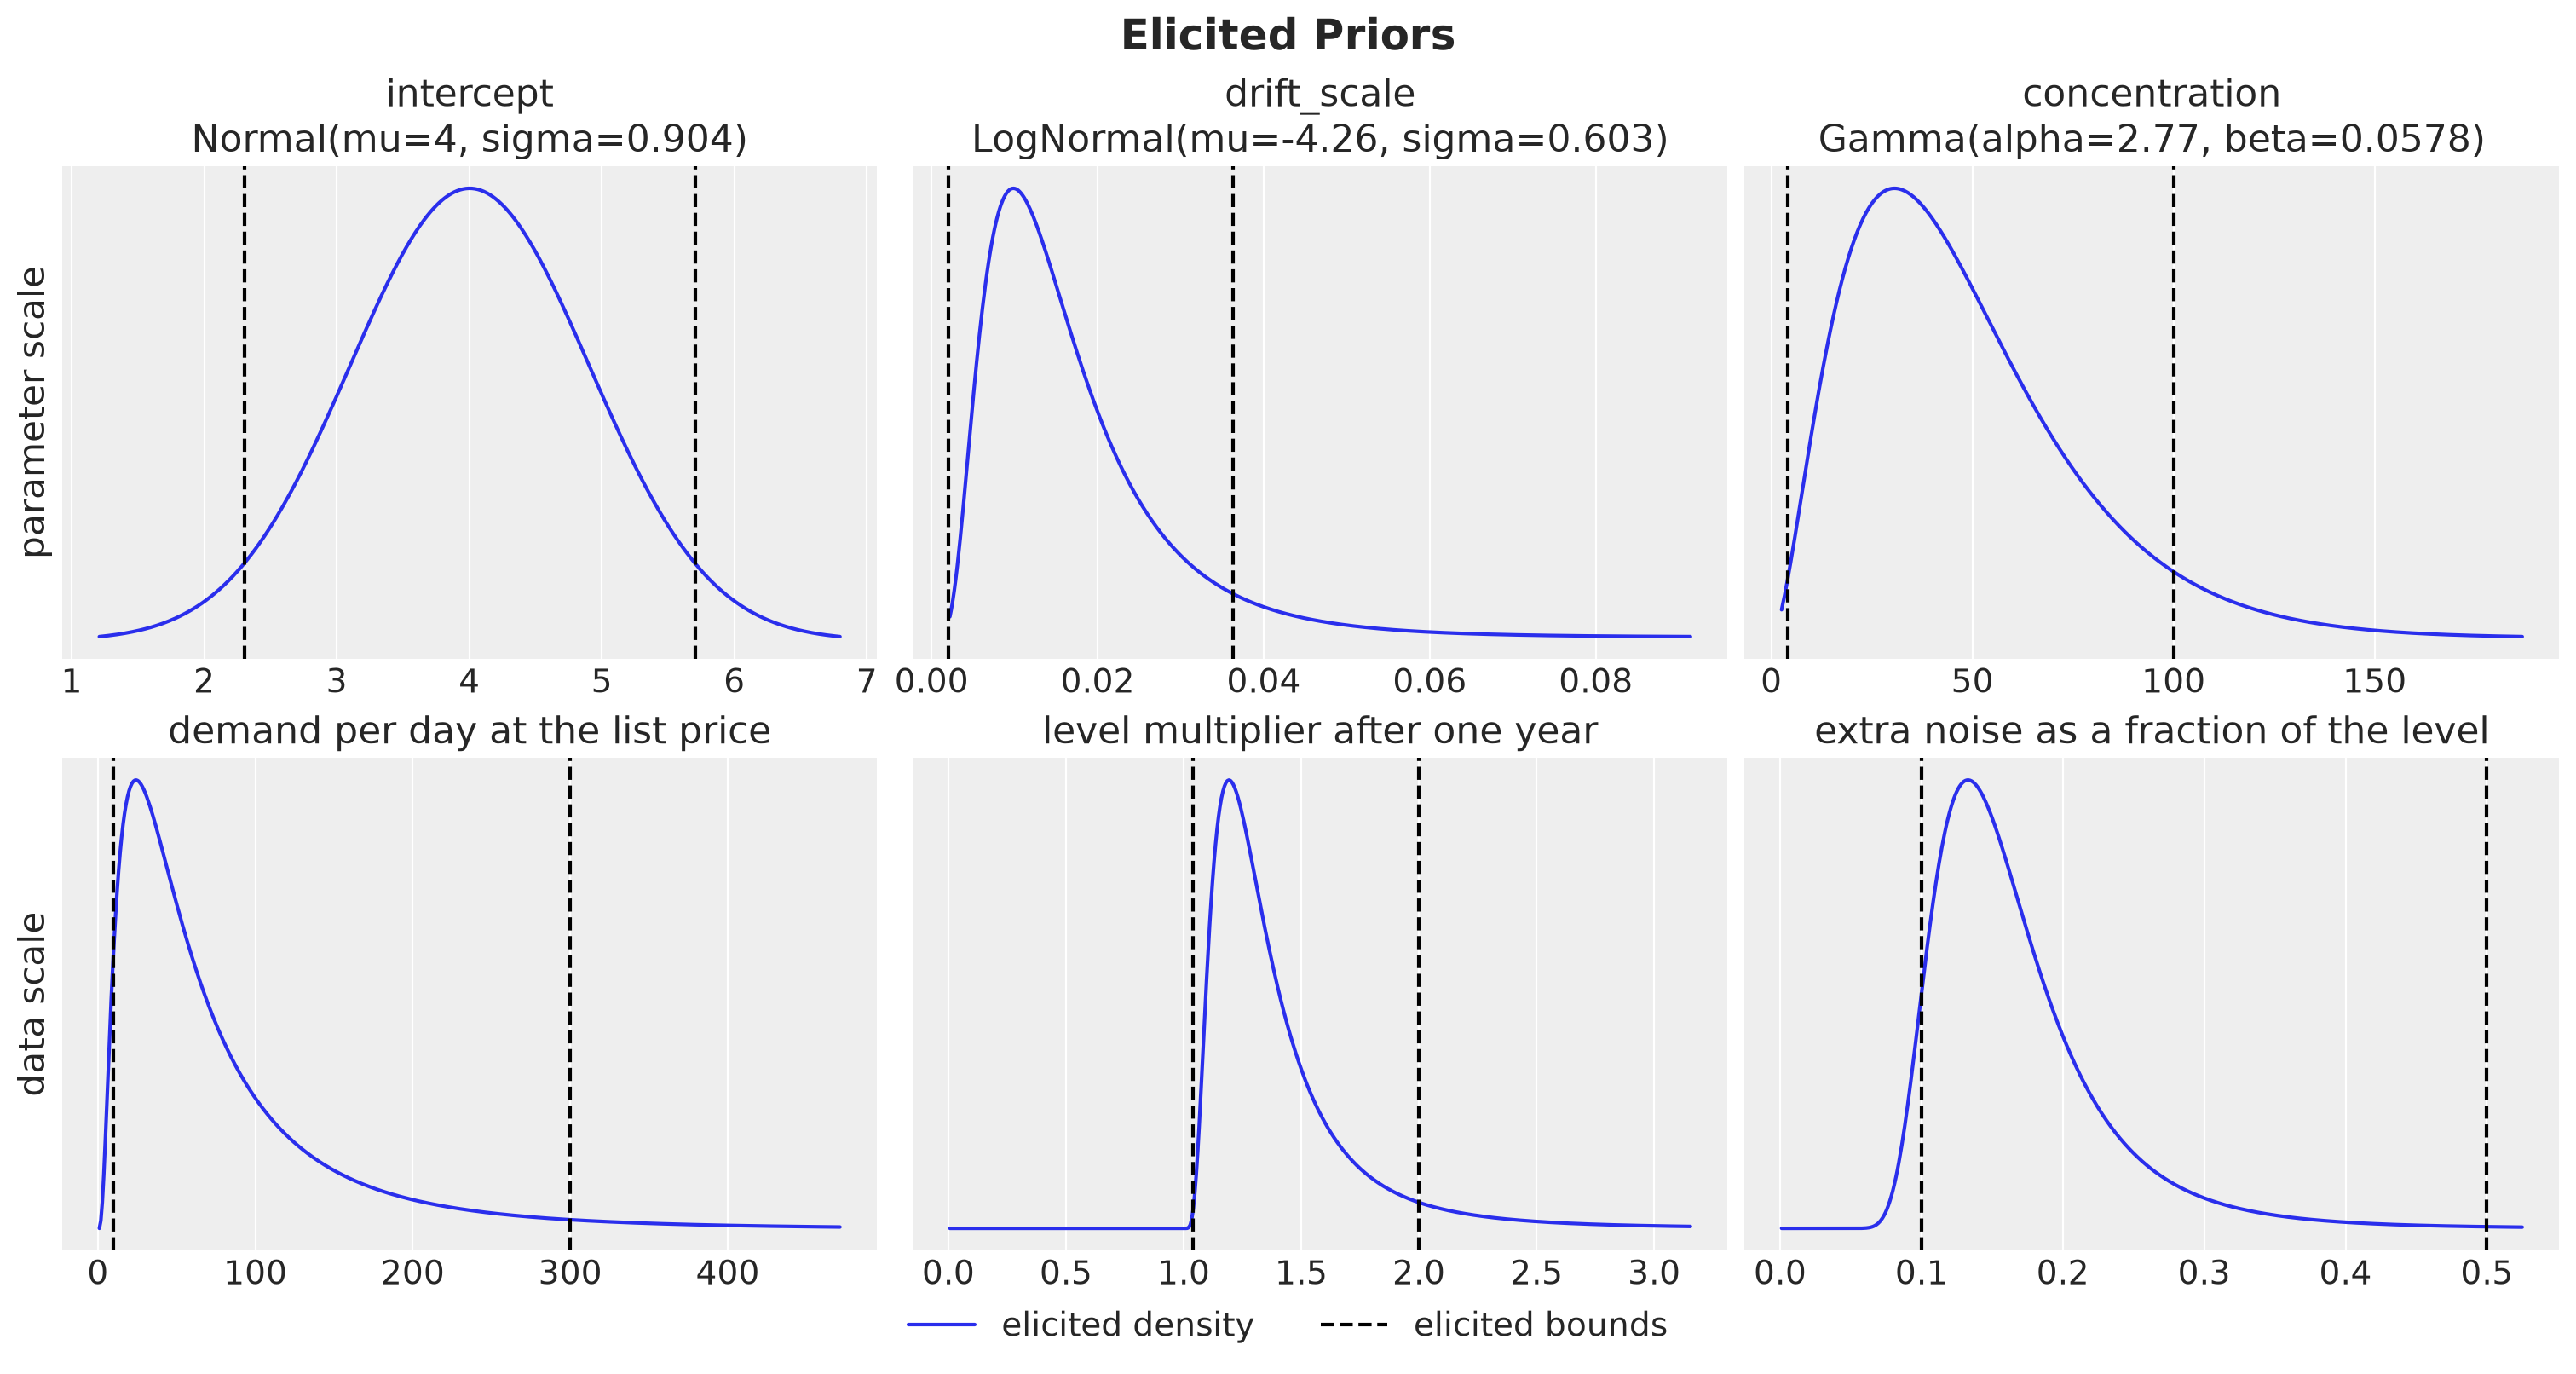

In [9]:
intercept_bounds = (float(np.log(10)), float(np.log(300)))
drift_bounds = (
    float(np.log(1.04) / np.sqrt(setup.t_obs)),
    float(np.log(2) / np.sqrt(setup.t_obs)),
)
concentration_bounds = (4.0, 100.0)
# the prior mass between the bounds, fixed here and not tied to the plotted bands
ELICITATION_MASS = 0.94

intercept_prior = pz.maxent(
    pz.Normal(), *intercept_bounds, mass=ELICITATION_MASS, plot=False
)
drift_prior = pz.maxent(
    pz.LogNormal(), *drift_bounds, mass=ELICITATION_MASS, plot=False
)
concentration_prior = pz.maxent(
    pz.Gamma(), *concentration_bounds, mass=ELICITATION_MASS, plot=False
)

priors = {
    "intercept": (intercept_prior, intercept_bounds),
    "drift_scale": (drift_prior, drift_bounds),
    "concentration": (concentration_prior, concentration_bounds),
}
# the quantity on the data scale that each prior is about: the label, the transform
# (numpy, applied to the bounds) and its inverse (pytensor, differentiated below)
data_scale = {
    "intercept": ("demand per day at the list price", np.exp, pt.log),
    "drift_scale": (
        "level multiplier after one year",
        lambda x: np.exp(x * np.sqrt(setup.t_obs)),
        lambda y: pt.log(y) / np.sqrt(setup.t_obs),
    ),
    "concentration": (
        "extra noise as a fraction of the level",
        lambda x: 1 / np.sqrt(x),
        lambda y: 1 / y**2,
    ),
}


def density_on_data_scale(
    prior: pz.distributions.distributions.Continuous,
    inverse: Callable[[pt.TensorVariable], pt.TensorVariable],
    grid_values: np.ndarray,
) -> np.ndarray:
    """Density of a monotone transform of the prior, by change of variables."""
    grid = pt.dvector("grid")
    transformed = inverse(grid)
    jacobian = pt.abs(pt.grad(transformed.sum(), grid))
    transformed_values, jacobian_values = pytensor.function(
        [grid], [transformed, jacobian]
    )(grid_values)
    return prior.pdf(transformed_values) * jacobian_values


fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(15, 8), layout="constrained")

for j, (name, (prior, bounds)) in enumerate(priors.items()):
    label, transform, inverse = data_scale[name]
    # parameter scale: the elicited density and the bounds
    ax = axes[0, j]
    x = np.linspace(*prior.ppf([0.001, 0.999]), 500)
    ax.plot(x, prior.pdf(x), color="C0", label="elicited density")
    ax.axvline(bounds[0], color="black", linestyle="--", label="elicited bounds")
    ax.axvline(bounds[1], color="black", linestyle="--")
    ax.set(title=f"{name}\n{prior}", yticks=[])
    # data scale: the same density after the transform, from near zero to the
    # larger of the 99th percentile and the upper bound
    ax = axes[1, j]
    bounds_data = transform(np.asarray(bounds))
    upper = 1.05 * max(
        float(transform(prior.ppf([0.01, 0.99])).max()), float(bounds_data.max())
    )
    grid = np.linspace(upper / 500, upper, 500)
    ax.plot(grid, density_on_data_scale(prior, inverse, grid), color="C0")
    for bound in bounds_data:
        ax.axvline(bound, color="black", linestyle="--")
    ax.set(title=label, yticks=[])

axes[0, 0].set(ylabel="parameter scale")
axes[1, 0].set(ylabel="data scale")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside lower center", ncol=2)
fig.suptitle("Elicited Priors", fontsize=18, fontweight="bold");

The elicited priors are a $\text{Normal}(4.0, 0.9)$ for the `intercept`, a $\text{LogNormal}(-4.3, 0.6)$ for the drift scale and a $\text{Gamma}$ with shape $2.8$ and rate $0.06$ for the concentration.

The top row shows the three elicited densities with their bounds, and the mass between the bounds is $94\%$ in each panel. The bottom row shows what these priors say on the data scale. The demand per day spreads between a few units and a few hundred, with most of the mass below $100$ units. The level multiplier after one year sits between no move and a doubling, with a tail beyond. The noise fraction sits mostly between $0.1$ and $0.3$, inside its bounds of $0.1$ and $0.5$.

Note that `pz.maxent` fixes the total mass between the bounds and not the two tails, so the Gamma puts almost all of its remaining $6\%$ above $100$, which is the tail below $0.1$ in the bottom right panel. The LogNormal does the same: almost all of its remaining $6\%$ sits above the upper bound, beyond a doubling of the level. The true values of the generator, $\log 60 \approx 4.1$, $0.01$ and $30$, sit inside all three priors.

### Model Specification

Recall that a `pymc_forecast` model is a plain function with signature `(covariates, data=None)` that runs inside a `pm.Model`. In addition, it has the following components:

- `Horizon.from_data` reads the observed length from `data` and the full duration from `covariates`.
- `innovations` samples the level increments as `drift_raw` over the `time` dim of the history and as `drift_raw_future` over the `time_future` dim of the horizon.
- `predict` registers `obs` over the training window and `forecast` over the horizon with the negative binomial likelihood. It also records the noise-free predictor as `mu` and, since we pass it, the expected demand as `expected_observation`.

We define the model with these priors and render it on the training window to see its structure. The covariates arrive as an `xarray.DataArray` with a `covariate` dim, so we select the Fourier columns and the log relative price by name.

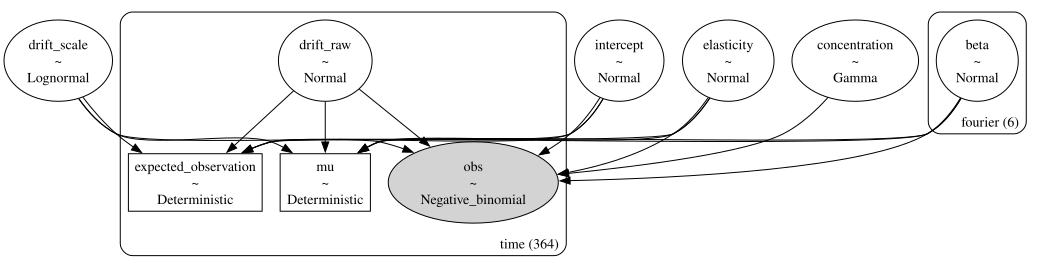

In [10]:
def demand_model(covariates: xr.DataArray, data: xr.DataArray | None = None) -> None:
    """Local level plus weekly seasonality plus price, negative binomial likelihood."""
    h = Horizon.from_data(covariates, data)
    fourier_design = np.ascontiguousarray(
        covariates.sel(covariate=FOURIER_LABELS).values
    )
    log_price = covariates.sel(covariate="log_price").values
    pm.modelcontext(None).add_coord("fourier", FOURIER_LABELS)

    intercept = pm.Normal("intercept", intercept_prior.mu, intercept_prior.sigma)
    beta = pm.Normal("beta", 0.0, 0.3, dims="fourier")
    elasticity = pm.Normal("elasticity", -1.0, 1.0)
    drift_scale = pm.LogNormal("drift_scale", drift_prior.mu, drift_prior.sigma)
    concentration = pm.Gamma(
        "concentration", alpha=concentration_prior.alpha, beta=concentration_prior.beta
    )
    # non-centered increments: the sampler sees standardized drifts
    drift_raw = innovations(h, "drift_raw", pm.Normal.dist(0.0, 1.0))
    level = pt.cumsum(drift_raw * drift_scale)
    log_rate = intercept + level + pt.dot(fourier_design, beta) + elasticity * log_price

    def likelihood(name: str, eta: pt.TensorVariable, dims: tuple[str, ...], observed):
        return pm.NegativeBinomial(
            name, mu=pt.exp(eta), alpha=concentration, dims=dims, observed=observed
        )

    predict(h, likelihood, log_rate, expected_observation=pt.exp(log_rate))


pm.model_to_graphviz(build_model(demand_model, data, covariates_train))

Inside the `time` plate we see `drift_raw`, the standardized increments, next to the observed `obs`, the predictor `mu` and the `expected_observation`. On the training window there is no horizon, so the `time_future` plate does not appear.

## Prior Predictive Checks

Before we fit the model, we draw demand paths from the priors alone and compare them with the training data. The check tells us whether the priors put the demand on the right scale, with room for what the data could show and without absurd values. We build the model on the training window with `build_model` and hand it to `pm.sample_prior_predictive`, which samples the `obs` site over the whole training window.

We plot the $50\%$ and $94\%$ equal-tailed intervals (ETI) of the draws and the observed series on top, on a log axis because the log link gives the prior a long upper tail. An equal-tailed interval runs between two percentiles, for example from the $3$rd to the $97$th percentile for the $94\%$ band. We use it throughout the notebook instead of the highest density interval, because later on we read the band edges as percentiles.

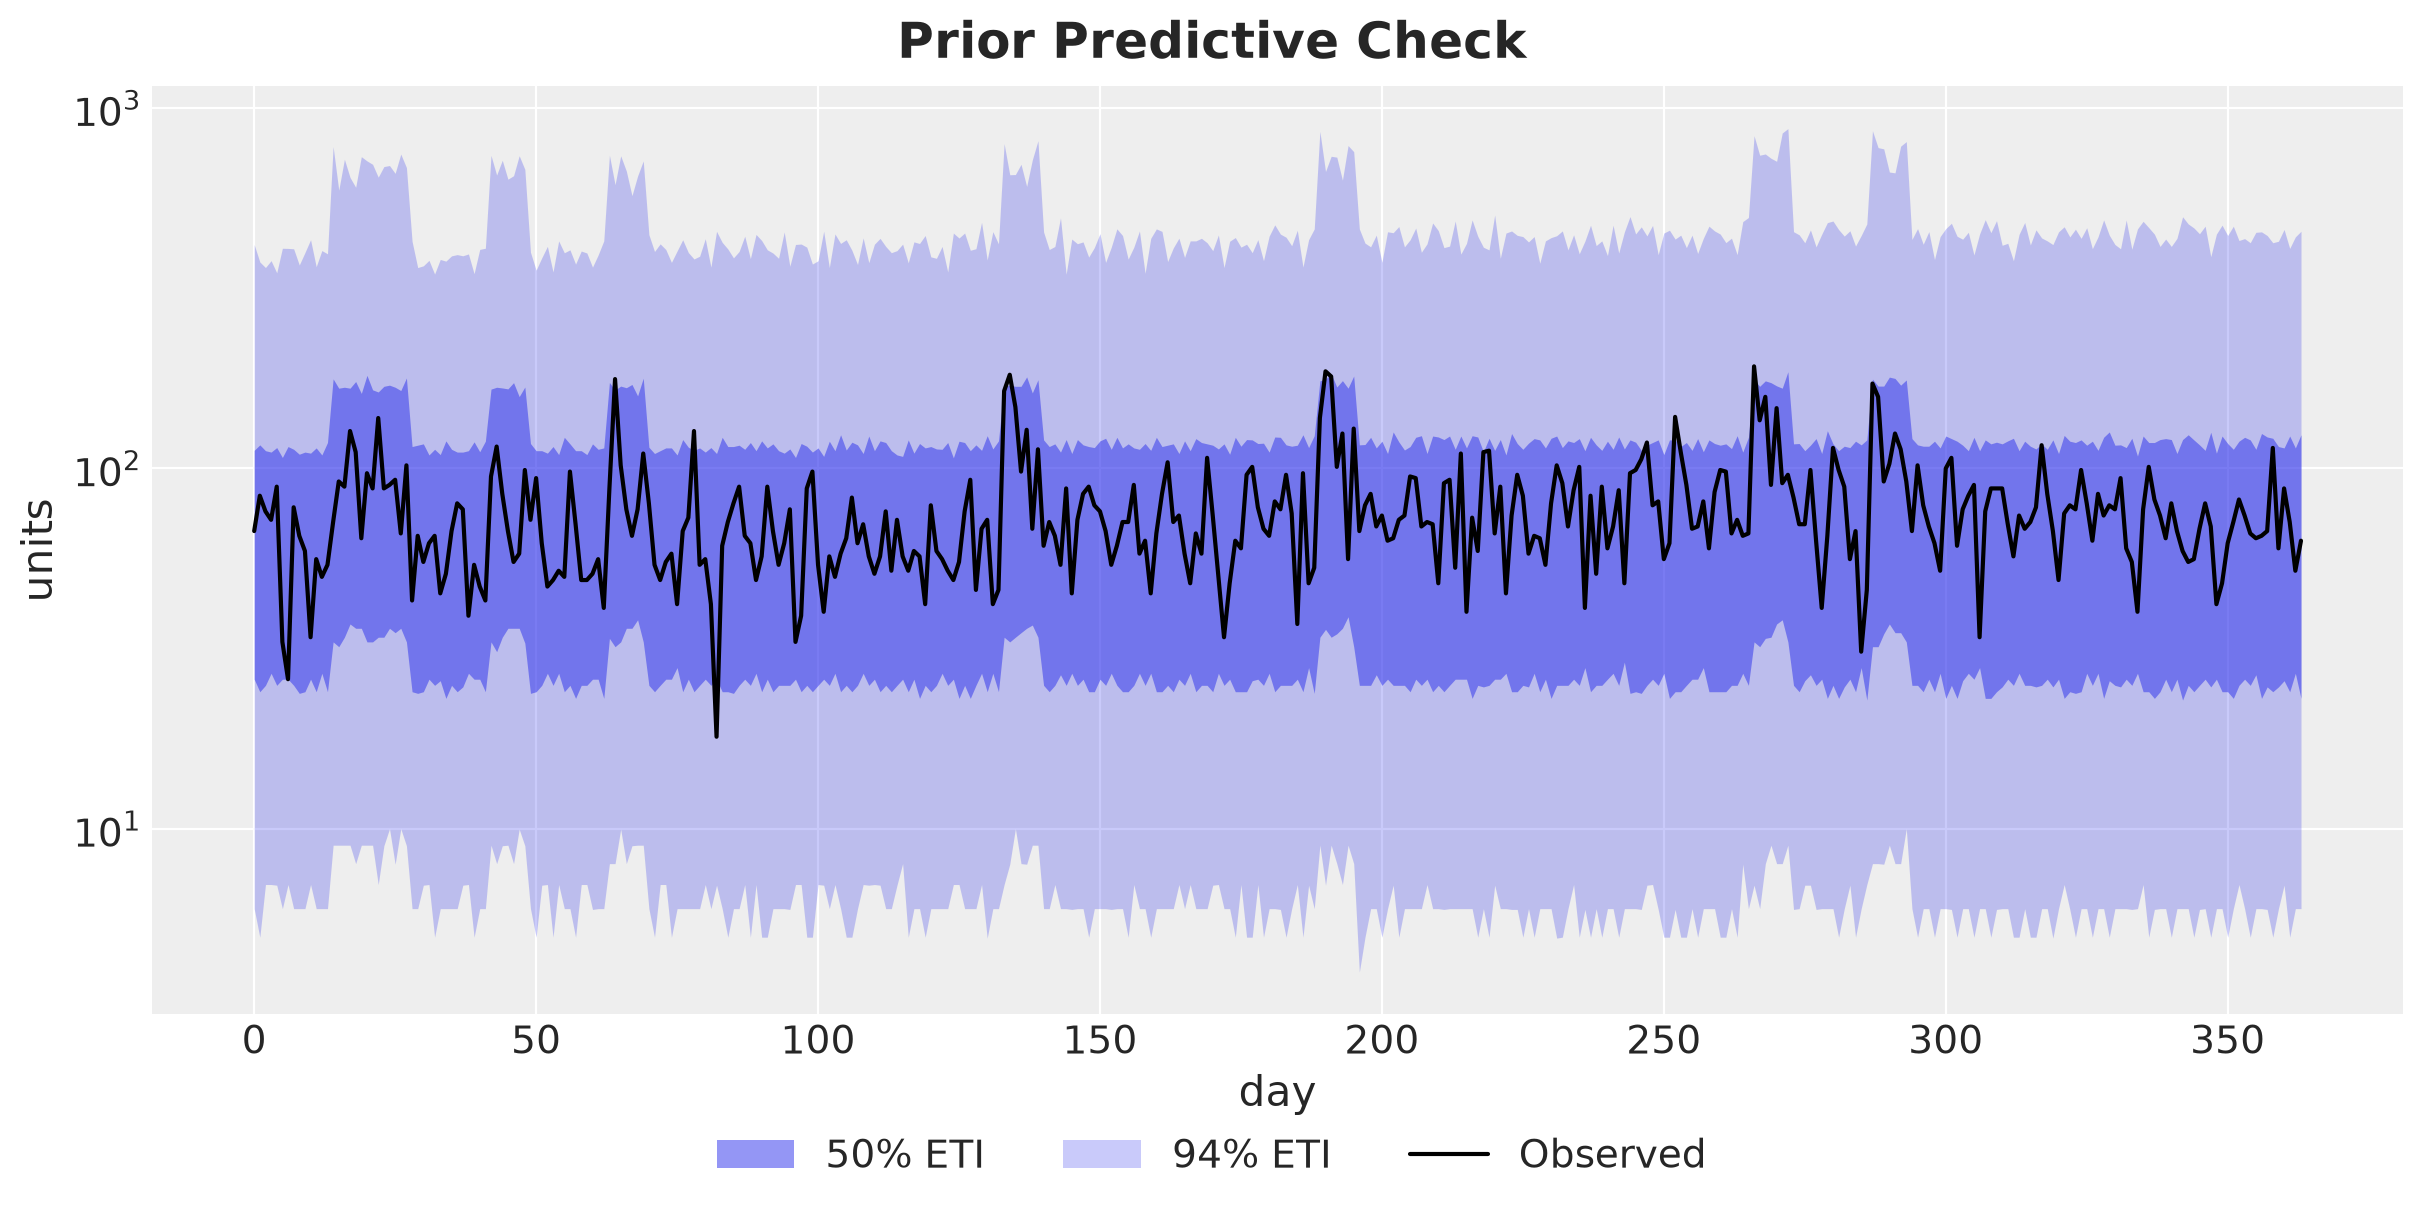

In [11]:
def lighten_bands(pc: az.PlotCollection, x: str) -> None:
    """Set the alpha of the 50% and 94% credible bands of a `plot_lm` collection."""
    bands = pc.viz["ci_band"][x]

    for prob, alpha in [(0.5, 0.5), (HDI_PROB, 0.25)]:
        for band in bands.sel(prob=prob).values.flat:
            band.set_alpha(alpha)


def lm_tree(
    samples: np.ndarray, observed: np.ndarray, x_values: np.ndarray
) -> xr.DataTree:
    """ArviZ container for `plot_lm`: (chain, draw, time) samples, truth and x axis."""
    return az.from_dict(
        {
            "posterior_predictive": {"obs": samples},
            "observed_data": {"obs": observed},
            "constant_data": {"day": x_values.astype(float)},
        },
        coords={"time": x_values},
        dims={"obs": ["time"], "day": ["time"]},
    )


prior_model = build_model(demand_model, data, covariates_train)
prior_idata = pm.sample_prior_predictive(
    draws=1_000, model=prior_model, var_names=["obs"], random_seed=rng
)
prior_tree = lm_tree(
    prior_idata["prior_predictive"]["obs"].values, data.values, days[: setup.t_obs]
)

pc = az.plot_lm(
    prior_tree,
    x="day",
    y="obs",
    y_obs="obs",
    smooth=False,
    ci_kind="eti",
    ci_prob=(0.5, HDI_PROB),
    visuals={
        "ci_band": {"color": "C0"},
        "observed_scatter": False,
        "pe_line": False,
    },
    figure_kwargs={"figsize": (12, 6)},
)
lighten_bands(pc, "day")
ax = pc.viz["plot"]["day"].item()
pc.viz["ci_band"]["day"].sel(prob=HDI_PROB).item().set_label(f"{HDI_PROB:.0%} ETI")
pc.viz["ci_band"]["day"].sel(prob=0.5).item().set_label("50% ETI")
ax.plot(days[: setup.t_obs], data.values, color="black", label="Observed")
ax.set(xlabel="day", ylabel="units", yscale="log")
fig = pc.viz["figure"].item()
fig.legend(loc="outside lower center", ncol=3)
fig.suptitle("Prior Predictive Check", fontsize=18, fontweight="bold");

The priors put the demand on the right scale and not much more. The pooled draws have a median of $57$ units against $70$ for the data, the $94\%$ band runs from $4$ to $10$ units at the bottom to between $350$ and $880$ units at the top depending on the day, and the observed series, between $18$ and $192$ units, stays inside the inner band on $98\%$ of the days.

The bands widen only a little over the year because the uncertainty about the starting level dominates the drift of the random walk. Nothing here is implausible for a product that sells tens of units per day, so we move on to the fit.

## Model Fitting

We now fit the model with NUTS through `fit_mcmc`, which builds the model on the training window and calls `pm.sample`. The result holds the trace as `idata`.

In [12]:
fit = fit_mcmc(
    demand_model,
    data,
    covariates_train,
    draws=DRAWS,
    tune=TUNE,
    chains=CHAINS,
    random_seed=rng,
    sample_kwargs={"target_accept": 0.95},
)
idata = fit.idata

Let's check the sampler diagnostics for the global parameters.

In [13]:
global_params = ["intercept", "beta", "elasticity", "drift_scale", "concentration"]
az.summary(idata, var_names=global_params)

,mean,sd,hdi94_lb,hdi94_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
intercept,4.059,0.052,4,4.2,3665,3070,1.00,0.00086,0.00075
beta[sin_1],0.1793,0.0156,0.15,0.21,7481,3233,1.00,0.00018,0.00025
beta[sin_2],0.0466,0.0158,0.019,0.078,6354,3094,1.00,0.0002,0.00026
beta[sin_3],-0.067,0.0164,-0.1,-0.038,8405,2833,1.00,0.00018,0.0003
beta[cos_1],0.0945,0.0156,0.065,0.12,5209,3177,1.00,0.00022,0.00023
beta[cos_2],0.0681,0.0164,0.037,0.098,8291,2790,1.00,0.00018,0.00033
beta[cos_3],-0.0409,0.0157,-0.071,-0.011,7510,2679,1.00,0.00018,0.00027
elasticity,-1.443,0.09,-1.6,-1.3,6188,3348,1.00,0.0011,0.0014
drift_scale,0.0114,0.0032,0.0062,0.017,2469,2719,1.00,6.5e-05,6.2e-05
concentration,31.84,3.4,26,38,5039,3211,1.00,0.048,0.057


The $\hat{R}$ values are $1.00$ and the effective sample sizes are above $2{,}000$ for every parameter, which is good! Let's also look at the traces.

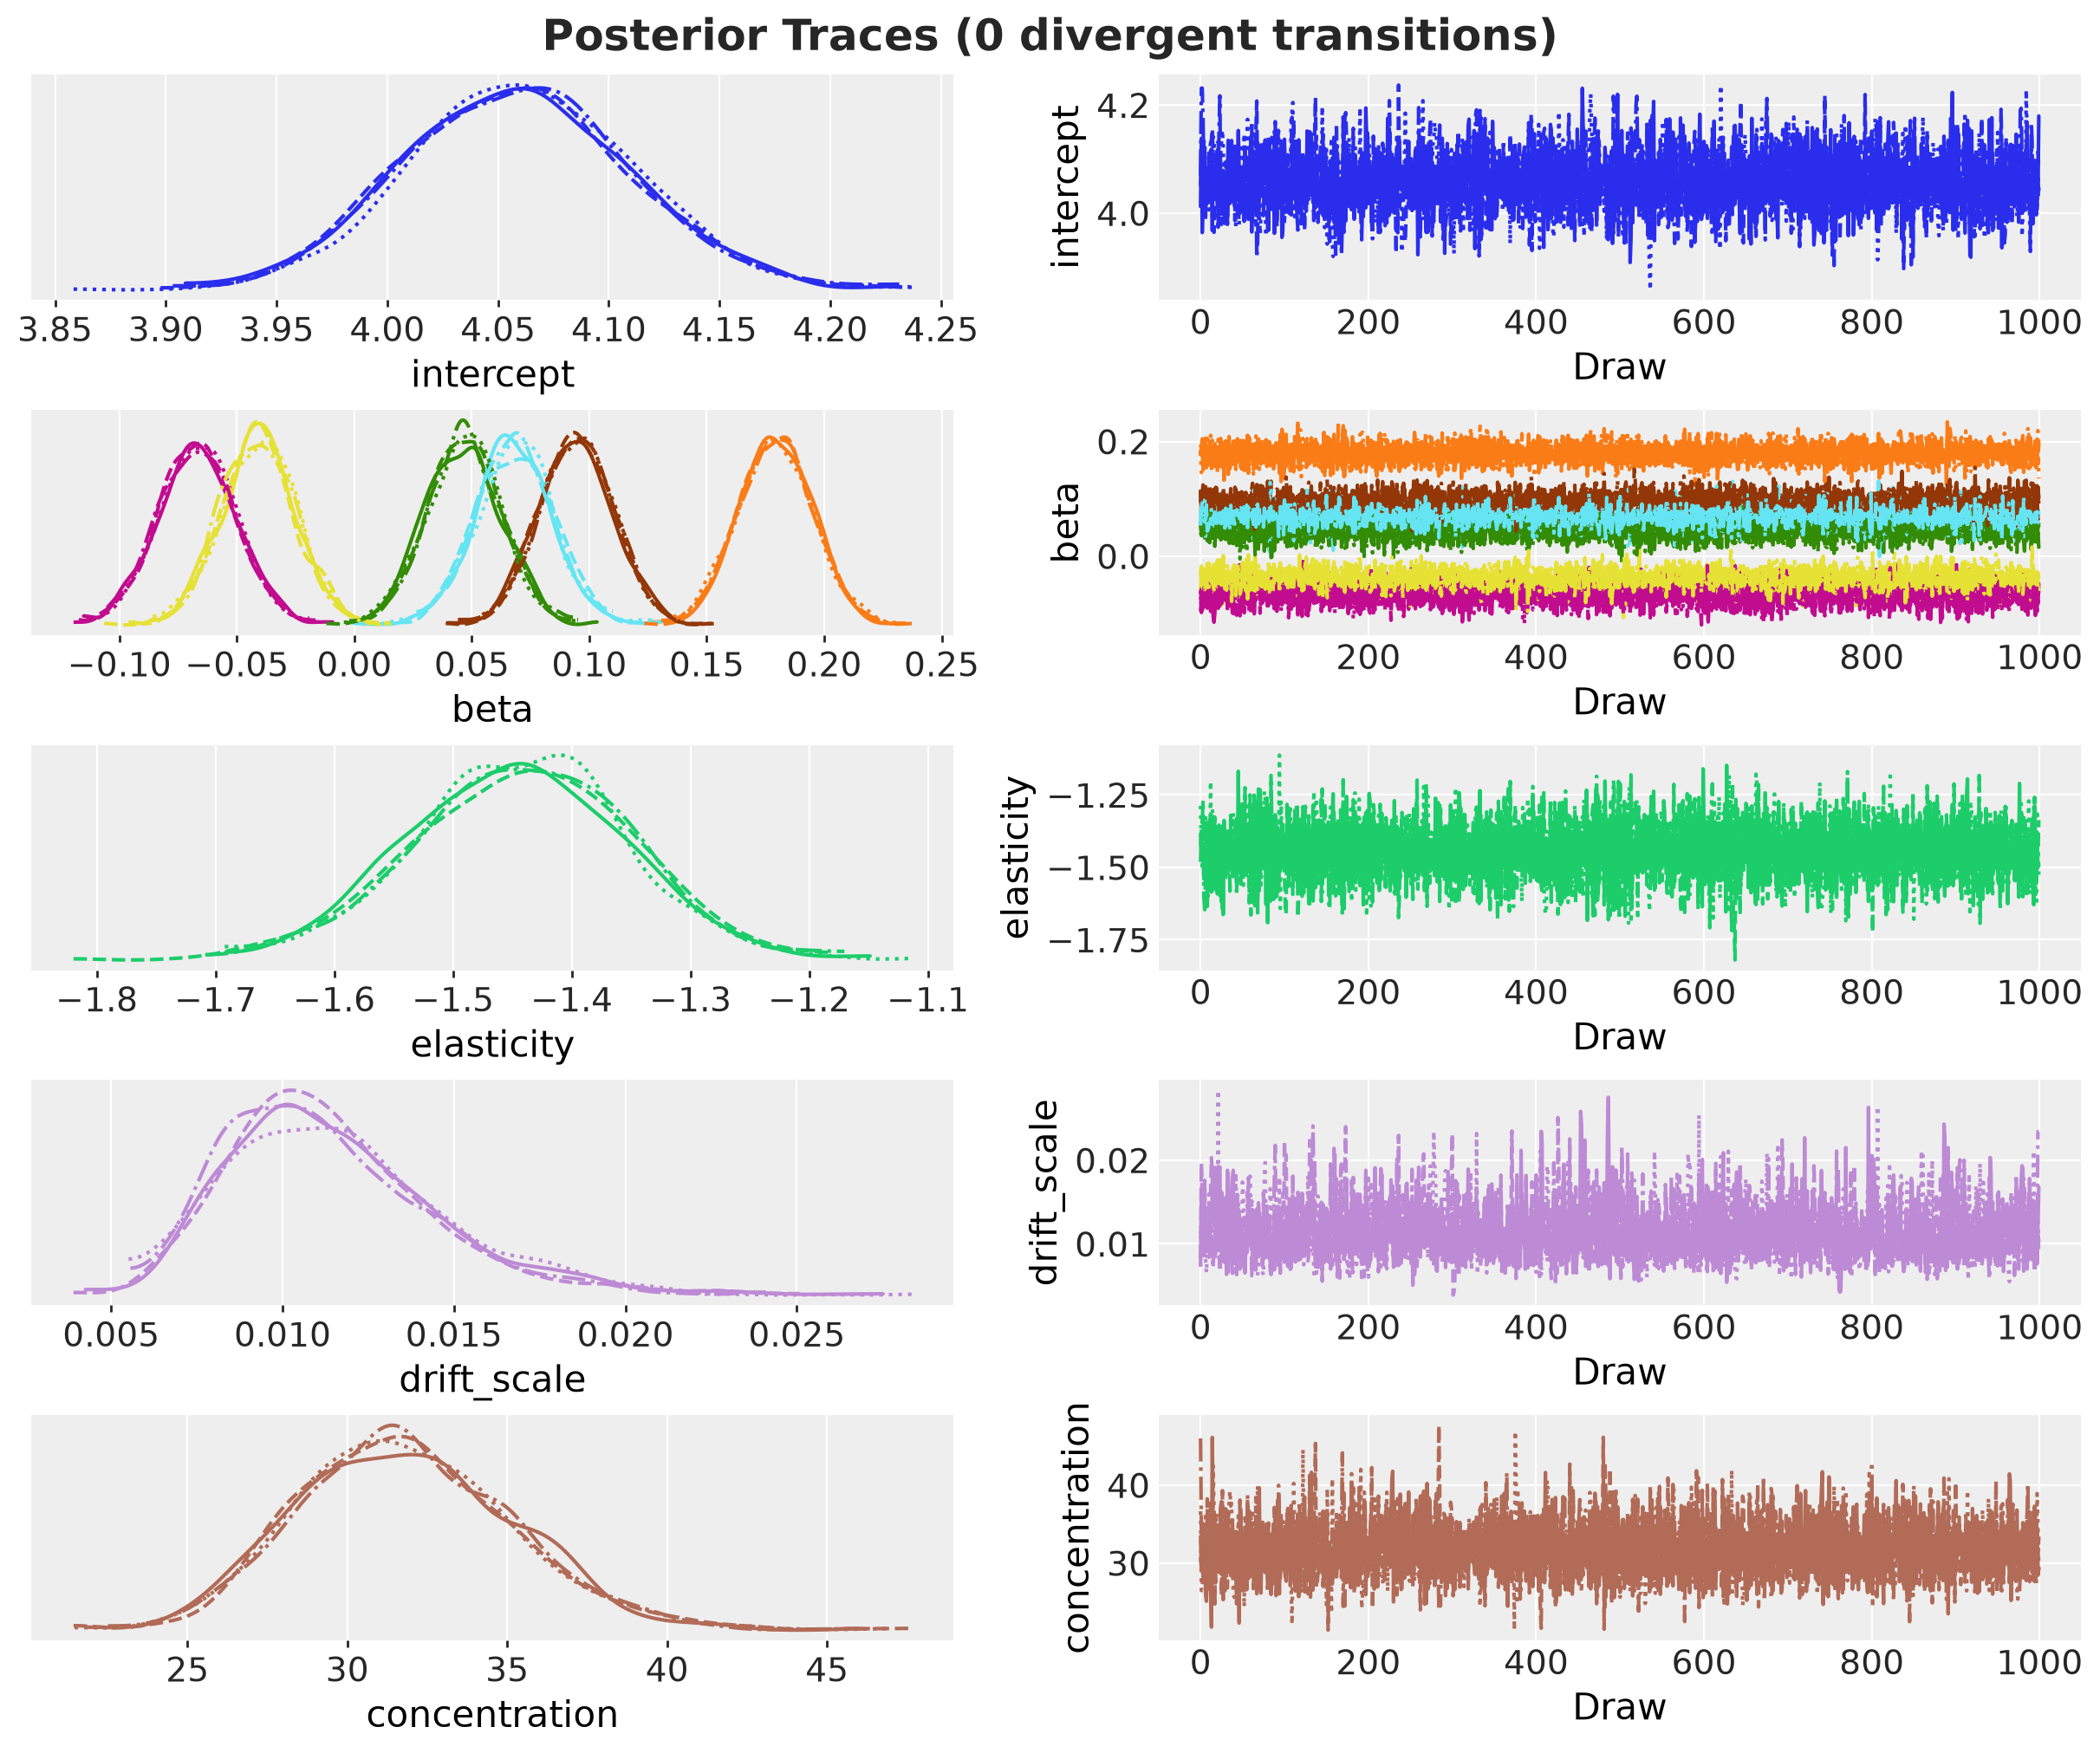

In [14]:
num_divergences = int(idata["sample_stats"]["diverging"].sum())

pc = az.plot_trace_dist(
    idata, var_names=global_params, figure_kwargs={"figsize": (12, 10)}
)
pc.viz["figure"].item().suptitle(
    f"Posterior Traces ({num_divergences} divergent transitions)",
    fontsize=18,
    fontweight="bold",
);

The chains mix well, and the title shows that the sampler had no divergent transitions. Next, we check that the posterior recovers the parameters we fixed in the generator. The vertical lines are the true values.

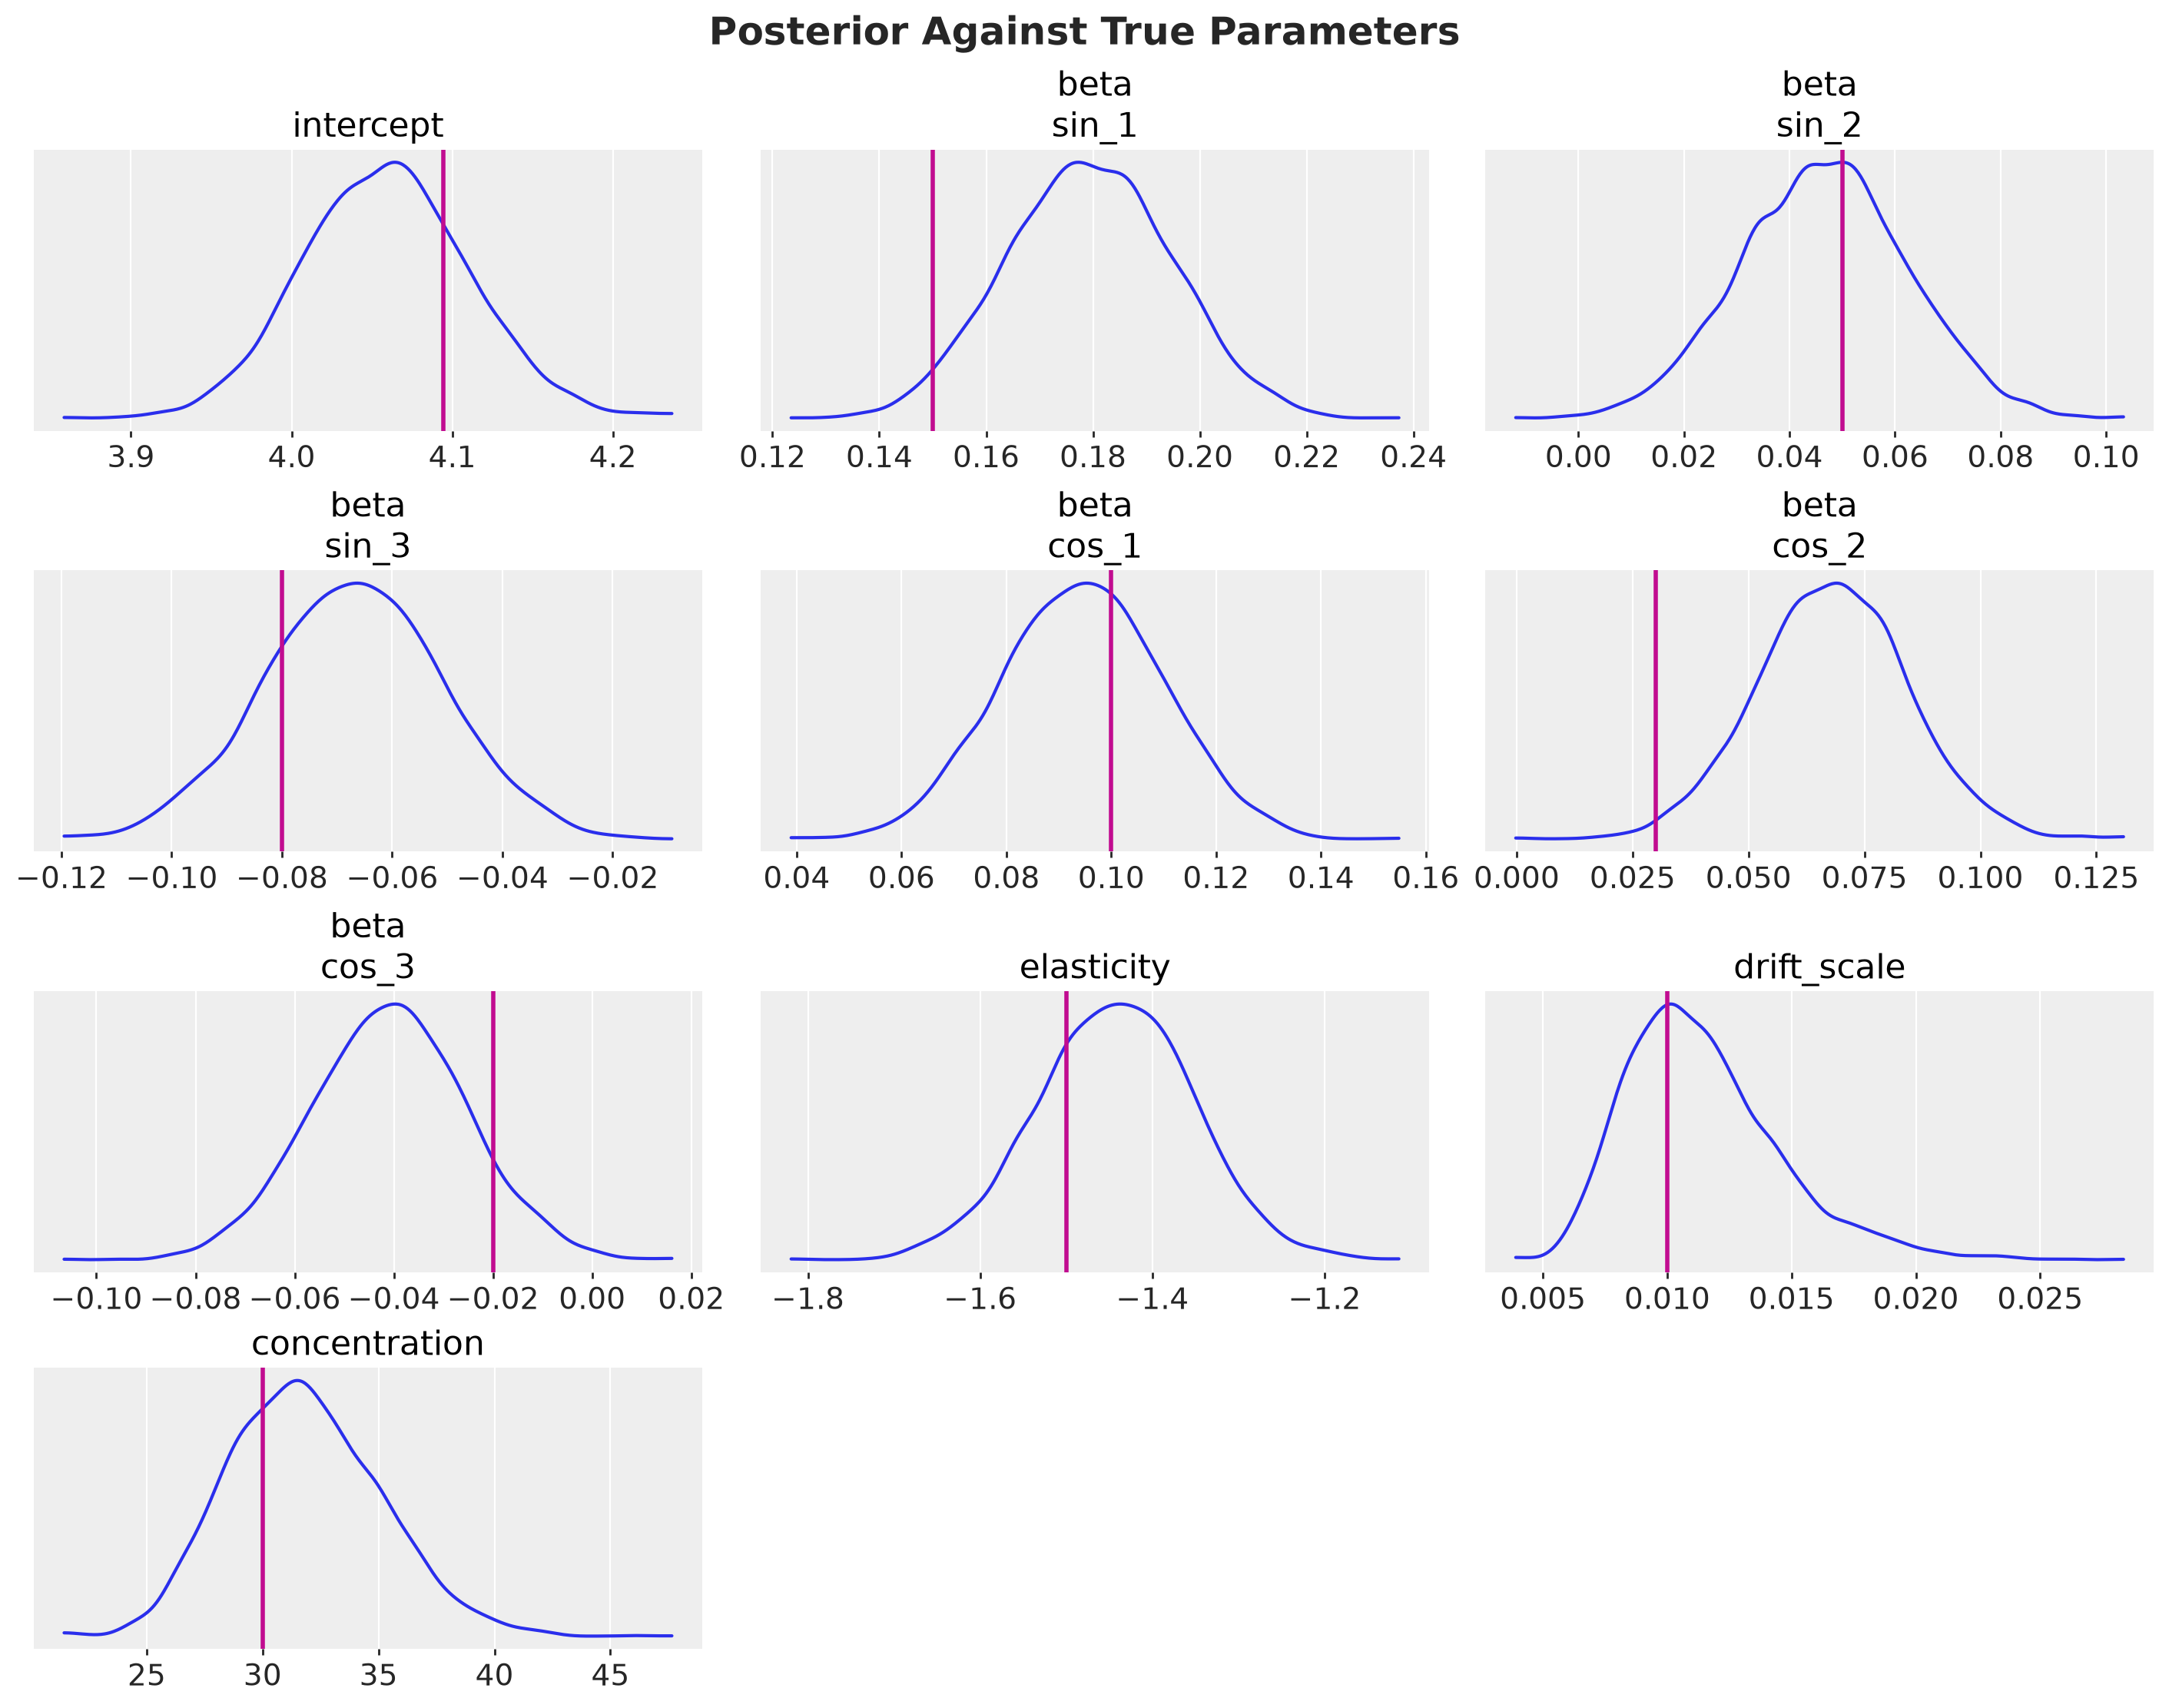

In [15]:
true_values = xr.Dataset(
    {
        "intercept": float(true_params["intercept"]),
        "beta": ("fourier", true_params["beta"]),
        "elasticity": float(true_params["elasticity"]),
        "drift_scale": float(true_params["drift_scale"]),
        "concentration": float(true_params["concentration"]),
    },
    coords={"fourier": FOURIER_LABELS},
)

pc = az.plot_dist(
    idata,
    var_names=global_params,
    kind="kde",
    visuals={
        "point_estimate": False,
        "point_estimate_text": False,
        "credible_interval": False,
    },
    col_wrap=3,
    figure_kwargs={"figsize": (14, 11)},
)
az.add_lines(
    pc,
    values=true_values,
    aes_by_visuals={"ref_line": []},
    visuals={
        "ref_line": {"color": "C3", "linestyle": "-", "linewidth": 2, "zorder": 2}
    },
)
pc.viz["figure"].item().suptitle(
    "Posterior Against True Parameters", fontsize=18, fontweight="bold"
);

The true values sit inside the posterior mass for every parameter but one. The true `beta[cos_2]` of $0.03$ falls in the lower tail of a posterior centered at $0.07$ with a standard deviation of $0.016$, and the true `beta[sin_1]` sits at the lower edge of its density. One year of noisy counts estimates each Fourier coefficient with a standard deviation of about $0.016$, so a miss of two standard deviations on one of six coefficients is within what we expect from a single simulated history. The promotion weeks in the history identify the `elasticity`, so the price covariate is informative over the horizon.

Next, we compare the in-sample posterior predictive distribution with the observed series over the last $90$ days of history. The function `predict_in_sample` replays every posterior draw through the model on the training window. We also compute the continuous ranked probability score (CRPS) of the posterior predictive against the observed series over the whole training window, with `crps_empirical` from `pymc_forecast`. The CRPS generalizes the absolute error to a predictive distribution. It is in the units of the data, and lower is better.

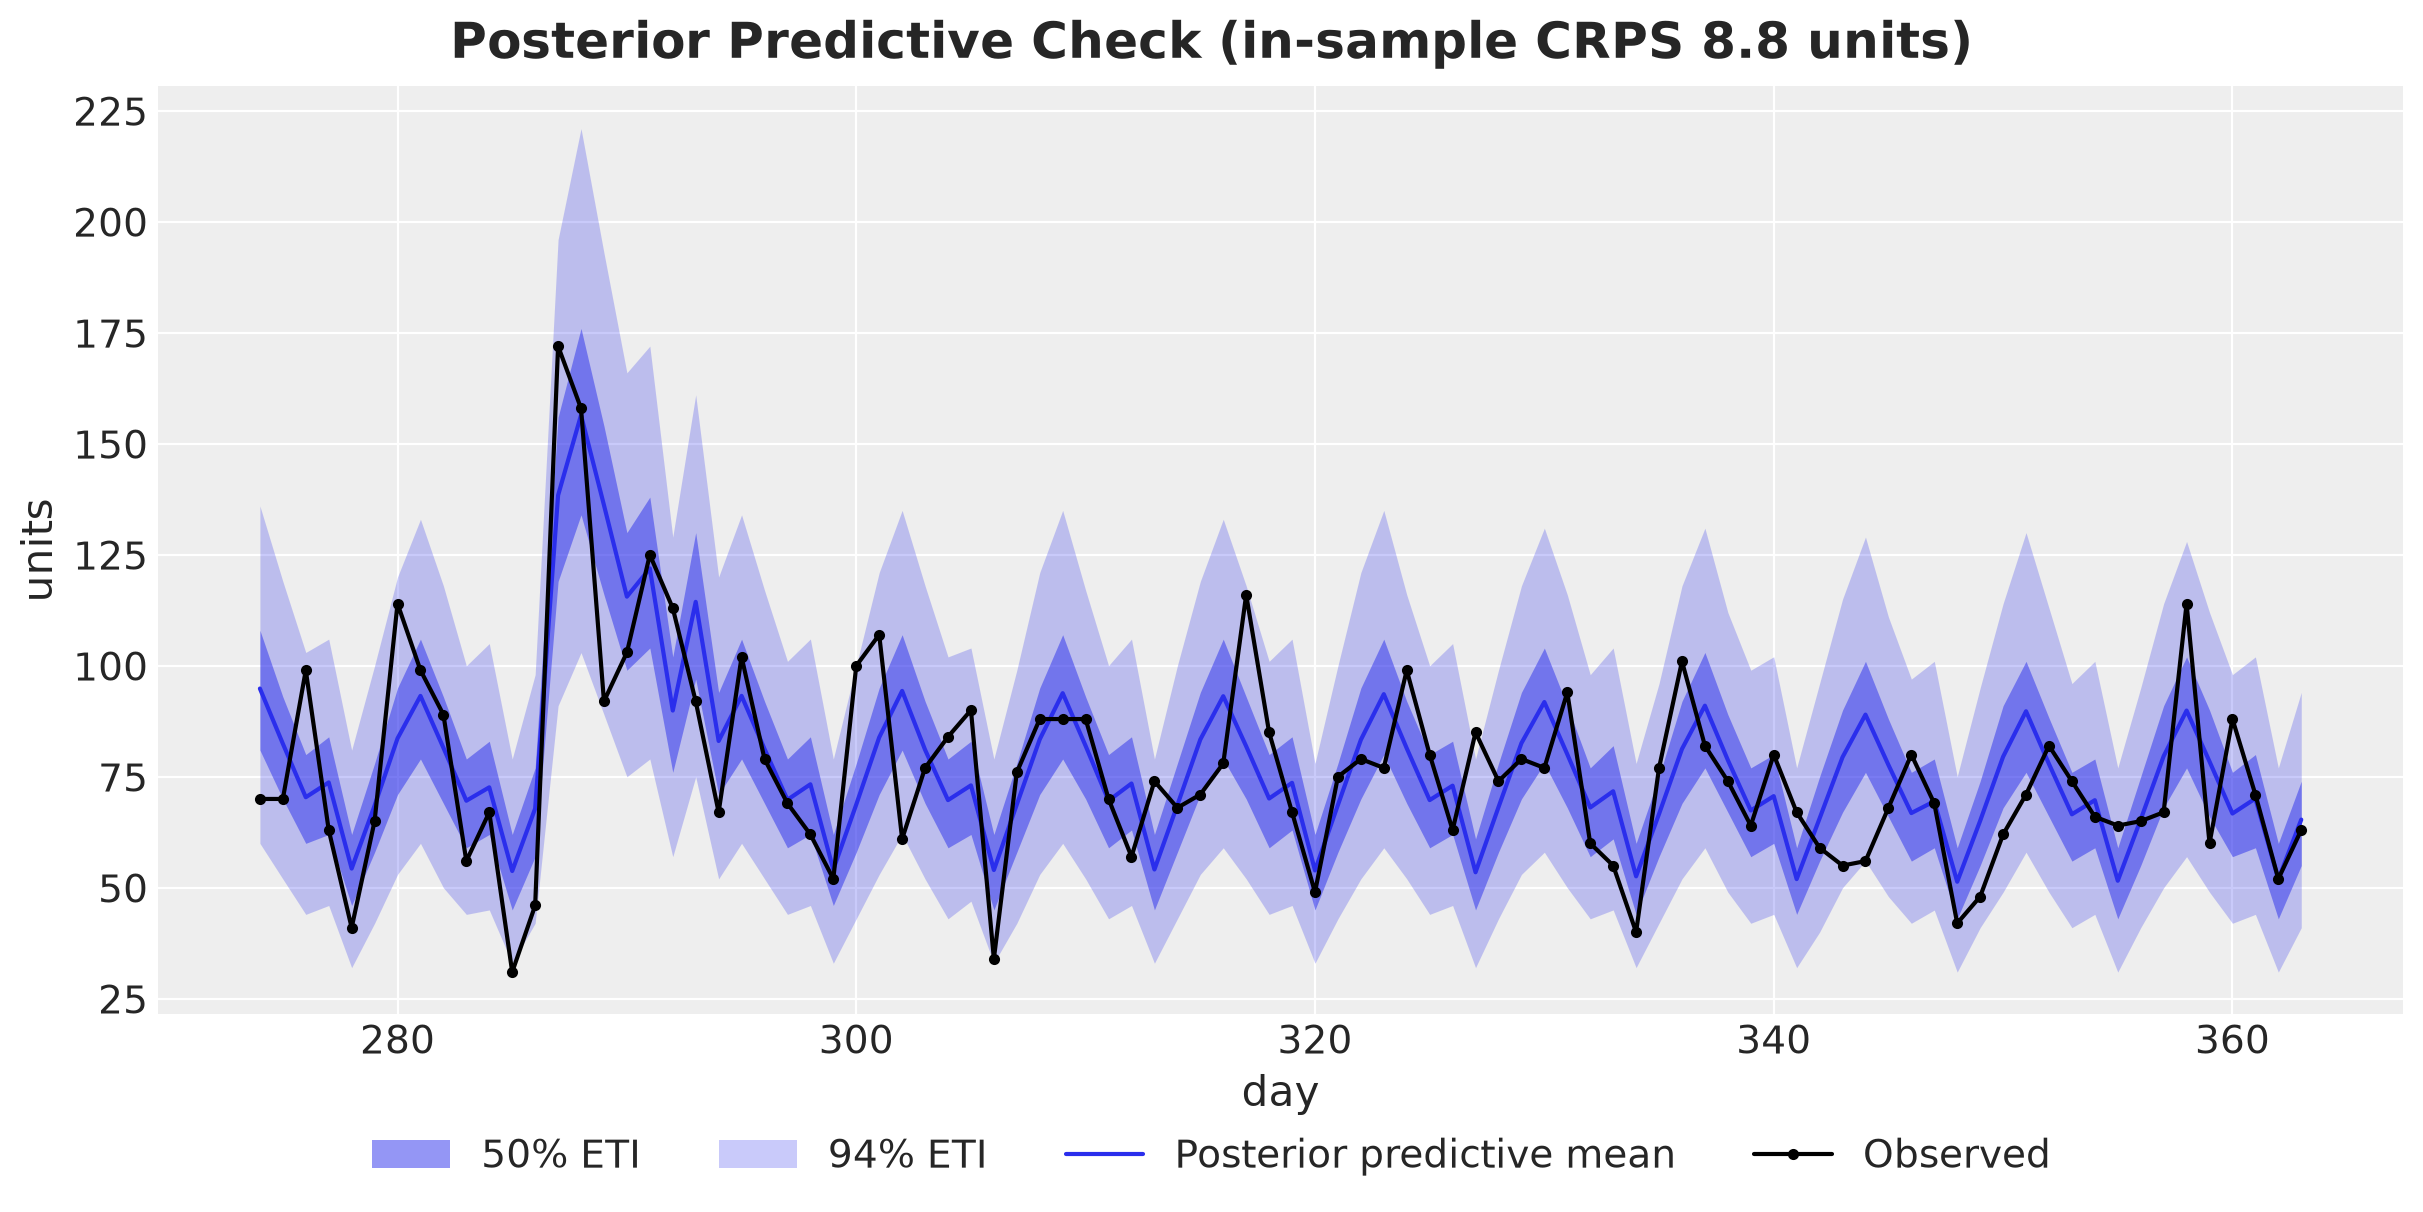

In [16]:
ppc = predict_in_sample(demand_model, idata, data, covariates_train, random_seed=rng)
ppc_obs = ppc["posterior_predictive"]["obs"]
crps_in_sample = float(crps_empirical(ppc_obs, data).mean())

last_quarter = slice(setup.t_obs - 90, setup.t_obs)
ppc_tree = lm_tree(
    ppc_obs.values[:, :, last_quarter], data.values[last_quarter], days[last_quarter]
)

pc = az.plot_lm(
    ppc_tree,
    x="day",
    y="obs",
    y_obs="obs",
    smooth=False,
    ci_kind="eti",
    ci_prob=(0.5, HDI_PROB),
    point_estimate="mean",
    visuals={
        "ci_band": {"color": "C0"},
        "pe_line": {"color": "C0", "alpha": 1.0},
        "observed_scatter": False,
    },
    figure_kwargs={"figsize": (12, 6)},
)
lighten_bands(pc, "day")
ax = pc.viz["plot"]["day"].item()
pc.viz["ci_band"]["day"].sel(prob=HDI_PROB).item().set_label(f"{HDI_PROB:.0%} ETI")
pc.viz["ci_band"]["day"].sel(prob=0.5).item().set_label("50% ETI")
pc.viz["pe_line"]["day"].item().set_label("Posterior predictive mean")
ax.plot(
    days[last_quarter],
    data.values[last_quarter],
    "o-",
    markersize=3,
    color="black",
    label="Observed",
)
ax.set(xlabel="day", ylabel="units", title="")
fig = pc.viz["figure"].item()
fig.legend(loc="outside lower center", ncol=4)
fig.suptitle(
    f"Posterior Predictive Check (in-sample CRPS {crps_in_sample:.1f} units)",
    fontsize=18,
    fontweight="bold",
);

The bands follow the weekly cycle and the promotion weeks, and the wide band covers $87$ of the $90$ observations, close to the nominal $94\%$. The average CRPS of $8.8$ units per day is small against a posterior predictive mean between $41$ and $161$ units. The model is a reasonable description of the history, so let's move to the horizon.

## Demand Scenarios

Now that we have a fitted model, let's turn its posterior predictive distribution over the horizon into the demand scenarios of the *Decision Problem* section.

### Data Preparation

The function `forecast` rebuilds the model on the full covariates, so the horizon is the part of the covariate index beyond the training window, and it draws the horizon from every posterior draw. It returns the forecast draws as `forecast` in the `predictions` group, with dims `(chain, draw, time_future)`. We flatten the sample dimensions into a scenario matrix of shape $(N, H)$, where each row is one *joint* draw of the $15$ days. These rows are the scenarios of the *Decision Problem* section.

We then shuffle the rows and split them into two sets. The first $1{,}000$ scenarios are the **optimization set**, and every plan is built on them. The remaining $3{,}000$ scenarios are the **evaluation set**, which no plan sees.

We need the split because a plan fitted to a finite set of scenarios adapts to that set, so its loss on the same scenarios is usually optimistic. The held-out scenarios tell us how the plan does on new draws from the same forecast. We also keep the mean demand path of the optimization set, which several figures use.

Note that the plots keep the day index of the series, so the horizon runs from day $364$ to day $378$. This corresponds to the $15$-day horizon.

In [17]:
forecast_idata = forecast(demand_model, idata, data, covariates, random_seed=rng)
forecast_draws = forecast_idata["predictions"]["forecast"]

scenarios = (
    forecast_draws.stack(sample=("chain", "draw"))
    .transpose("sample", FUTURE_DIM)
    .values.astype("float64")
)
scenarios = scenarios[rng.permutation(scenarios.shape[0])]
demand_opt, demand_eval = scenarios[:N_SCENARIOS_OPT], scenarios[N_SCENARIOS_OPT:]
mean_demand_opt = demand_opt.mean(axis=0)

### Scenario Visualization

We plot the forecast as a fan over the horizon, next to the last $60$ days of history. The shaded column is the promotion week in the horizon.

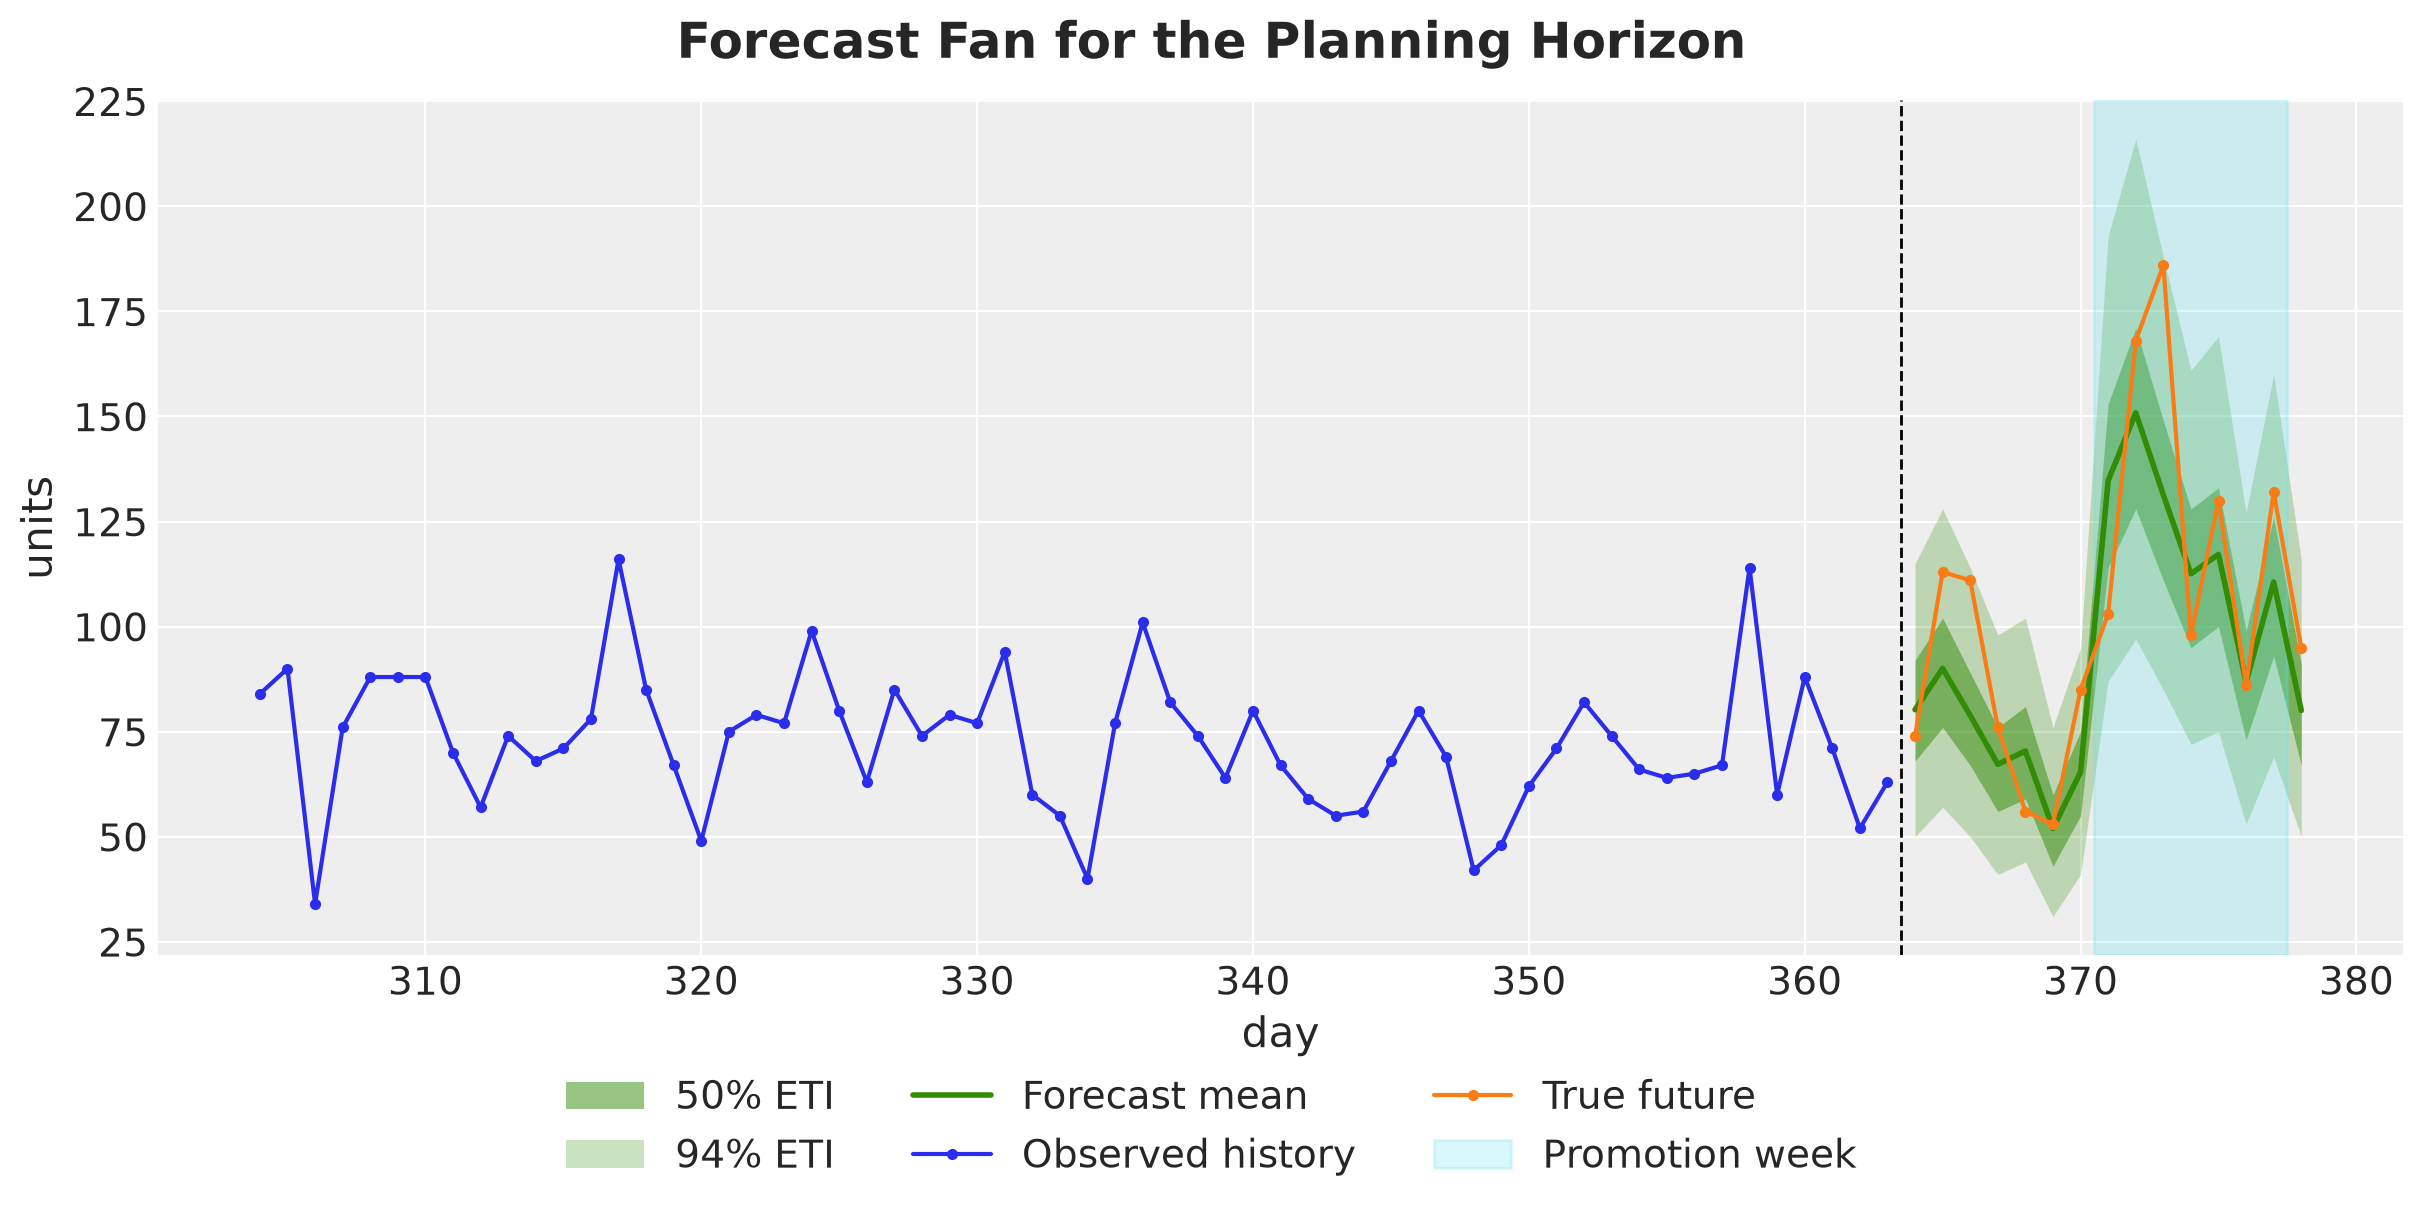

In [18]:
def shade_promotion(ax: plt.Axes) -> None:
    """Shade the promotion days of the horizon."""
    ax.axvspan(
        promo_days_future[0] - 0.5,
        promo_days_future[-1] + 0.5,
        color="C5",
        alpha=0.25,
        label="Promotion week",
    )


forecast_tree = lm_tree(forecast_draws.values, demand_future_true, days_future)

pc = az.plot_lm(
    forecast_tree,
    x="day",
    y="obs",
    y_obs="obs",
    smooth=False,
    ci_kind="eti",
    ci_prob=(0.5, HDI_PROB),
    point_estimate="mean",
    visuals={
        "ci_band": {"color": "C2"},
        "pe_line": {"color": "C2", "alpha": 1.0, "linewidth": 2},
        "observed_scatter": False,
    },
    figure_kwargs={"figsize": (12, 6)},
)
lighten_bands(pc, "day")
ax = pc.viz["plot"]["day"].item()
pc.viz["ci_band"]["day"].sel(prob=HDI_PROB).item().set_label(f"{HDI_PROB:.0%} ETI")
pc.viz["ci_band"]["day"].sel(prob=0.5).item().set_label("50% ETI")
pc.viz["pe_line"]["day"].item().set_label("Forecast mean")
last_two_months = slice(setup.t_obs - 60, setup.t_obs)
ax.plot(
    days[last_two_months],
    data.values[last_two_months],
    "o-",
    markersize=3,
    color="C0",
    label="Observed history",
)
ax.plot(
    days_future,
    demand_future_true,
    "o-",
    markersize=3,
    color="C1",
    label="True future",
)
ax.axvline(setup.t_obs - 0.5, color="black", linestyle="--", linewidth=1)
shade_promotion(ax)
ax.set(xlabel="day", ylabel="units", title="")
fig = pc.viz["figure"].item()
fig.legend(loc="outside lower center", ncol=3)
fig.suptitle("Forecast Fan for the Planning Horizon", fontsize=18, fontweight="bold");

The fan follows the weekly cycle and jumps in the promotion week because the model knows the price path. It widens slowly with the horizon because the level keeps drifting. The true future stays inside the wide band. Next, we look at $30$ individual scenarios from the optimization set, the paths that the optimizer sees.

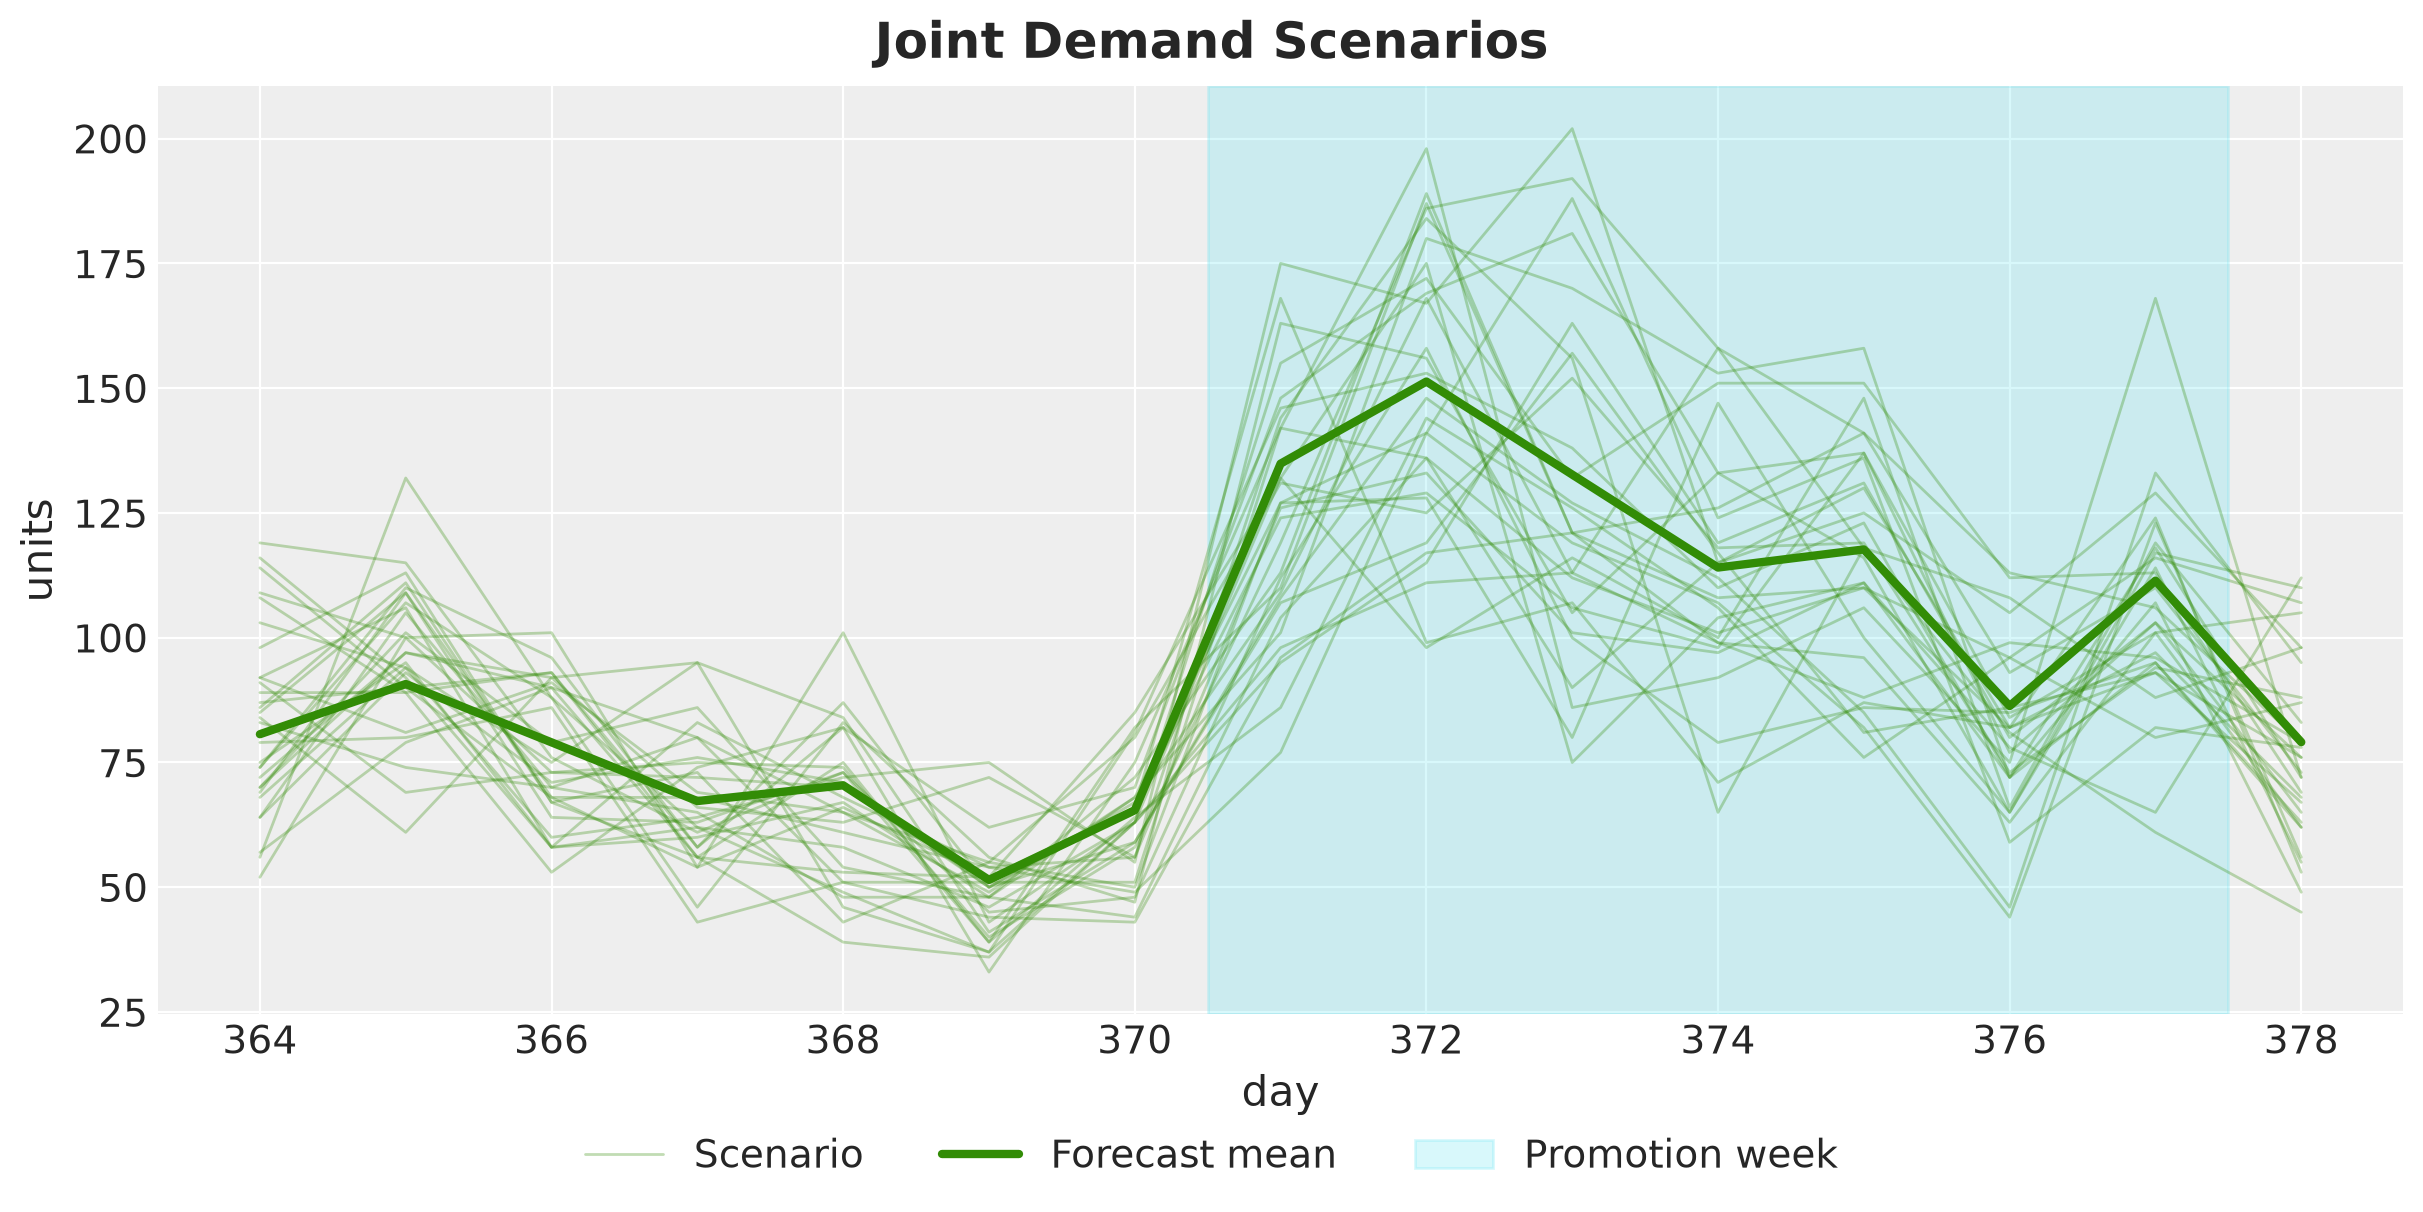

In [19]:
fig, ax = plt.subplots(figsize=(12, 6))
lines = ax.plot(days_future, demand_opt[:30].T, color="C2", alpha=0.3, linewidth=1)
lines[0].set_label("Scenario")
ax.plot(days_future, mean_demand_opt, color="C2", linewidth=3, label="Forecast mean")
shade_promotion(ax)
fig.legend(loc="outside lower center", ncol=3)
ax.set(xlabel="day", ylabel="units")
fig.suptitle("Joint Demand Scenarios", fontsize=18, fontweight="bold");

Each path is one joint draw of the $15$ days. A plan is scored against each path, and the decision rule aggregates the scores.

The paths have to be joint draws for two reasons. First, the stock that a scenario carries into day $t$ is what is left of the earlier days of the same scenario. Second, the days of one path share the same level and the same parameters.

Two consecutive days are only weakly linked, but the stock carried into day $t$ depends on the demand of all the earlier days, and a path with high demand on the earlier days tends to have high demand on day $t$ too. In the *Out of Sample Evaluation* section we check what happens to a plan built on scenarios without this link.

## Inventory Simulator

We now turn the loss $L(a, D)$ and the plans into code. In this section we write the forward pass of the *Decision Rules* section, with an order rule for each plan that the forward pass builds, and the simulator.

- The forward pass carries the stock of every scenario through the days of the horizon and asks an **order rule** for the order of each day. On each day, the rule of the chance-constrained plan returns the order that covers the shortfall in a given fraction of the scenarios. The rule of the mean forecast plan returns the shortfall of the mean path.

- The simulator runs a plan against a demand path and returns the loss.

To make these more tangible, we build the mean forecast plan and test the simulator on it.

Let's start with the forward pass. The function `forward_pass` walks through the days of the horizon inside all the scenarios at once. On day $t$ it computes the shortfall $D_t - I_{t-1}$ of every scenario, hands the vector of shortfalls to the order rule, clips the order at zero, and carries the leftover stock of every scenario into the next day. Recall that this is a computation on the scenarios, not a sequence of decisions on observed sales: the function returns the full vector of $15$ orders, and we place them all today.

The order rule is a function that maps the shortfalls across the scenarios to one order, and the `OrderRule` protocol fixes this signature. We write two rules. The function `quantile_shortfall(prob, num_scenarios)` returns the rule that orders the `prob` quantile of the shortfall, which gives the chance-constrained plan at `prob = 1 - ALPHA` and the myopic newsvendor plan at the critical fractile. The function `follow_path` orders the shortfall of a single path, which gives the mean forecast plan on the mean path.

**Remark:** The function `forward_pass` is in essence a "for loop" over the days. In PyTensor, we write it with [`pytensor.scan`](https://pytensor.readthedocs.io/en/latest/library/scan.html): the step function receives the demand of the current day and the stock carried by every scenario, and `scan` runs the whole loop as one operation of the graph. We then compile the graph with `pytensor.function`, with the demand matrix as an input, so the same compiled function serves any set of scenarios. The carry is a vector with one entry per scenario, so the loop is vectorized over scenarios by construction. The same holds for the simulator below.

We can now reason about this process for the mean forecast plan. Observe that the mean forecast plan is simply the forward pass with the rule `follow_path` on a single path, the mean of the optimization scenarios. Against the mean path the plan leaves nothing on the shelf: the initial stock of $50$ units covers part of day one, the first order covers the rest, and from day two on each order equals the mean demand of its day.

In [20]:
class OrderRule(Protocol):
    """Maps the shortfall D_t - I_{t-1} of every scenario to the order of day t."""

    def __call__(self, shortfall: pt.TensorVariable) -> pt.TensorVariable: ...


def follow_path(shortfall: pt.TensorVariable) -> pt.TensorVariable:
    """Order the shortfall of a single demand path, here the mean path."""
    return shortfall[0]


def quantile_shortfall(prob: float, num_scenarios: int) -> OrderRule:
    """The rule that orders the `prob` quantile of the shortfall across the scenarios.

    The quantile is the smallest sample value with at least a fraction `prob` of the
    scenarios at or below it, the `ceil(prob * N)`-th smallest shortfall, so on every
    day the plan covers the shortfall of at least a fraction `prob` of the scenarios
    with the smallest possible order.
    """
    index = math.ceil(prob * num_scenarios) - 1

    def rule(shortfall: pt.TensorVariable) -> pt.TensorVariable:
        return pt.sort(shortfall)[index]

    return rule


def forward_pass(
    demand: np.ndarray, order_rule: OrderRule, config: InventoryConfig
) -> np.ndarray:
    """Daily orders from an order rule applied to the shortfall of every day.

    Parameters
    ----------
    demand : np.ndarray
        The demand path of the scenarios, shape (scenarios, horizon).
    order_rule : OrderRule
        Maps the shortfall D_t - I_{t-1} across the scenarios to the order of day t.
    config : InventoryConfig
        The inventory configuration.

    Returns
    -------
    orders : np.ndarray
        The orders of the plan, shape (horizon,).
    """
    demand_sym = pt.dmatrix("demand")

    def step(demand_t: pt.TensorVariable, inventory: pt.TensorVariable) -> tuple:
        shortfall = demand_t - inventory
        order_t = pt.maximum(order_rule(shortfall), 0.0)
        inventory = pt.maximum(inventory + order_t - demand_t, 0.0)
        return inventory, order_t

    initial_inventory = pt.full(
        (demand_sym.shape[0],), config.initial_inventory, dtype="float64"
    )
    _, orders = pytensor.scan(
        step,
        sequences=[demand_sym.T],
        outputs_info=[initial_inventory, None],
        return_updates=False,
    )
    return pytensor.function([demand_sym], orders)(np.asarray(demand, dtype="float64"))


orders_mean = forward_pass(mean_demand_opt[None, :], follow_path, config)
assert orders_mean.shape == (setup.horizon,)

Next, let's write the simulator. Each step sells what it can, records the lost sales and the leftover, and charges the two costs. The function `simulation_graph` builds the scan and returns three symbolic outputs, the loss, the stock path and the lost sales path, since the evaluation needs all three. We compile it once with `pytensor.function` into `simulate_scenarios`, which returns the three arrays in a `Simulation` tuple.

We keep the graph builder separate from the compiled function on purpose. The optimizer of the *Decision Plans* section calls `simulation_graph` on symbolic orders, so that the loss and its gradient with respect to the orders live on the same graph.

We test the simulator by scoring the mean forecast plan on the optimization scenarios. On the mean path itself the loss of this plan is zero by construction, as we said above: the stock ends every day at zero and no sale is lost. The mean path is one path, and we score the plan on each of the $1{,}000$ scenarios one at a time. In any one scenario the demand of a day is above or below the mean demand of that day. If it is below, part of the order sized for the mean is left over and pays holding cost. If it is above, the plan can run out and pay the margin on the lost sales. So the loss is positive in every scenario, and so is its average over the scenarios.

In [21]:
class Simulation(NamedTuple):
    """Loss, stock path and lost sales path of one plan against the demand paths."""

    loss: np.ndarray  # (scenarios,)
    inventory: np.ndarray  # (scenarios, horizon)
    lost_sales: np.ndarray  # (scenarios, horizon)


def simulation_graph(
    orders: pt.TensorVariable, demand: pt.TensorVariable, config: InventoryConfig
) -> tuple[pt.TensorVariable, pt.TensorVariable, pt.TensorVariable]:
    """The inventory dynamics of one plan against every scenario, as a PyTensor graph.

    Parameters
    ----------
    orders : pt.TensorVariable
        The plan, shape (horizon,).
    demand : pt.TensorVariable
        The demand paths, shape (scenarios, horizon).
    config : InventoryConfig
        The inventory configuration.

    Returns
    -------
    loss, inventory, lost_sales : pt.TensorVariable
        The loss of every scenario, shape (scenarios,), and the stock on hand and the
        lost sales of every scenario and day, shape (scenarios, horizon).
    """

    def step(
        order_t: pt.TensorVariable,
        demand_t: pt.TensorVariable,
        inventory: pt.TensorVariable,
    ) -> tuple:
        available = inventory + order_t  # y_t
        sales_t = pt.minimum(available, demand_t)
        lost_t = demand_t - sales_t
        inventory = available - sales_t
        cost_t = config.holding_cost * inventory + config.lost_sales_cost * lost_t
        return inventory, lost_t, cost_t

    initial_inventory = pt.full(
        (demand.shape[0],), config.initial_inventory, dtype="float64"
    )
    inventory_path, lost_path, cost_path = pytensor.scan(
        step,
        sequences=[orders, demand.T],
        outputs_info=[initial_inventory, None, None],
        return_updates=False,
    )
    return cost_path.sum(axis=0), inventory_path.T, lost_path.T


orders_sym = pt.dvector("orders")
demand_sym = pt.dmatrix("demand")
simulate_fn = pytensor.function(
    [orders_sym, demand_sym], list(simulation_graph(orders_sym, demand_sym, config))
)


def simulate_scenarios(orders: np.ndarray, demand: np.ndarray) -> Simulation:
    """Run the compiled simulator of one plan against a matrix of demand paths."""
    return Simulation(
        *simulate_fn(
            np.asarray(orders, dtype="float64"), np.asarray(demand, dtype="float64")
        )
    )


losses_mean_plan = simulate_scenarios(orders_mean, demand_opt).loss

We summarize the loss of a plan over the scenarios with the two quantities of the *Decision Rules* section, the expected loss and the conditional value at risk.

- The expected loss is a plain mean.

- The conditional value at risk needs a helper function: with $N$ equally weighted scenarios it is the mean of the $k = \alpha N$ largest losses, which we read off the sorted losses. The function works on a numpy array of losses, to score plans, and on a PyTensor variable, inside the objective of the CVaR plan in the next section, where `pt.sort` takes the place of `np.sort`.

In [22]:
def tail_size(num_scenarios: int) -> int:
    """The integer k = ALPHA * N, a Python integer that indexes the sorted losses."""
    return max(1, round(ALPHA * num_scenarios))


def cvar(
    losses: np.ndarray | pt.TensorVariable, k: int
) -> np.floating | pt.TensorVariable:
    """Mean of the k largest losses, for a numpy array or a PyTensor variable."""
    sort = pt.sort if isinstance(losses, pt.TensorVariable) else np.sort
    return sort(losses)[-k:].mean()

Let's plot the distribution of the loss of the mean forecast plan and mark the expected loss, the value at risk and the conditional value at risk on it.

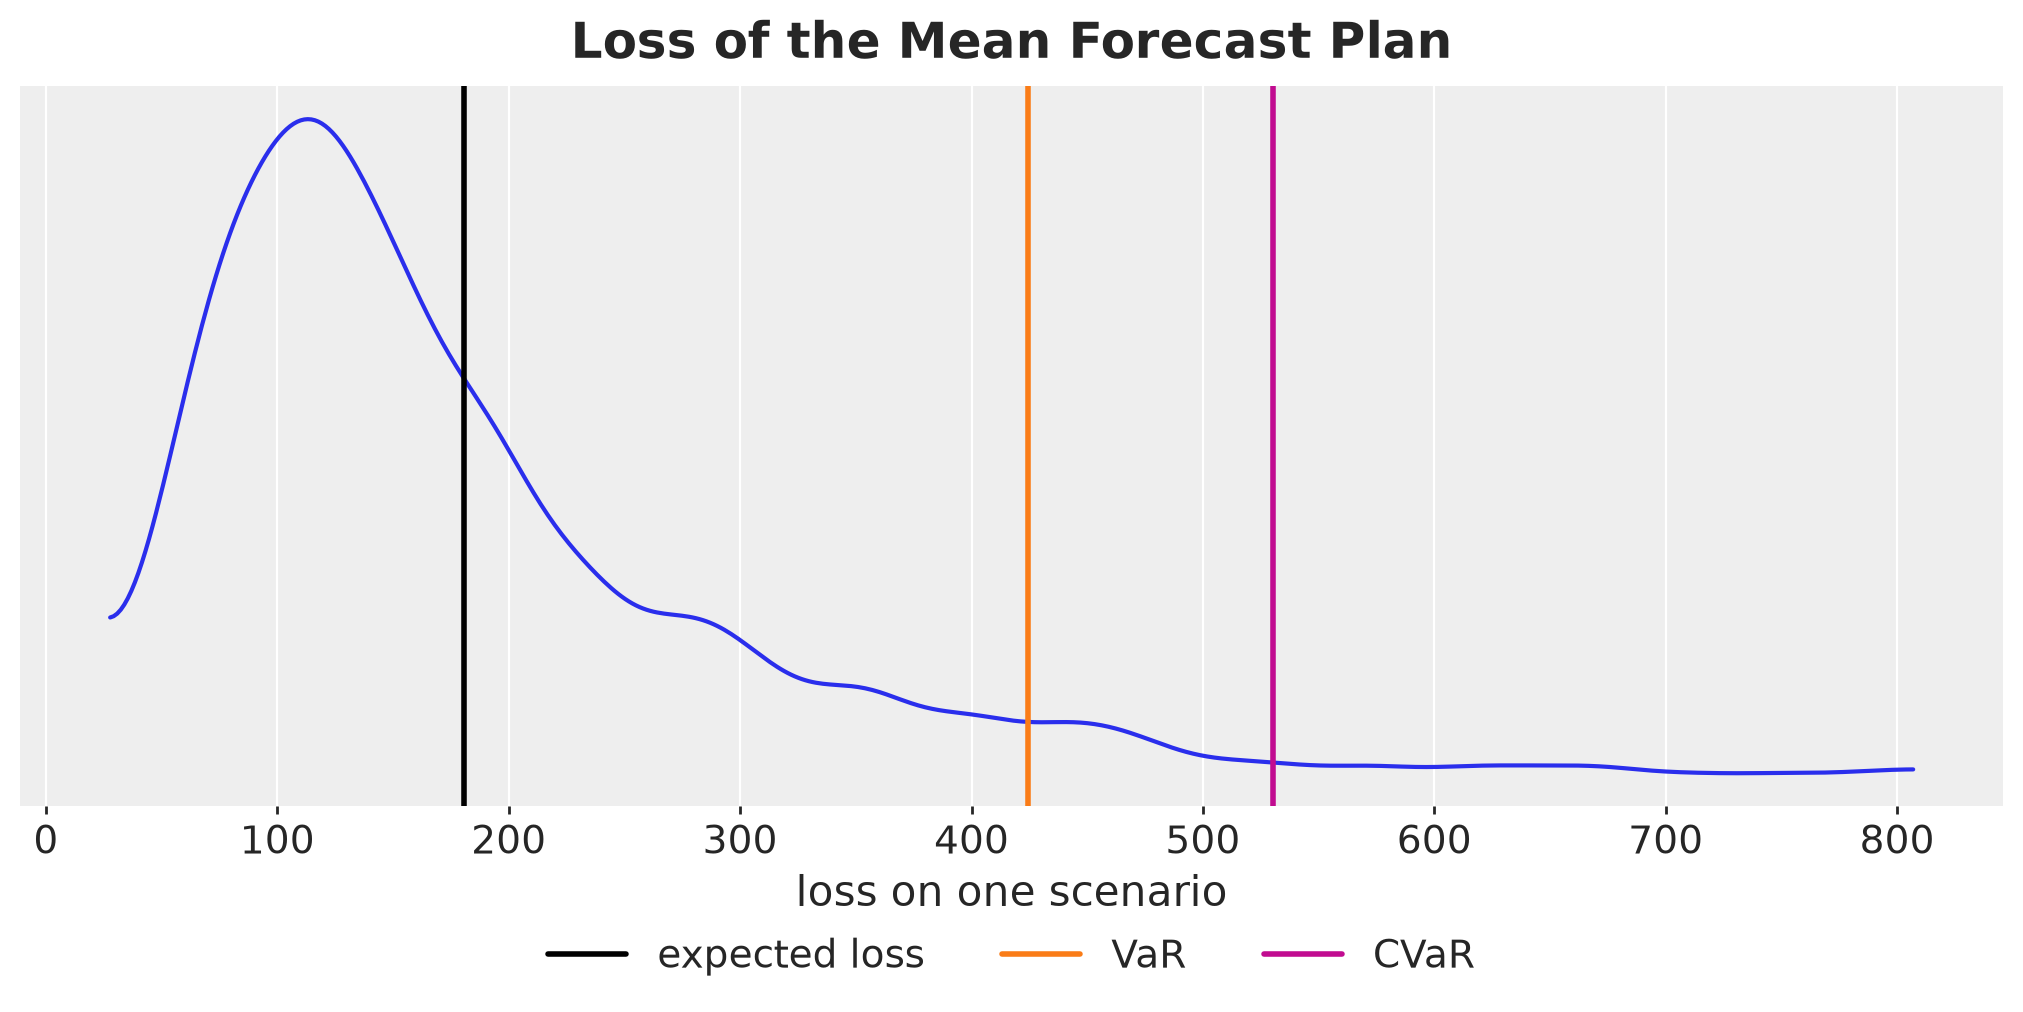

In [23]:
pc = az.plot_dist(
    xr.Dataset({"loss": (("sample",), losses_mean_plan)}),
    sample_dims=["sample"],
    kind="kde",
    visuals={
        "point_estimate": False,
        "point_estimate_text": False,
        "credible_interval": False,
    },
    figure_kwargs={"figsize": (10, 5)},
)
ax = pc.viz["plot"]["loss"].item()
ax.axvline(
    float(losses_mean_plan.mean()), color="black", linewidth=2, label="expected loss"
)
ax.axvline(
    float(np.quantile(losses_mean_plan, 1 - ALPHA, method="inverted_cdf")),
    color="C1",
    linewidth=2,
    label="VaR",
)
ax.axvline(
    float(cvar(losses_mean_plan, tail_size(N_SCENARIOS_OPT))),
    color="C3",
    linewidth=2,
    label="CVaR",
)
ax.set(xlabel="loss on one scenario", title="")
fig = pc.viz["figure"].item()
fig.legend(loc="outside lower center", ncol=3)
fig.suptitle("Loss of the Mean Forecast Plan", fontsize=18, fontweight="bold");

The loss distribution has the shape of the concept plot above: most scenarios cost little, and a long right tail of high-demand scenarios pushes the tail average far beyond the expected loss. The plan that costs nothing on the mean path has an expected loss of $181$ over the scenarios, a value at risk of $425$ and a conditional value at risk of $530$, nearly three times the expected loss.

## Decision Plans

We now build the three remaining plans. The chance-constrained plan comes from the forward pass with the quantile level $1 - \alpha$. The expected cost plan and the CVaR plan have no closed form, so we write a solver in PyTensor. Along the way we build the myopic newsvendor plan as a reference for the expected cost plan.

### Chance-Constrained Orders

We run the forward pass on the joint scenarios with the quantile level $1 - \alpha$. Then we check the guarantee of the quantile on the $N = 1{,}000$ optimization scenarios: on every day, the number of scenarios with a lost sale is at most $\alpha N = 50$.

Demand comes in whole units, while the orders of the expected cost plan below land up to about a thousandth of a unit away from whole numbers. Without a tolerance, a day where the demand matches the intended stock can count as a stockout, so we count a stockout only when the lost sales exceed $10^{-3}$ units. The two or three scenario days that sit right at this edge do not move any number we report.

In [24]:
STOCKOUT_TOL = 1e-3  # lost sales below this are rounding noise of the solver


def is_stockout(sim: Simulation) -> np.ndarray:
    """Days with lost sales above the tolerance, shape (scenarios, horizon)."""
    return sim.lost_sales > STOCKOUT_TOL


orders_cc = forward_pass(
    demand_opt, quantile_shortfall(1 - ALPHA, N_SCENARIOS_OPT), config
)

stockout_scenarios_cc = is_stockout(simulate_scenarios(orders_cc, demand_opt)).sum(
    axis=0
)
assert int(stockout_scenarios_cc.max()) <= tail_size(N_SCENARIOS_OPT)

### Expected Cost Orders

The expected cost plan and the CVaR plan minimize the same objective, $\text{E}[L] + \lambda \, \text{CVaR}_\alpha(L)$, with $\lambda = 0$ for the first and $\lambda = 1$ for the second, so one solver covers both. The objective is convex in $a$, which we show in the *Appendix*, and the only constraint is $a \geq 0$.

The function `objective` calls `simulation_graph` on symbolic orders, so the objective is a graph with the orders as its input, and `pt.grad` gives its gradient with respect to the orders. This is the pattern of Saunders (2025): write the quantity to optimize as a graph, take the gradient symbolically, and compile once. We compile `objective_fn` to evaluate the objective of any plan, and we use it below to compare plans.

We use **projected gradient descent** with Adam. Each step moves the orders a step down the gradient of the objective and then clips them at zero, which is the Euclidean projection onto the feasible set. We write the Adam update by hand inside a second `pytensor.scan`, this time over the steps of the optimizer, with the orders and the two Adam moments as the carry. The whole solve, gradient included, compiles into one `pytensor.function`.

The objective is piecewise linear, so its gradient is a subgradient, and a step size that does not shrink keeps crossing the kinks. We use a cosine decay schedule that takes the step size from one unit to zero over the $1{,}500$ steps of the run, so the early steps move fast and the late steps settle the iterates.

The function `build_solver` returns the compiled solver, a function of the initial orders, the scenarios and the tail weight that returns the orders, the trace of the objective and the step size at every step. We start from the mean forecast plan and solve with $\lambda = 0$.

In [25]:
def objective(
    orders: pt.TensorVariable,
    demand: pt.TensorVariable,
    lam: pt.TensorVariable,
    config: InventoryConfig,
    k: int,
) -> pt.TensorVariable:
    """Expected loss plus lam times the CVaR of the loss over the scenarios."""
    losses, _, _ = simulation_graph(orders, demand, config)
    return losses.mean() + lam * cvar(losses, k)


lam_sym = pt.dscalar("lam")
objective_fn = pytensor.function(
    [orders_sym, demand_sym, lam_sym],
    objective(orders_sym, demand_sym, lam_sym, config, tail_size(N_SCENARIOS_OPT)),
)


def build_solver(
    config: InventoryConfig,
    k: int,
    n_steps: int = 1_500,
    learning_rate: float = 1.0,
    beta_1: float = 0.9,
    beta_2: float = 0.999,
    eps: float = 1e-8,
) -> Callable[
    [np.ndarray, np.ndarray, float], tuple[np.ndarray, np.ndarray, np.ndarray]
]:
    """Compile projected Adam on the expected cost plus lam times CVaR as a scan.

    Parameters
    ----------
    config : InventoryConfig
        The inventory configuration.
    k : int
        The number of scenarios in the tail of the CVaR.
    n_steps : int
        The number of optimizer steps.
    learning_rate : float
        The initial step size, which decays to zero along a cosine curve.
    beta_1, beta_2, eps : float
        The Adam parameters.

    Returns
    -------
    solve : callable
        Maps the initial orders, the demand scenarios and the tail weight lam to the
        orders, the trace of the objective and the step size at every step.
    """
    orders_init = pt.dvector("orders_init")
    demand = pt.dmatrix("demand")
    lam = pt.dscalar("lam")

    def step(
        i: pt.TensorVariable,
        orders: pt.TensorVariable,
        first_moment: pt.TensorVariable,
        second_moment: pt.TensorVariable,
    ) -> tuple:
        value = objective(orders, demand, lam, config, k)
        gradient = pt.grad(value, orders)
        # the step size decays from learning_rate to zero along a cosine curve
        step_size = learning_rate * 0.5 * (1 + pt.cos(np.pi * i / n_steps))
        first_moment = beta_1 * first_moment + (1 - beta_1) * gradient
        second_moment = beta_2 * second_moment + (1 - beta_2) * gradient**2
        first_hat = first_moment / (1 - beta_1 ** (i + 1))
        second_hat = second_moment / (1 - beta_2 ** (i + 1))
        update = step_size * first_hat / (pt.sqrt(second_hat) + eps)
        orders = pt.maximum(orders - update, 0.0)  # projection onto a >= 0
        return orders, first_moment, second_moment, value, step_size

    orders_path, _, _, values, step_sizes = pytensor.scan(
        step,
        sequences=[pt.arange(n_steps, dtype="float64")],
        outputs_info=[
            orders_init,
            pt.zeros_like(orders_init),
            pt.zeros_like(orders_init),
            None,
            None,
        ],
        return_updates=False,
    )
    solver = pytensor.function(
        [orders_init, demand, lam], [orders_path[-1], values, step_sizes]
    )

    def solve(
        orders_init: np.ndarray, demand: np.ndarray, lam: float
    ) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
        return solver(
            np.asarray(orders_init, dtype="float64"),
            np.asarray(demand, dtype="float64"),
            lam,
        )

    return solve


solve = build_solver(config, tail_size(N_SCENARIOS_OPT))

orders_saa, trace_saa, step_sizes = solve(orders_mean, demand_opt, 0.0)

We also build the myopic newsvendor plan with the forward pass at the critical fractile and compare the two plans.

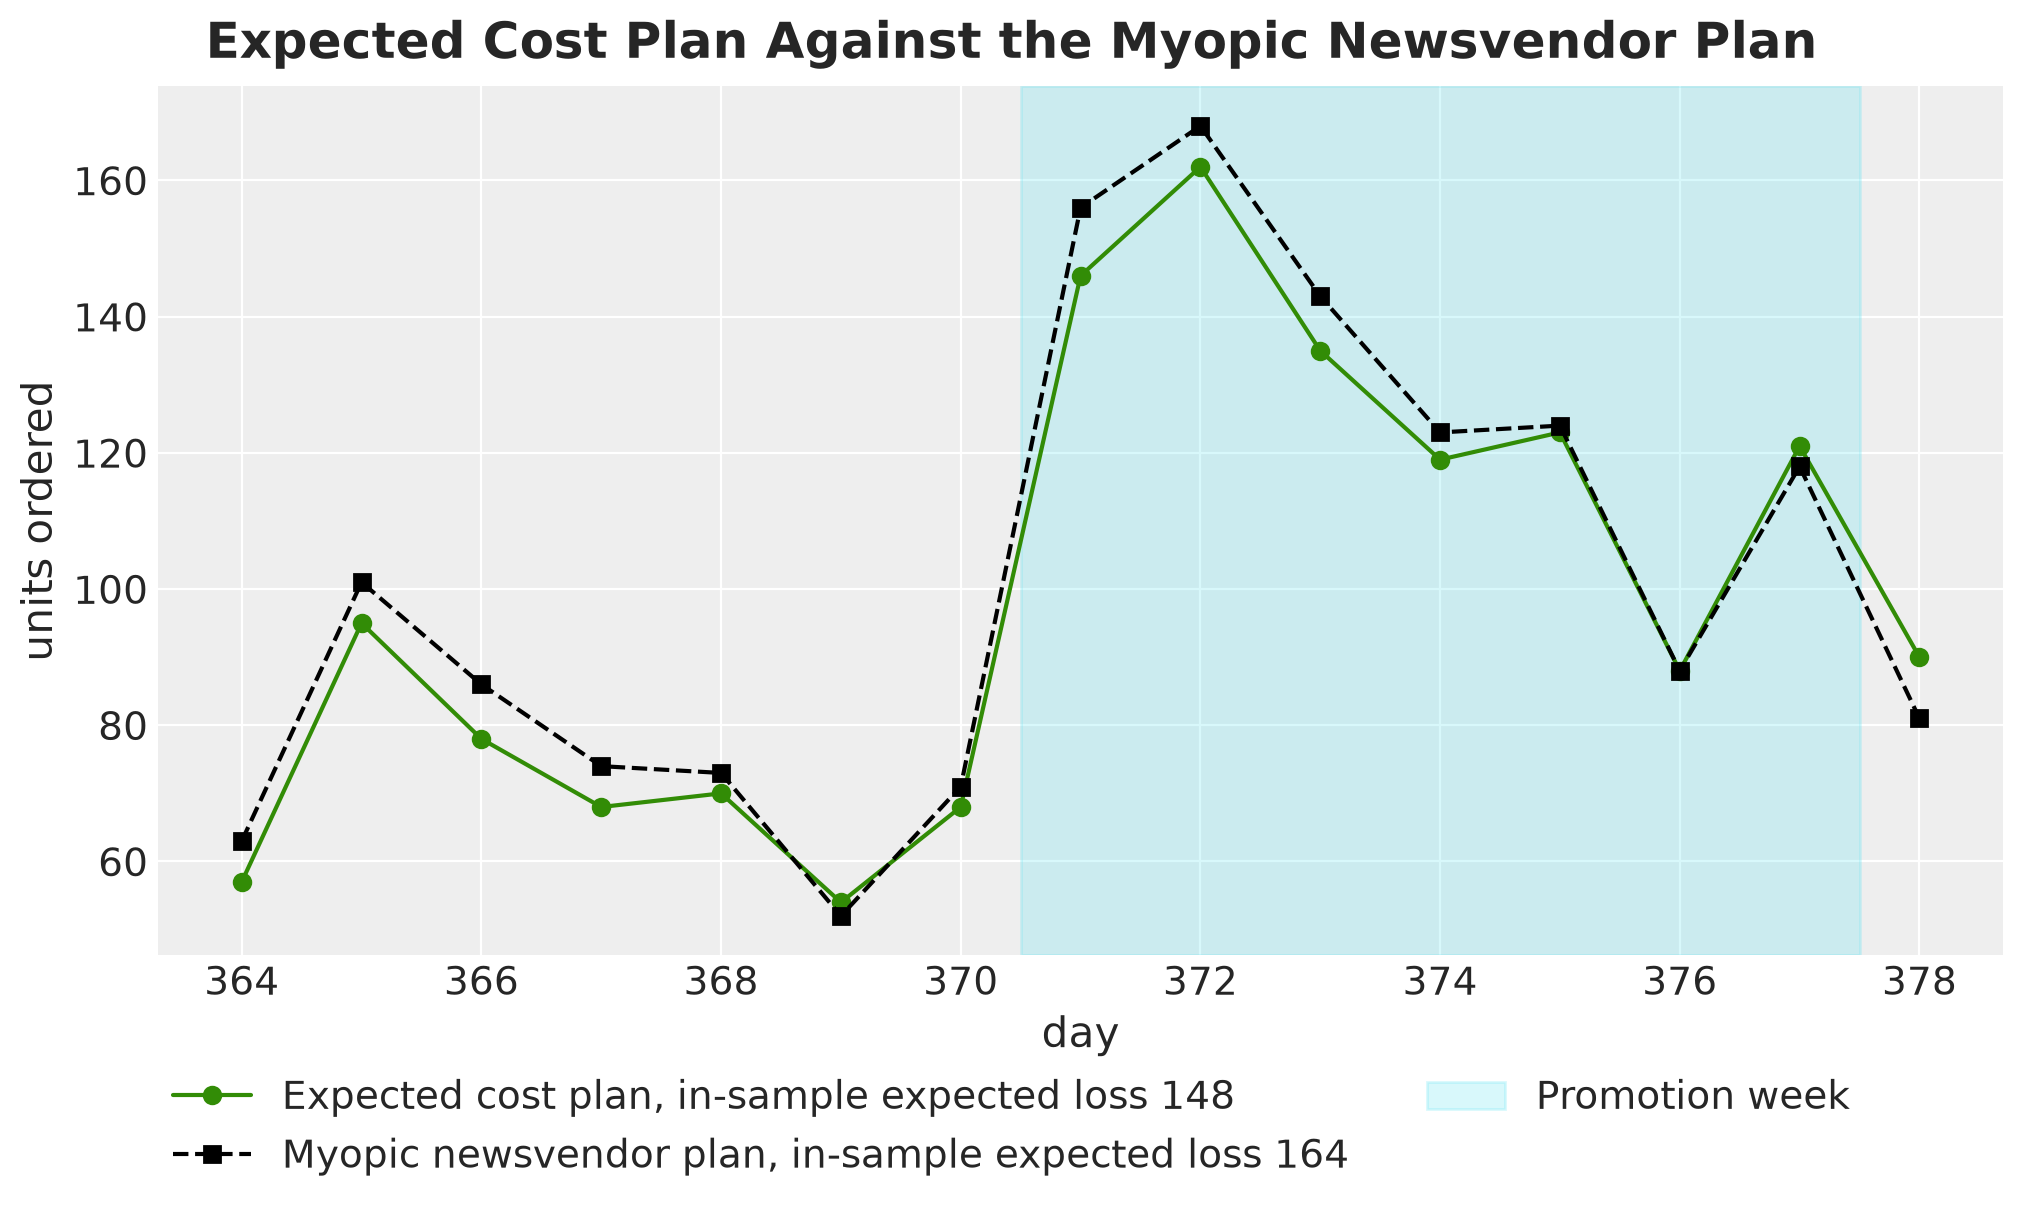

In [26]:
orders_newsvendor = forward_pass(
    demand_opt, quantile_shortfall(critical_fractile, N_SCENARIOS_OPT), config
)
cost_saa = float(objective_fn(orders_saa, demand_opt, 0.0))
cost_newsvendor = float(objective_fn(orders_newsvendor, demand_opt, 0.0))

fig, ax = plt.subplots()
ax.plot(
    days_future,
    orders_saa,
    "o-",
    color="C2",
    label=f"Expected cost plan, in-sample expected loss {cost_saa:.0f}",
)
ax.plot(
    days_future,
    orders_newsvendor,
    "s--",
    color="black",
    label=f"Myopic newsvendor plan, in-sample expected loss {cost_newsvendor:.0f}",
)
shade_promotion(ax)
fig.legend(loc="outside lower center", ncol=2)
ax.set(xlabel="day", ylabel="units ordered")
fig.suptitle(
    "Expected Cost Plan Against the Myopic Newsvendor Plan",
    fontsize=18,
    fontweight="bold",
);

The two plans follow the same shape, and the myopic plan orders more on $11$ of the $15$ days, ties on day thirteen, and orders more in total, $1{,}521$ units against $1{,}474$. The extra stock costs $10\%$ in expected loss, $164$ against $148$ on the optimization scenarios.

Here is the intuition for the larger orders of the myopic plan. The single-period rule charges a leftover unit one day of holding cost. In the $15$-day problem a leftover unit stays on the shelf and pays $h$ on every later day until it sells. It is also left over exactly in the slow scenarios, where the level tends to be low, so it takes several days to sell. The optimizer sees this extra cost and orders less.

The optimizer orders more than the myopic rule on three days only: by $2$ units on day six and by $3$ and $9$ units on the last two days. Near the end of the horizon few days remain, so both plans want a similar stock available, and the optimizer carries less stock into those days.

### CVaR Orders

Now we solve the CVaR plan with $\lambda = 1$: one unit of average loss in the worst $5\%$ of scenarios counts as much as one unit of expected loss.

In [27]:
orders_cvar, trace_cvar, _ = solve(orders_mean, demand_opt, 1.0)

Here are the optimizer traces for both solves: the objective on top and the step size of the schedule below it.

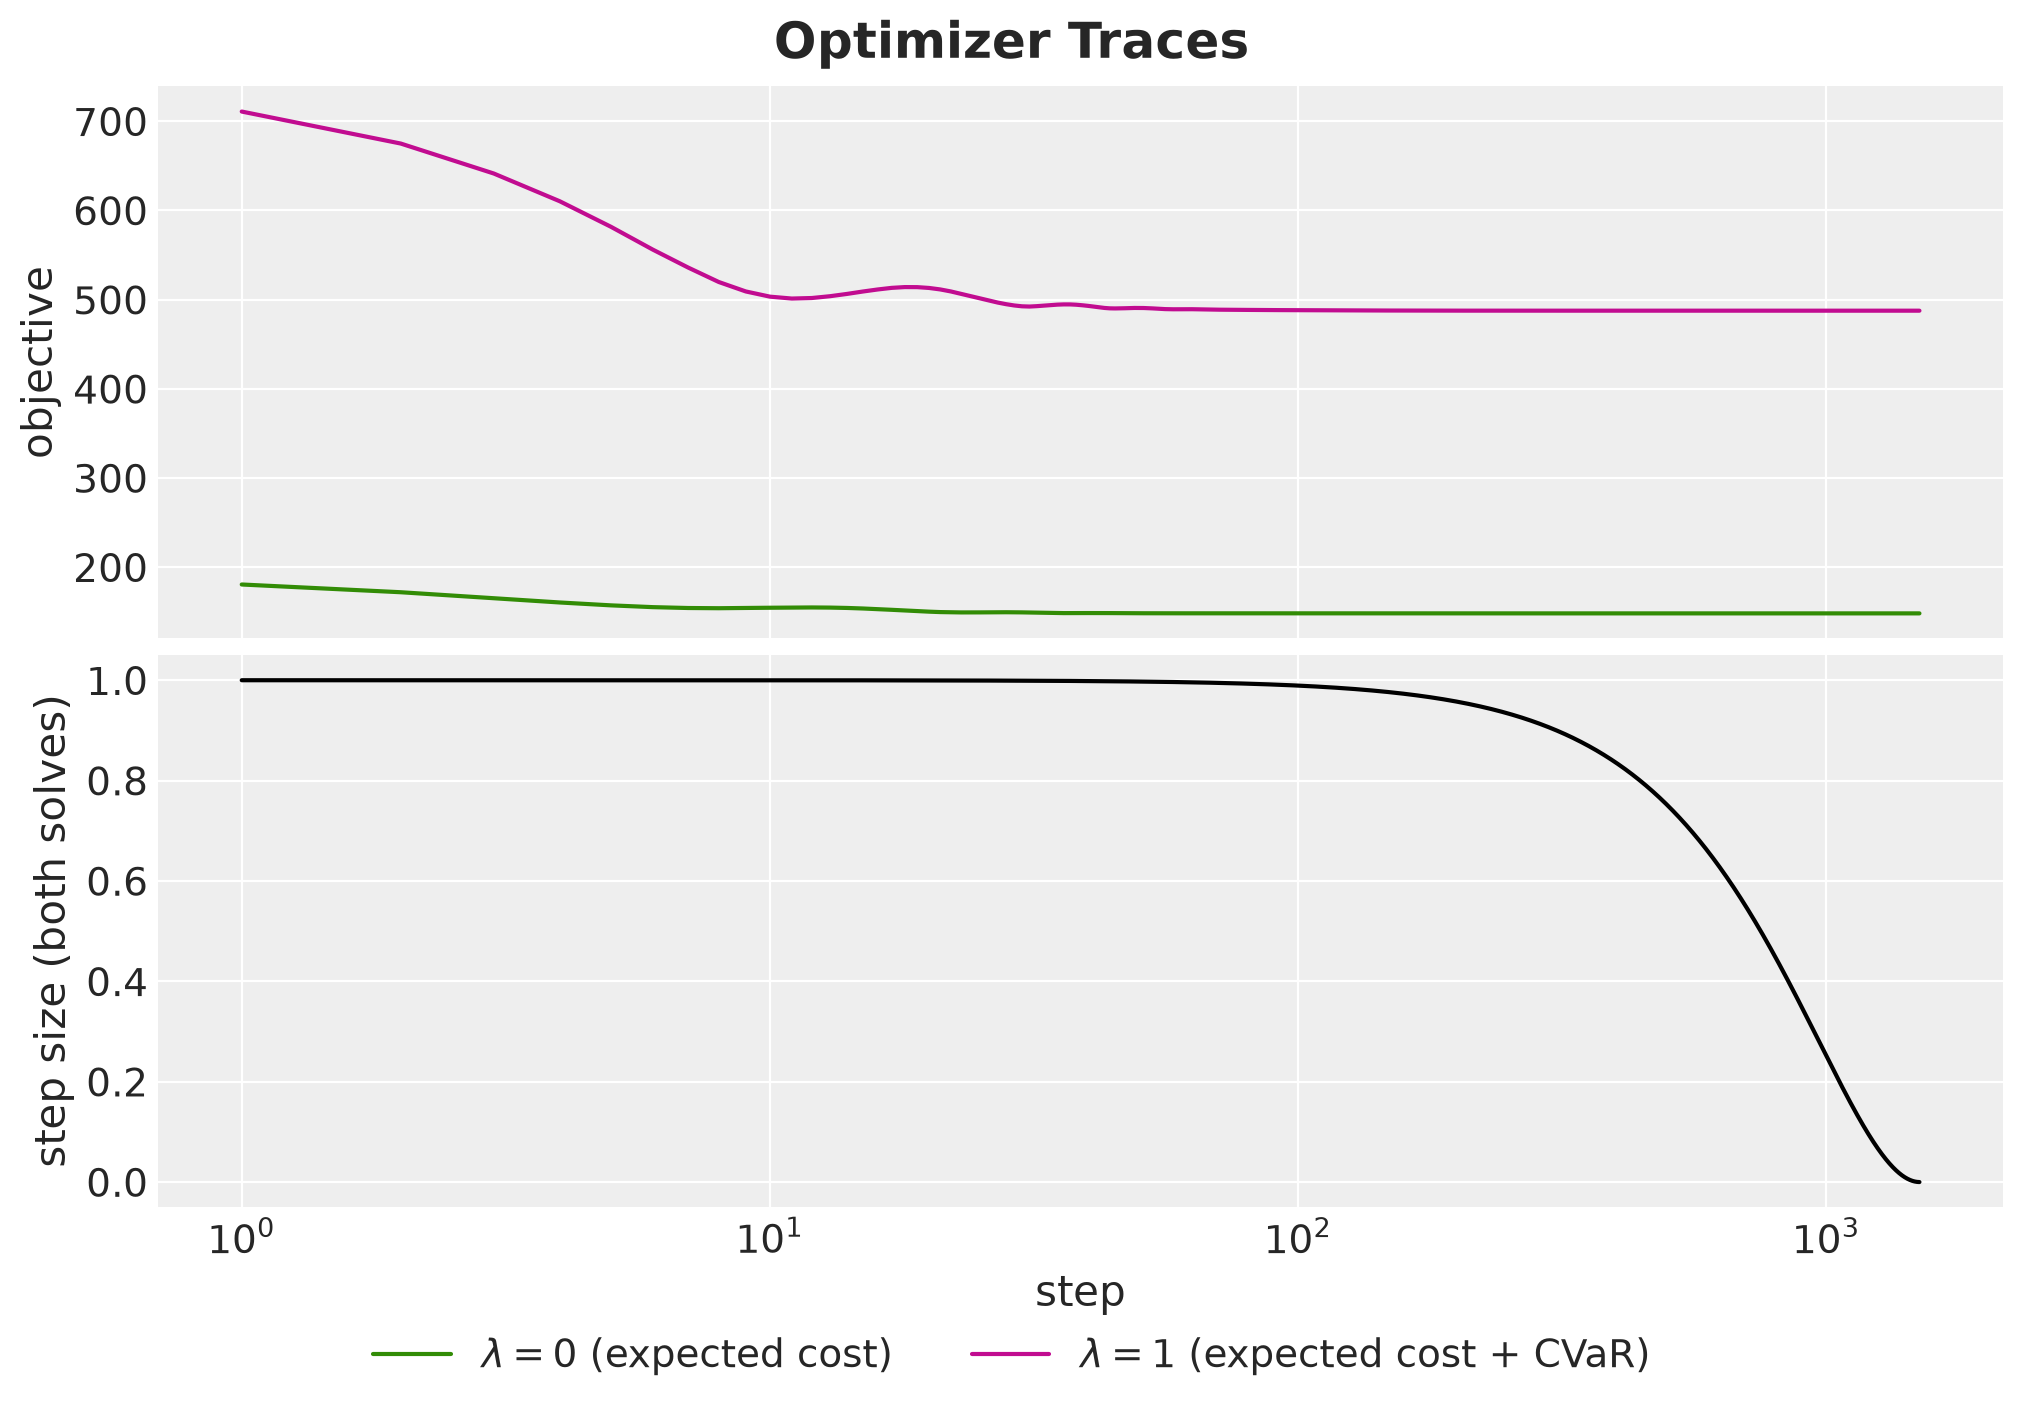

In [28]:
steps = np.arange(1, trace_saa.shape[0] + 1)

fig, axes = plt.subplots(nrows=2, figsize=(10, 7), sharex=True, layout="constrained")
ax = axes[0]
ax.plot(steps, trace_saa, color="C2", label=r"$\lambda = 0$ (expected cost)")
ax.plot(steps, trace_cvar, color="C3", label=r"$\lambda = 1$ (expected cost + CVaR)")
ax.set(ylabel="objective", xscale="log")
ax = axes[1]
ax.plot(steps, step_sizes, color="black")  # the schedule is the same for both
ax.set(xlabel="step", ylabel="step size (both solves)")
fig.legend(loc="outside lower center", ncol=2)
fig.suptitle("Optimizer Traces", fontsize=18, fontweight="bold");

Both objectives drop within the first $50$ steps and change by less than $1\%$ after that, settling at $148$ for the expected cost and $488$ for the expected cost plus CVaR. The step size decays to zero over the run, so the iterates stop moving while the objective is flat, and the *Appendix* checks that these values are the optima.

We now have the four plans, so let's collect them in a list of `Plan` tuples and compare them. We fix one color per plan and use it in every figure that follows. The shaded column is again the promotion week.

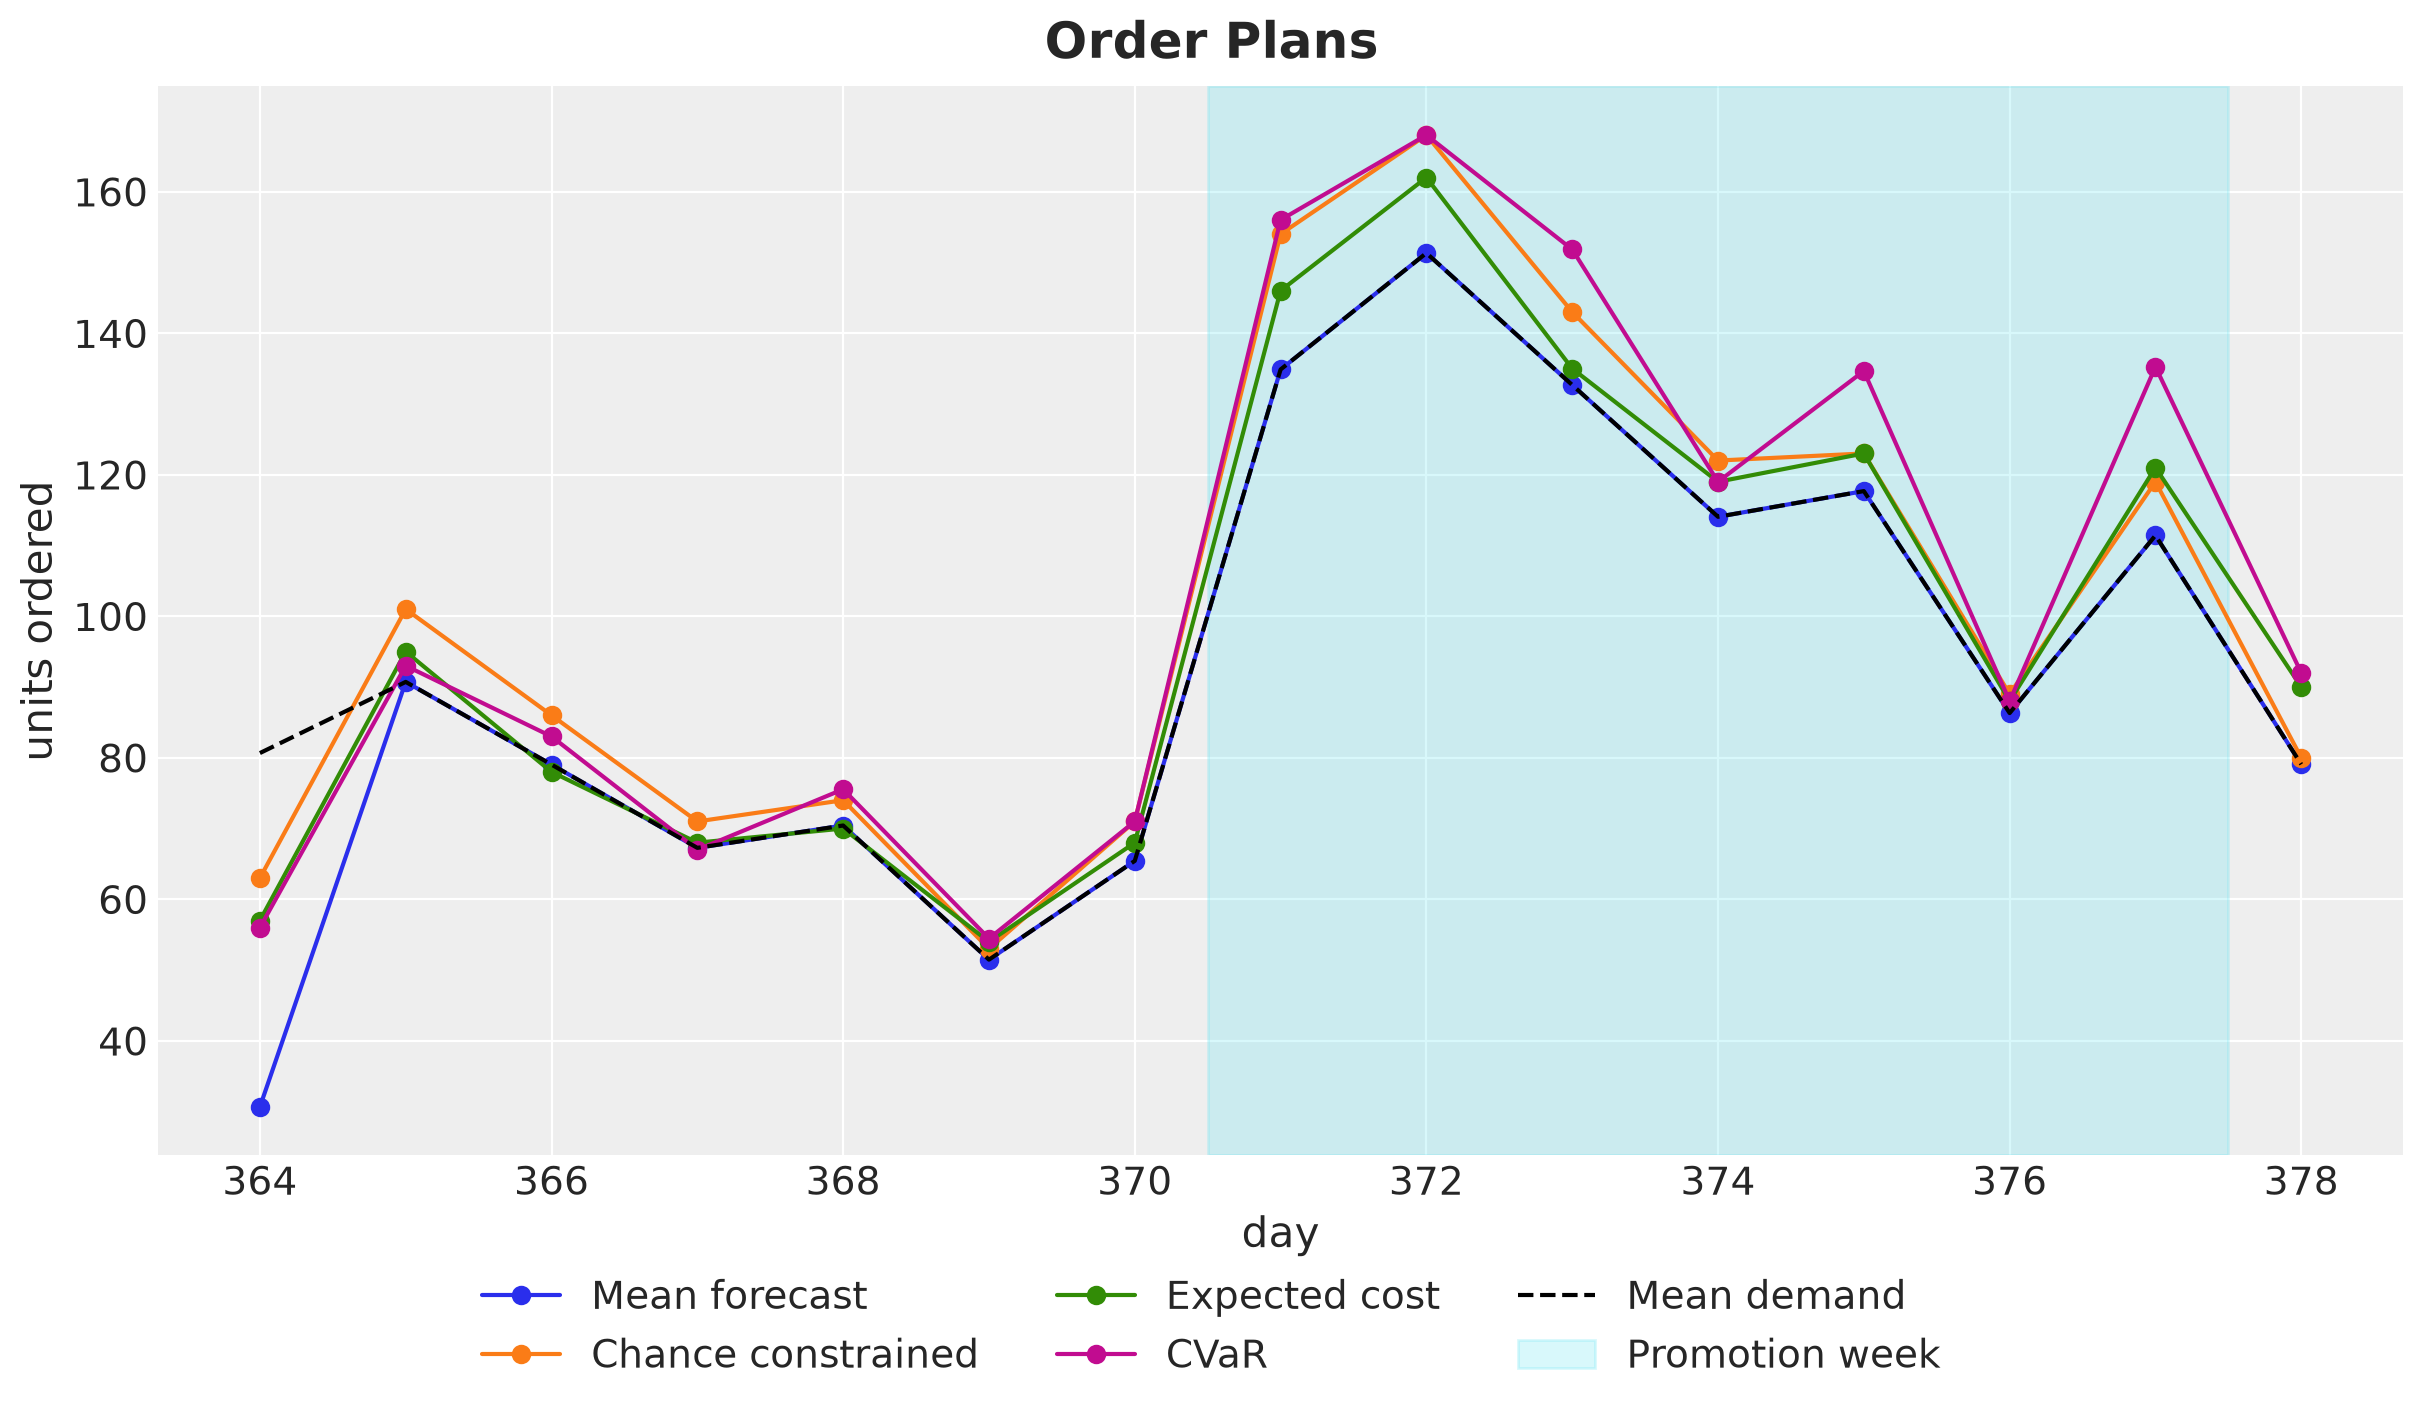

In [29]:
class Plan(NamedTuple):
    """One order plan with its name."""

    name: str
    orders: np.ndarray


plans = [
    Plan("Mean forecast", orders_mean),
    Plan("Chance constrained", orders_cc),
    Plan("Expected cost", orders_saa),
    Plan("CVaR", orders_cvar),
]
plan_names = [plan.name for plan in plans]
PLAN_COLORS = {name: f"C{i}" for i, name in enumerate(plan_names)}

fig, ax = plt.subplots(figsize=(12, 7))
for plan in plans:
    ax.plot(
        days_future, plan.orders, "o-", color=PLAN_COLORS[plan.name], label=plan.name
    )
ax.plot(
    days_future, mean_demand_opt, color="black", linestyle="--", label="Mean demand"
)
shade_promotion(ax)
fig.legend(loc="outside lower center", ncol=3)
ax.set(xlabel="day", ylabel="units ordered")
fig.suptitle("Order Plans", fontsize=18, fontweight="bold");

Here is what we see.

- **Mean forecast.** The plan follows the mean demand. Its first order is $31$ units, because the $50$ units of initial stock cover most of the mean demand of $81$ on day one.
- **Buffers.** The three other plans order a buffer above the mean demand, and every plan orders more in the promotion week. On day one the three plans order $56$ to $63$ units, which is below the mean demand of $81$ and looks like no buffer at all. The buffer is in the stock available, which is the initial stock plus the order: $106$ to $113$ units on day one, so $25$ to $32$ units above the mean demand. On day one the initial stock provides part of the buffer. From day two on, the chance-constrained plan orders at or above the mean demand on every day, the CVaR plan on all days but one and the expected cost plan on all days but two, and the stock carried over adds to the buffer.
- **Chance constrained.** This plan orders the most in the first week and carries the largest cumulative order through day $11$.
- **Expected cost.** This plan orders the least of the three buffered plans, $1{,}474$ units against $1{,}517$ and $1{,}545$, and stays closest to the mean demand.
- **CVaR.** This plan orders the most in the second week, where the high-demand scenarios of the tail separate from the rest, and it ends the horizon with the largest cumulative order of the four. Its path is less smooth than the chance-constrained one, because the $50$ scenarios of the tail shape it.

## Out of Sample Evaluation

We score every plan on the $3{,}000$ held-out scenarios with four metrics:

- **Expected loss.** This is the mean of the loss over the held-out scenarios, the first quantity of the *Decision Rules* section.
- **CVaR of the loss.** This is the second quantity of that section. Recall that it is the mean of the worst $5\%$ of the scenario losses, the tail average. The expected loss says nothing about how bad the bad scenarios are. This is the number to look at when the worst weeks matter more than the average week.
- **Stockout probability per day.** This is the fraction of scenario and day pairs with a lost sale, which is what the chance constraint controls.
- **Probability of a stockout in the horizon.** This is the fraction of scenarios with at least one lost sale in the $15$ days.

We also record a fifth quantity for the *Pareto Frontier* section: the share of the worst $5\%$ of scenarios whose total demand is below the median, which tells us whether the tail is made of high-demand or of low-demand scenarios.

We name the metrics in a `StrEnum`, so that the same strings serve as dictionary keys, column names and axis labels.

In [30]:
class Metric(StrEnum):
    """Names of the held-out scores."""

    EXPECTED_LOSS = "expected loss"
    CVAR = f"CVaR of loss (worst {ALPHA:.0%})"
    STOCKOUT = "stockout probability per day"
    HORIZON = "probability of a stockout in the horizon"
    TAIL_SHARE = "low-demand share of the tail"


def summarize(sim: Simulation, demand: np.ndarray) -> dict[Metric, float]:
    """Expected loss, CVaR, stockout frequencies and tail composition of one plan."""
    stockout = is_stockout(sim)  # a day with lost sales above the tolerance
    k = tail_size(sim.loss.shape[0])
    worst = np.argsort(sim.loss)[-k:]
    total_demand = demand.sum(axis=1)
    return {
        Metric.EXPECTED_LOSS: float(sim.loss.mean()),
        Metric.CVAR: float(cvar(sim.loss, k)),
        Metric.STOCKOUT: float(stockout.mean()),
        Metric.HORIZON: float(stockout.any(axis=1).mean()),
        Metric.TAIL_SHARE: float(
            (total_demand[worst] < np.median(total_demand)).mean()
        ),
    }


scores = {plan.name: simulate_scenarios(plan.orders, demand_eval) for plan in plans}
results = pl.DataFrame(
    [{"plan": name, **summarize(sim, demand_eval)} for name, sim in scores.items()]
)
metrics = [Metric.EXPECTED_LOSS, Metric.CVAR, Metric.STOCKOUT, Metric.HORIZON]
# the metrics that are probabilities or shares, which get percent ticks in the figures
PROBABILITY_METRICS = {Metric.STOCKOUT, Metric.HORIZON, Metric.TAIL_SHARE}

Each of these scores is a single number per plan, an average over the $3{,}000$ held-out scenarios. Recall that every scenario is one draw from the posterior predictive distribution of the demand path, so the loss of a plan over the scenarios is the posterior predictive distribution of its loss. Before we compress each plan into averages, let's look at that distribution, which tells us how bad a bad scenario is under each plan.

The next figure shows, for each plan, the mean and the central $50\%$ and $94\%$ of the loss over the held-out scenarios.

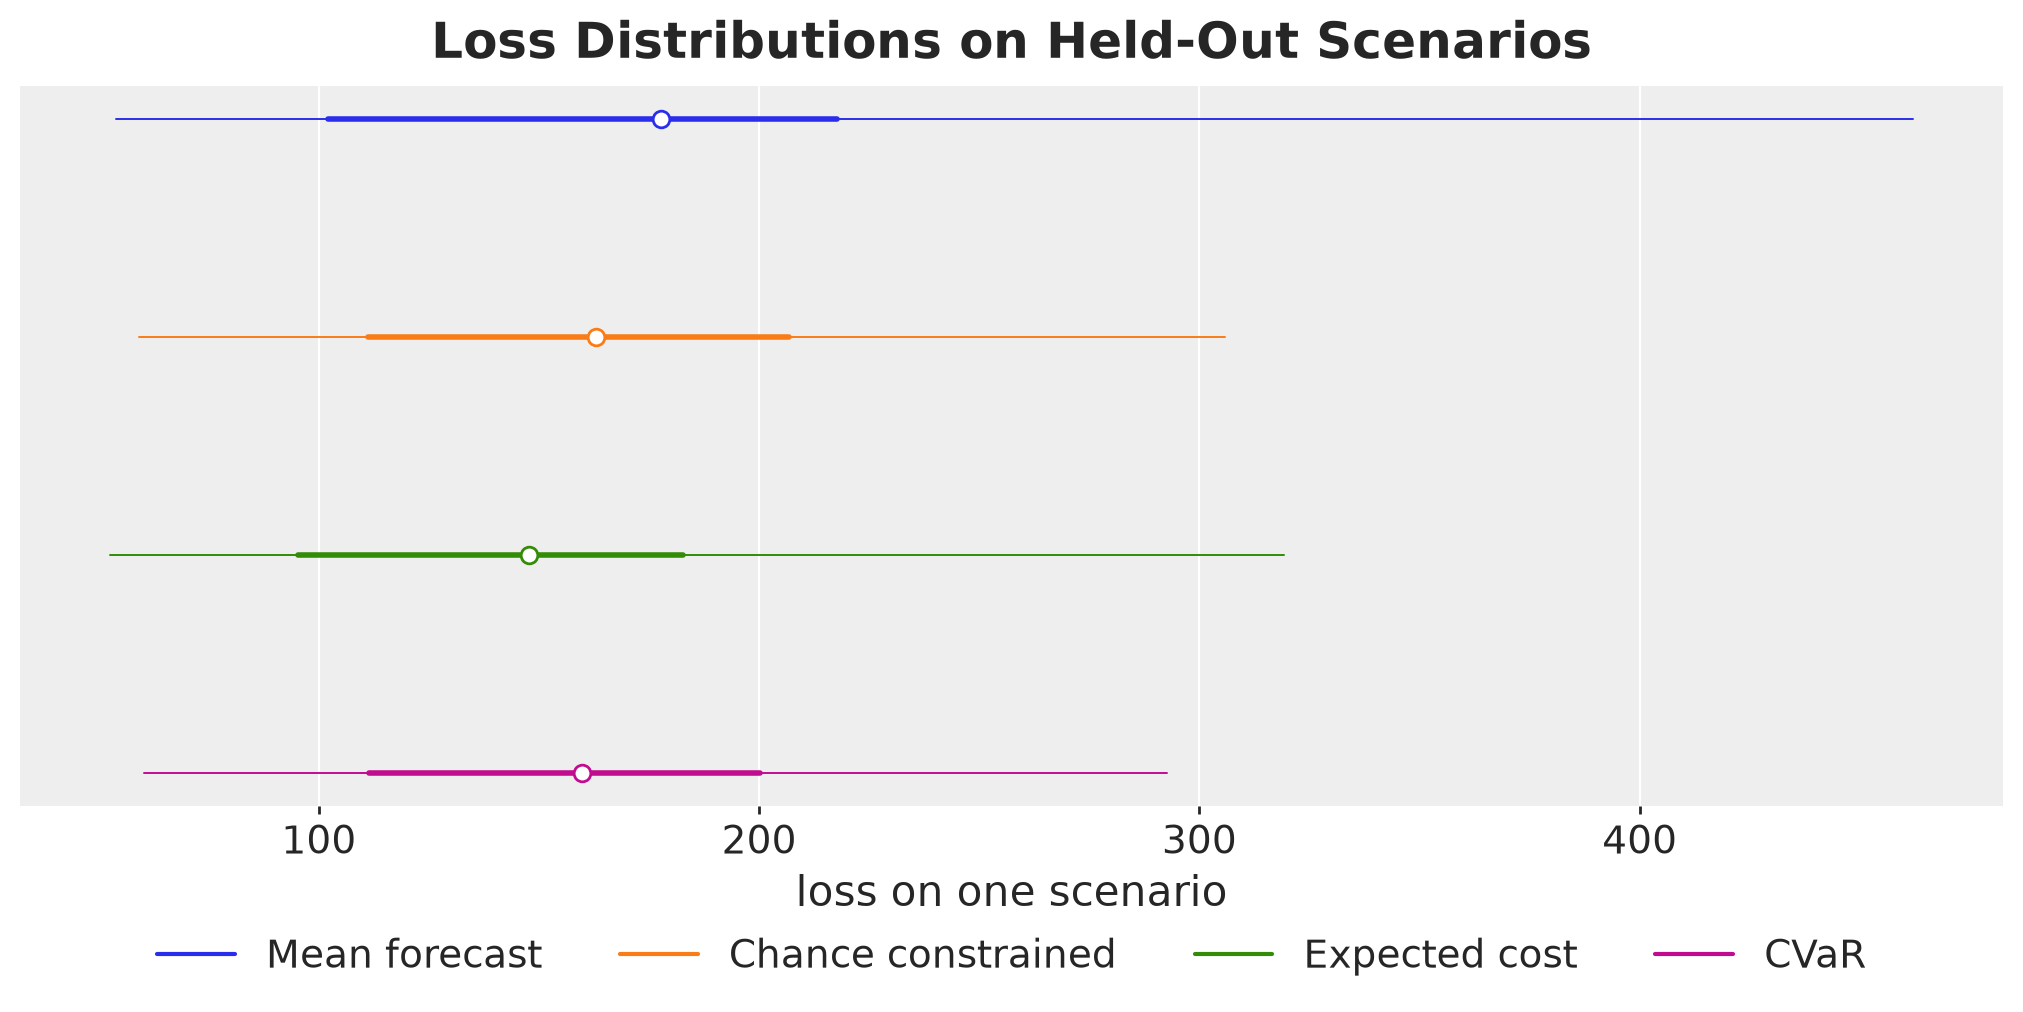

In [31]:
losses_by_plan = {
    name: xr.Dataset({"loss": (("sample",), sim.loss)}) for name, sim in scores.items()
}

pc = az.plot_forest(
    losses_by_plan,
    sample_dims=["sample"],
    ci_kind="eti",
    ci_probs=(0.5, HDI_PROB),
    color=[PLAN_COLORS[name] for name in plan_names],
    labels=[],
    figure_kwargs={"figsize": (10, 5)},
)
pc.viz["plot"].sel(column="labels").item().remove()  # the empty label column
ax = pc.viz["plot"].sel(column="forest").item()
ax.set_subplotspec(ax.get_gridspec()[0, :])  # let the forest span the full width
ax.set(xlabel="loss on one scenario", yticks=[])
fig = pc.viz["figure"].item()
pc.add_legend("model", title="", loc="outside lower center", ncol=4)
fig.suptitle(
    "Loss Distributions on Held-Out Scenarios", fontsize=18, fontweight="bold"
);

The dots are the means and the thick and thin bars the $50\%$ and $94\%$ intervals. Here is what we see.

- **Mean forecast.** The plan has the highest mean and by far the highest upper end, $462$ at the $97$th percentile against $319$ or less for the other three.
- **Chance constrained.** The plan has a lower end of $59$ and an upper end of $306$, the second highest lower end and the second lowest upper end of the four. Most of its loss is holding cost, $141$ of the $163$ on average, since it carries the largest stock through day $11$.
- **Expected cost.** The plan has the lowest mean, $148$, and a lower end of $53$, close to the $54$ of the mean forecast plan. Its $97$th percentile, $319$, is the highest of the three buffered plans.
- **CVaR.** The plan has the lowest upper end, $293$, and pays for it with the highest lower end, $60$ at the $3$rd percentile, since it carries the most stock in the last days.

The upper ends sit much further from the means than the lower ends, for two reasons.

- **Cost asymmetry.** This is the daily cost plot of the *Decision Problem* section. A scenario with demand above the plan pays about $p = 2$ per unit short. A scenario with the same gap below the plan pays $h = 0.1$ per unit left over and per day. So the loss grows much faster on the high-demand side of the plan than on the low-demand side.
- **Right skew of the scenarios.** The forecasting model is log-linear: the expected demand is $\mu_t = \exp(\beta_0 + \ell_t + \dots)$, so the level $\ell_t$ multiplies the demand instead of adding to it. The uncertainty about the level is symmetric on the log scale, and the exponential turns it into a right-skewed uncertainty in units. For example, a level $0.2$ above its center multiplies the demand by $e^{0.2} \approx 1.22$, while a level $0.2$ below it multiplies the demand by $e^{-0.2} \approx 0.82$. So the high-demand scenarios sit further from the central path than the low-demand ones.

Let's confirm this by plotting the loss of every held-out scenario against its total demand over the horizon.

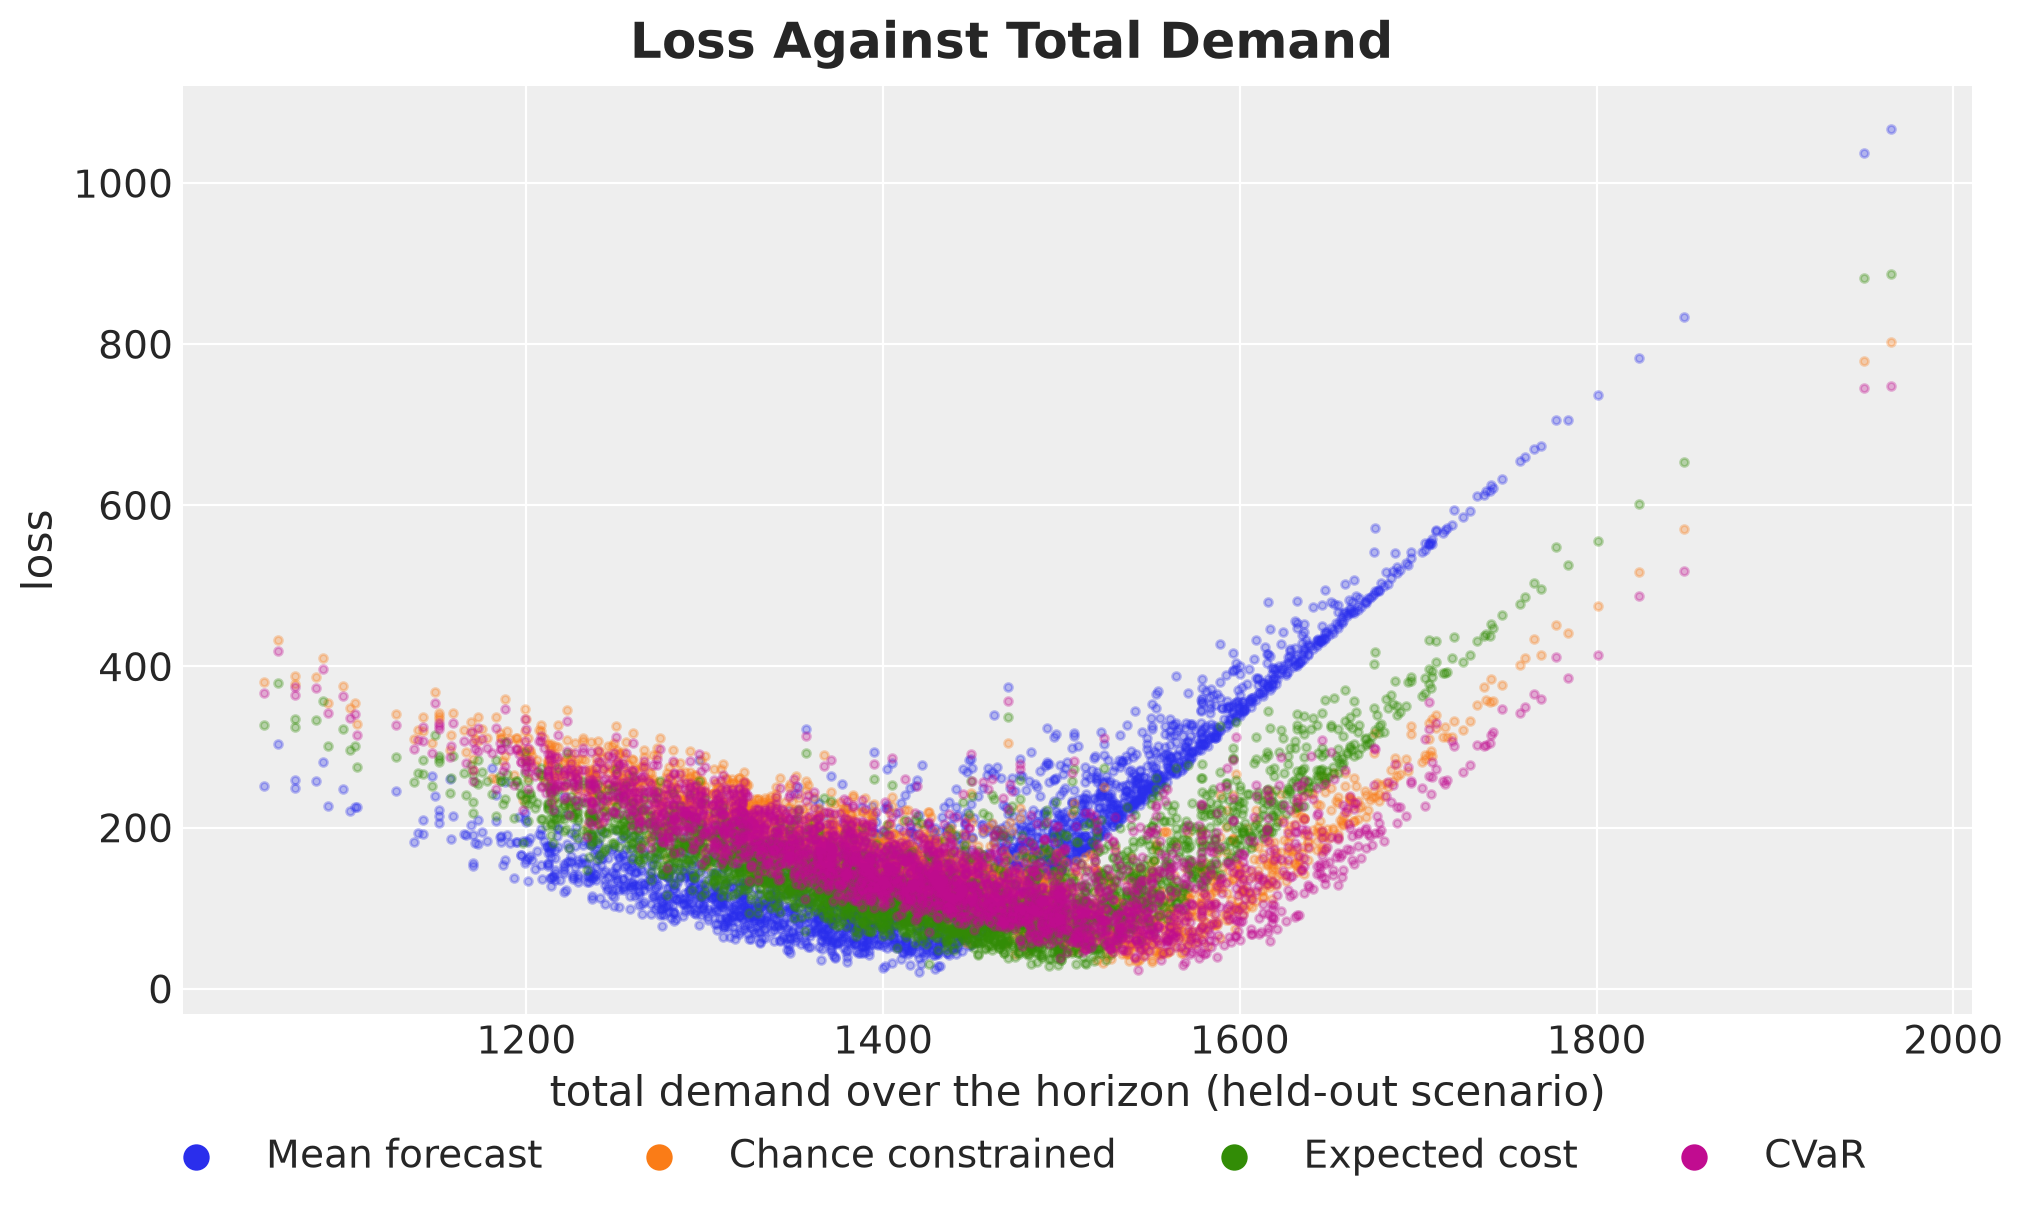

In [32]:
total_demand_eval = demand_eval.sum(axis=1)

fig, ax = plt.subplots()
for name, sim in scores.items():
    ax.scatter(
        total_demand_eval, sim.loss, s=8, alpha=0.3, color=PLAN_COLORS[name], label=name
    )
legend = fig.legend(loc="outside lower center", ncol=4, markerscale=3)
for handle in legend.legend_handles:
    handle.set_alpha(1.0)
ax.set(xlabel="total demand over the horizon (held-out scenario)", ylabel="loss")
fig.suptitle("Loss Against Total Demand", fontsize=18, fontweight="bold");

Each plan traces a V shape. On the left arm we pay holding costs on stock that is never sold, with a slope of about $0.5$ to $0.7$ per unit of missing demand. On the right arm we pay the margin on lost sales, with a slope between about $1.4$ for the CVaR plan and $1.9$ for the mean forecast plan per unit of excess demand, below $p = 2$ because part of the excess lands on days with stock left over, and the larger the buffer the more of it does.

The buffered plans move the bottom of the V to the right, so fewer scenarios reach the steep arm. The mean forecast plan has its bottom at the mean demand, so about half of the scenarios are on the steep arm.

Next, let's look at the four scores of each plan in one figure. The dashed line is the myopic newsvendor plan of the *Decision Plans* section, which we score on the same held-out scenarios as a reference.

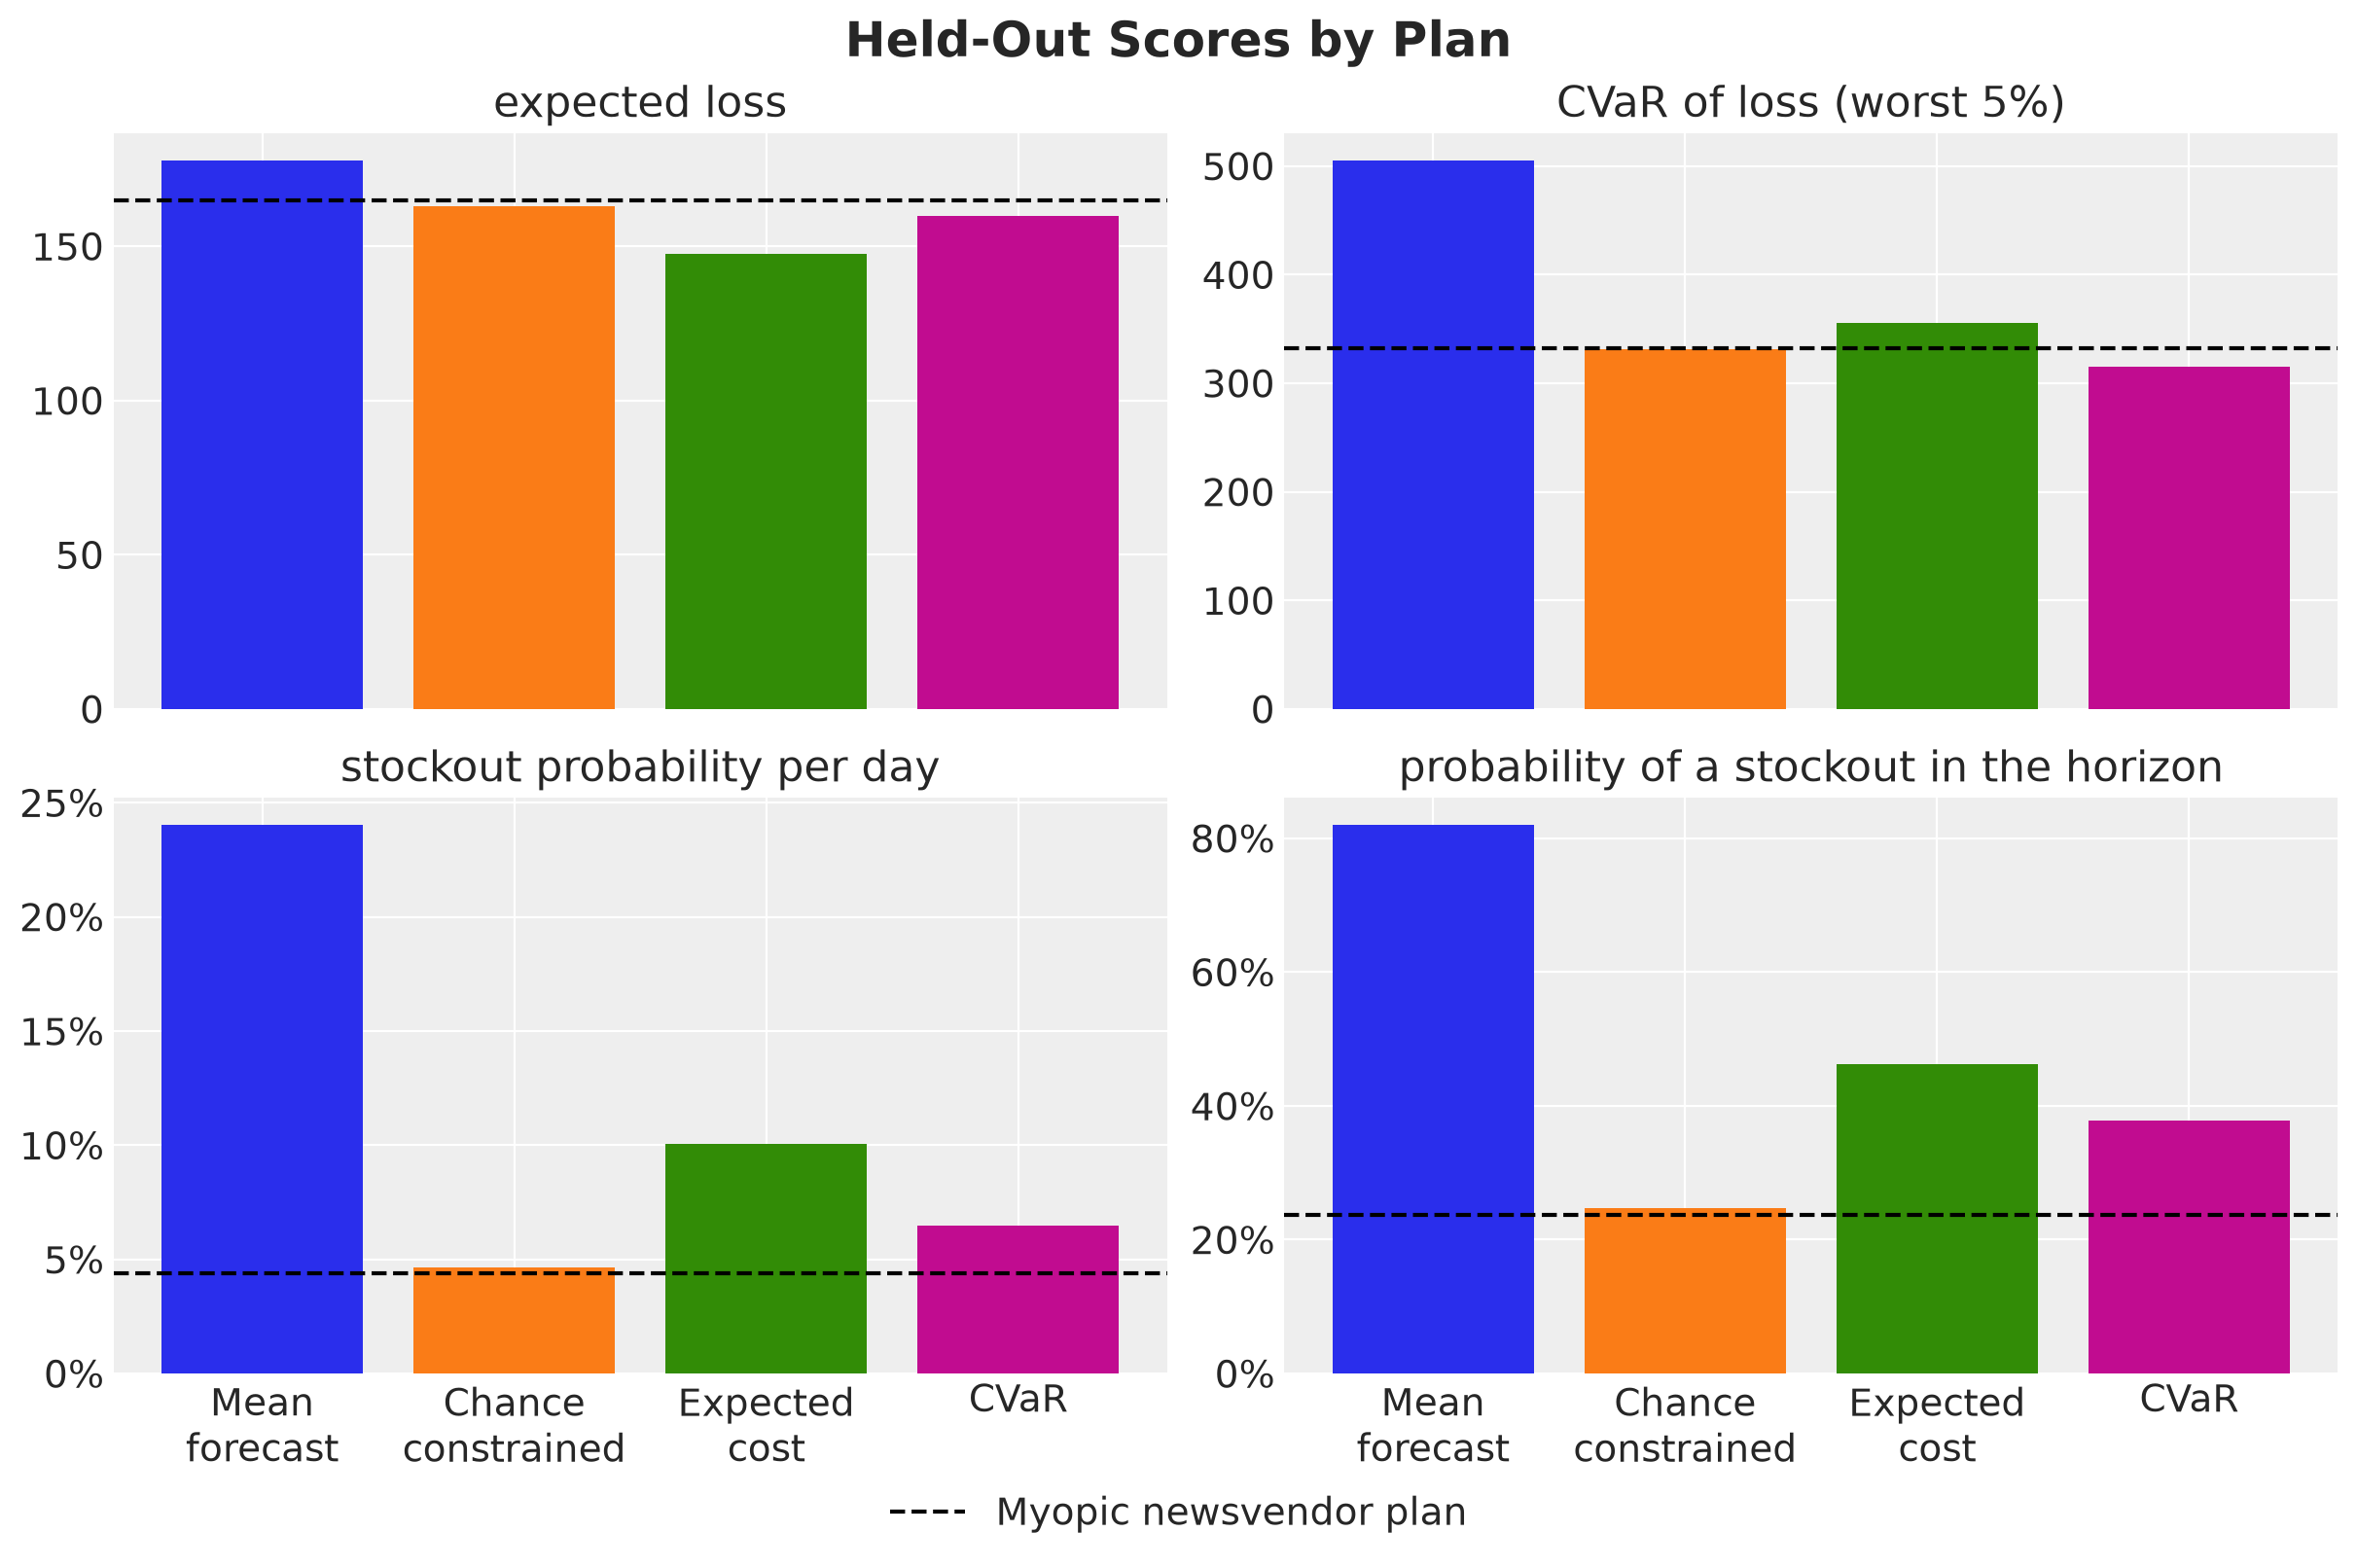

In [33]:
plan_labels = [name.replace(" ", "\n") for name in plan_names]
plan_palette = [PLAN_COLORS[name] for name in plan_names]
# the myopic newsvendor plan of the Decision Plans section, as a reference line
newsvendor_scores = summarize(
    simulate_scenarios(orders_newsvendor, demand_eval), demand_eval
)

fig, axes = plt.subplots(
    nrows=2, ncols=2, figsize=(12, 8), sharex=True, layout="constrained"
)

for ax, metric in zip(axes.flat, metrics, strict=True):
    ax.bar(range(len(plans)), results[metric].to_list(), color=plan_palette)
    reference = ax.axhline(
        newsvendor_scores[metric],
        color="black",
        linestyle="--",
        label="Myopic newsvendor plan",
    )
    if metric in PROBABILITY_METRICS:
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    ax.set(title=metric, xlabel="", ylabel="")

for ax in axes[-1]:
    ax.set_xticks(range(len(plans)), plan_labels)

fig.legend(handles=[reference], loc="outside lower center")
fig.suptitle("Held-Out Scores by Plan", fontsize=18, fontweight="bold");

Here are three important remarks.

- **Point forecast.** The mean forecast plan has the worst expected loss ($178$) and the worst tail ($505$), and it loses sales on a quarter of the days. Every plan that uses the distribution beats it on every metric.
- **Single-period fractile.** The expected cost plan runs out on $10\%$ of the days, more than twice the $1 - p / (p + h) = 4.8\%$ of the single-period rule. This is the multi-period effect of the *Decision Rules* section: the optimum holds less stock than the newsvendor rule. The myopic newsvendor plan costs $12\%$ more in expected loss on the held-out scenarios, $165$ against $148$, and runs out on $4.4\%$ of the days.
- **Service level and tail.** The chance-constrained plan lands at $4.6\%$ per day on the held-out scenarios, close to its $5\%$ target. Its probability of at least one stockout in the horizon is $25\%$, well below the $54\%$ of independent days. The CVaR plan has the lowest tail loss of the four, $315$, at an expected loss of $160$ and a stockout probability per day of $6.5\%$.

The chance constraint holds day by day, so we look at the stockout probability on each day of the horizon. The dashed line is the target $\alpha = 0.05$.

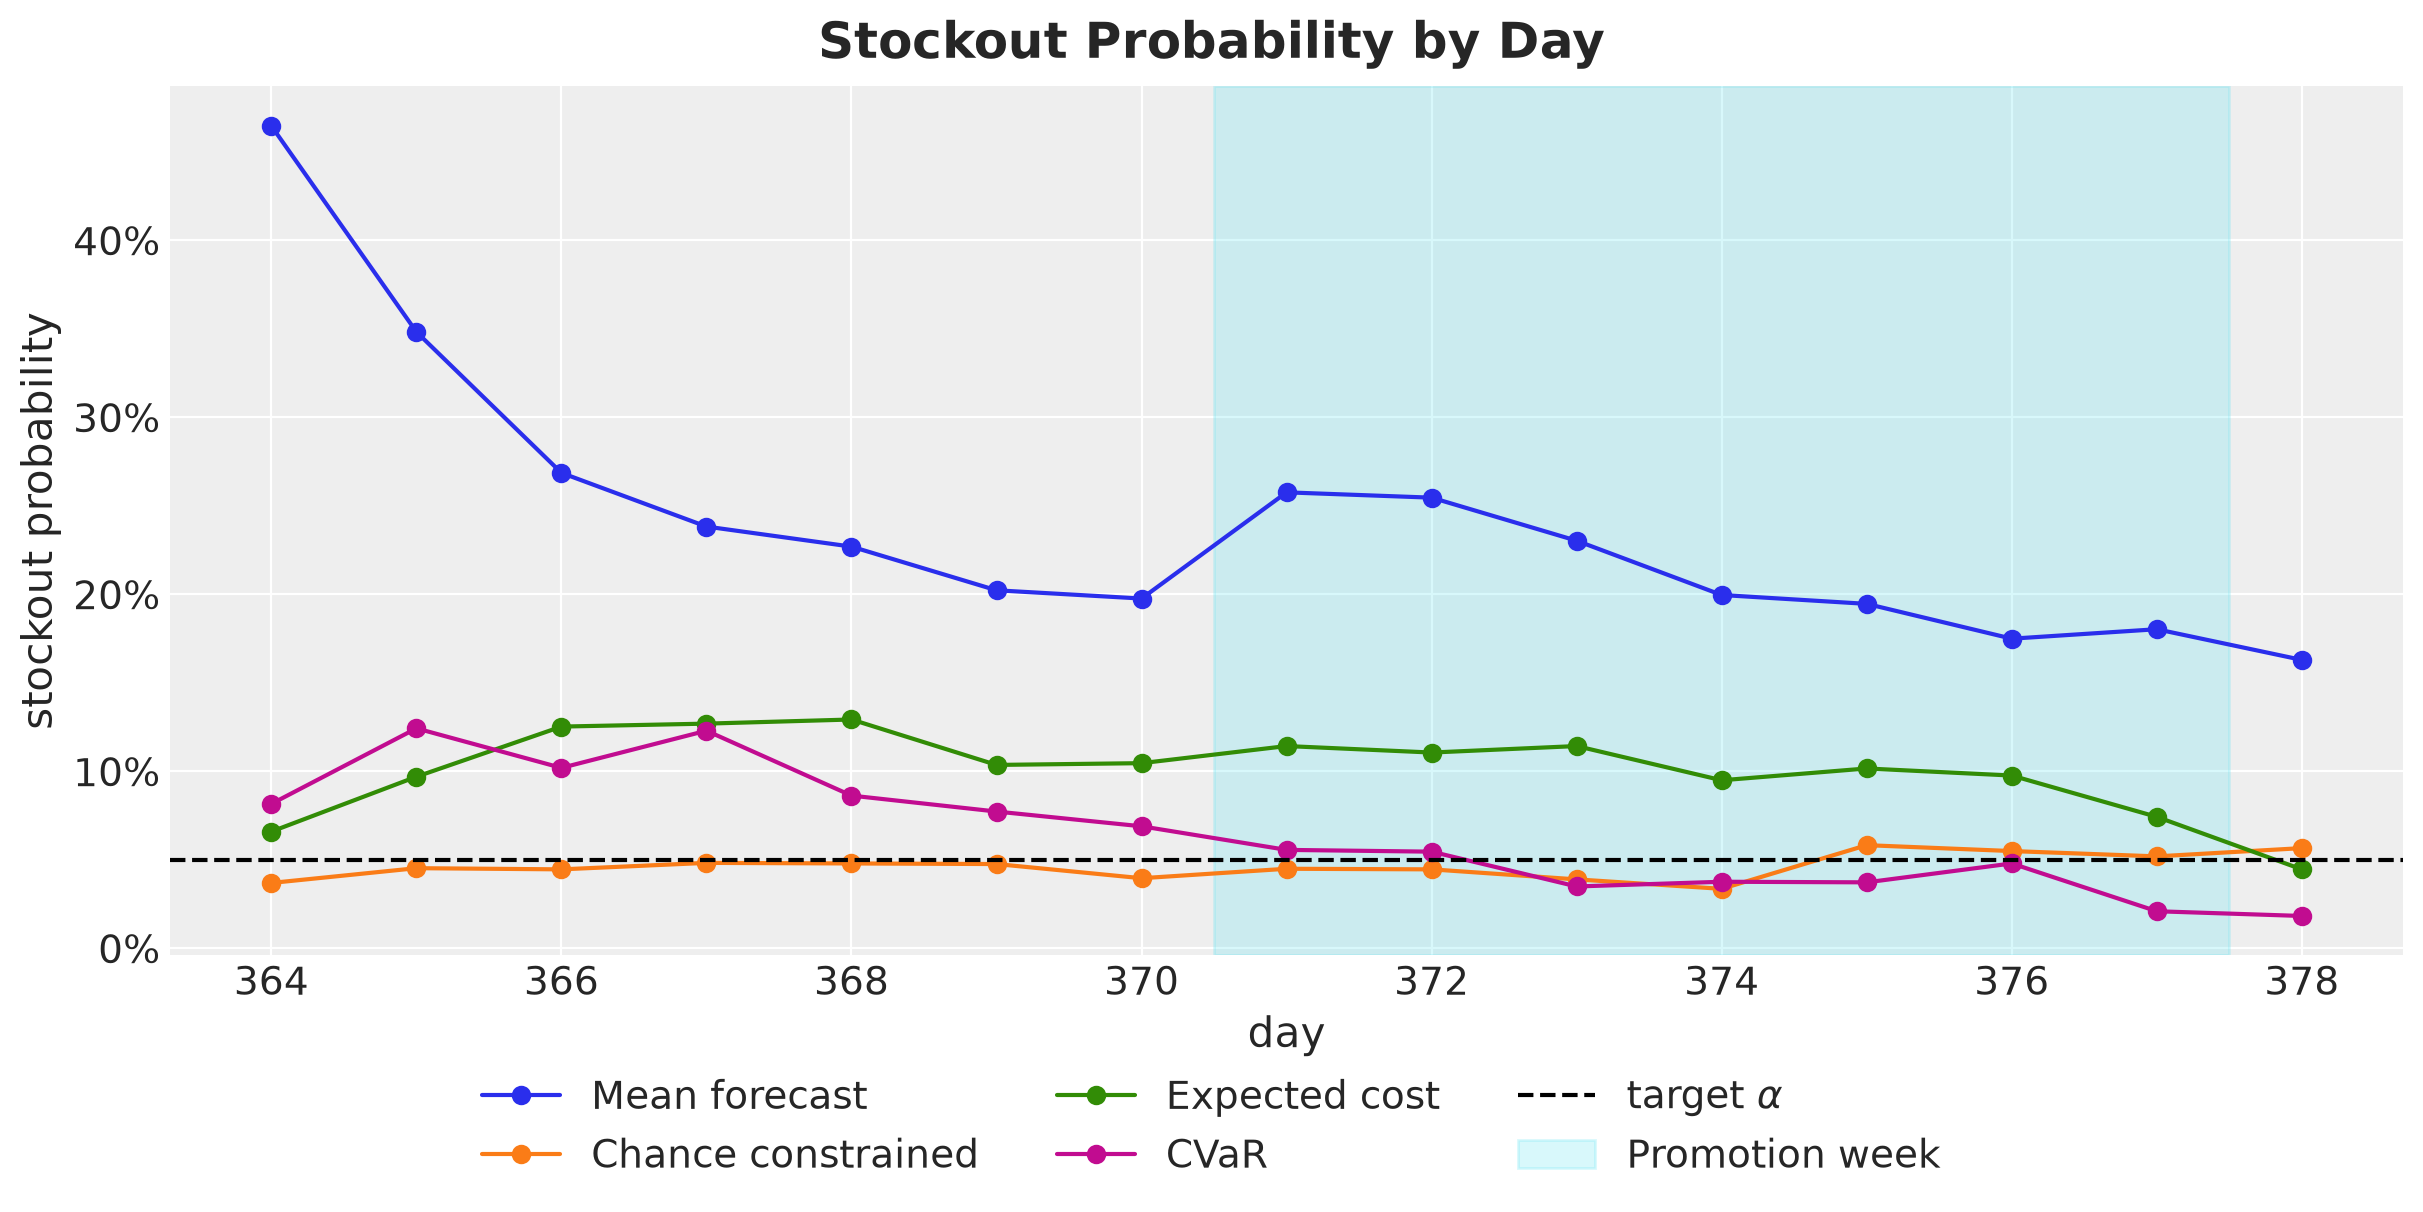

In [34]:
fig, ax = plt.subplots(figsize=(12, 6))
for name, sim in scores.items():
    ax.plot(
        days_future,
        is_stockout(sim).mean(axis=0),
        "o-",
        color=PLAN_COLORS[name],
        label=name,
    )
ax.axhline(ALPHA, color="black", linestyle="--", label=r"target $\alpha$")
shade_promotion(ax)
fig.legend(loc="outside lower center", ncol=3)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.set(xlabel="day", ylabel="stockout probability")
fig.suptitle("Stockout Probability by Day", fontsize=18, fontweight="bold");

Here is what we see, plan by plan.

- **Mean forecast.** The plan loses sales in $47\%$ of the scenarios on day one and in $16\%$ to $35\%$ of them afterwards, as the leftovers of the days with low demand build up a small buffer.
- **Chance constrained.** The plan stays between $3.4\%$ and $5.8\%$ on every day, close to the target on each of them. The quantile guarantees at most $5\%$ only on the optimization scenarios. With $1{,}000$ of them, the in-sample frequency of a day estimates the stockout probability with a standard deviation of $\sqrt{0.05 \cdot 0.95 / 1{,}000} \approx 0.007$, about $0.7$ percentage points, so held-out values up to about $6\%$ are within the sampling error.
- **Expected cost.** The plan sits between $7\%$ and $13\%$ until the last day, where it drops to $4.5\%$, close to the single-period level of $4.8\%$.
- **CVaR.** The plan runs out in $8\%$ to $12\%$ of the scenarios on the first five days and in $2\%$ to $5\%$ on the last four. The tail objective looks at the high-demand horizons, which separate from the rest only after several days, so the plan adds its stock late.

Next, let's see why the scenarios have to be joint draws. In practice a forecast is often delivered as a distribution for each day on its own, for example as per-day quantiles. One could build scenarios from such a forecast by drawing each day from its own distribution. Those scenarios have the right distribution on every single day, but no link between the days. In the simulator the days are linked by the stock that carries over, so the question is what a plan loses when the scenarios lack that link.

We can produce such scenarios from the joint ones. We shuffle each day of the optimization matrix independently across scenarios with `rng.permuted` along the scenario axis, which keeps the distribution of every single day and removes the correlation across days. We build the chance-constrained plan on the shuffled scenarios and score it on the held-out scenarios, next to the plan built on the joint ones.

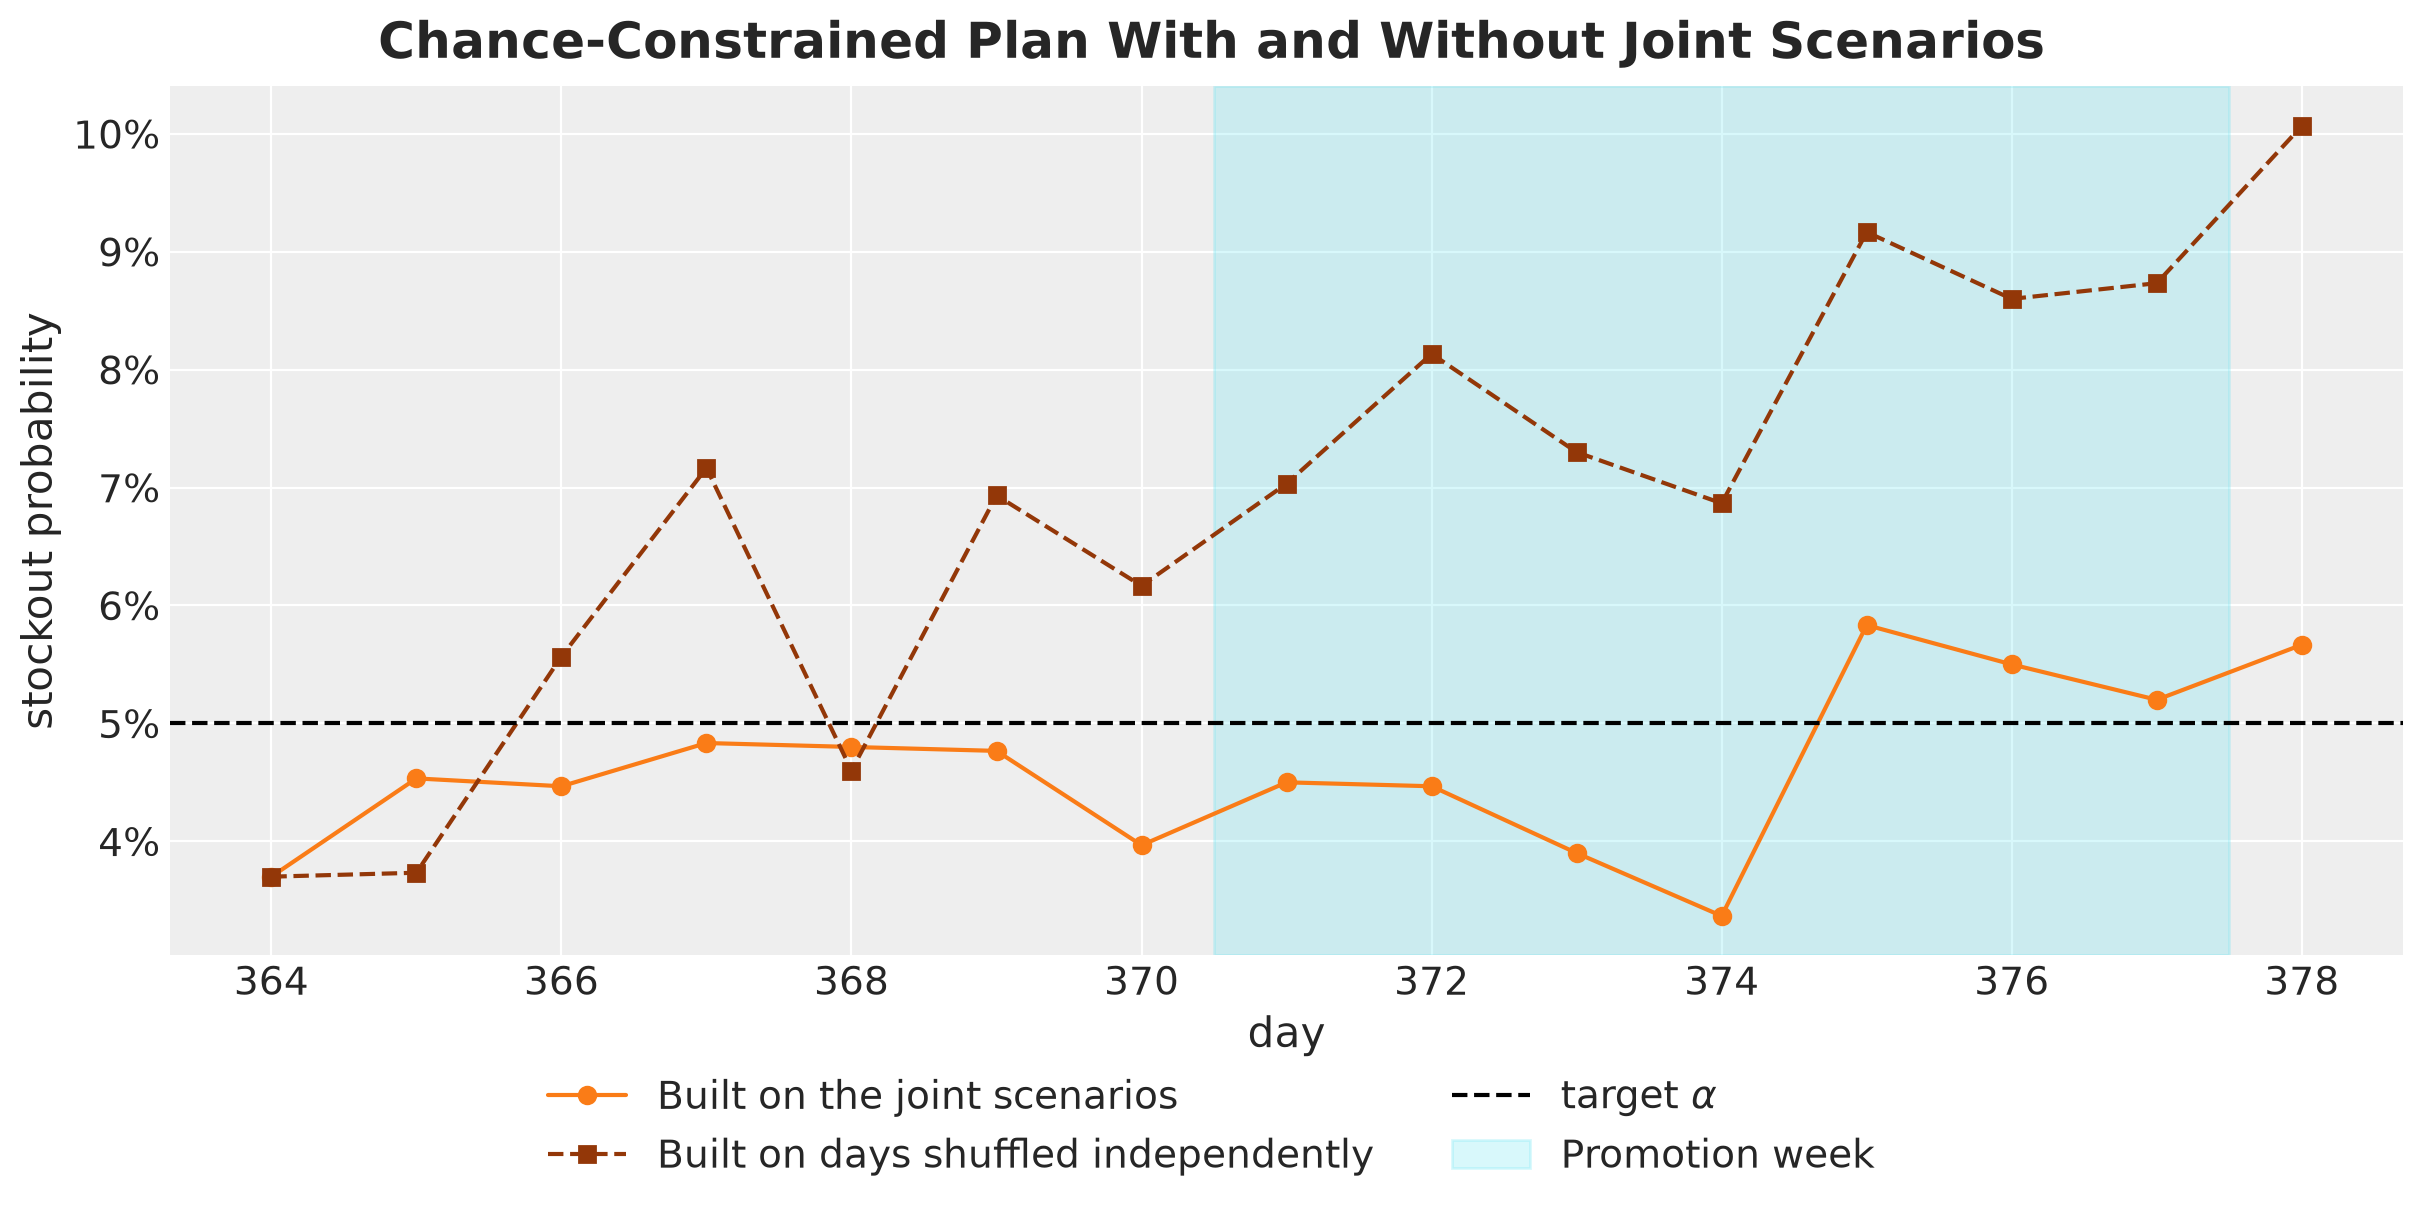

In [35]:
demand_independent = rng.permuted(demand_opt, axis=0)
orders_cc_independent = forward_pass(
    demand_independent, quantile_shortfall(1 - ALPHA, N_SCENARIOS_OPT), config
)
sim_cc_independent = simulate_scenarios(orders_cc_independent, demand_eval)
sim_cc_joint = scores["Chance constrained"]

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(
    days_future,
    is_stockout(sim_cc_joint).mean(axis=0),
    "o-",
    color="C1",
    label="Built on the joint scenarios",
)
ax.plot(
    days_future,
    is_stockout(sim_cc_independent).mean(axis=0),
    "s--",
    color="C4",
    label="Built on days shuffled independently",
)
ax.axhline(ALPHA, color="black", linestyle="--", label=r"target $\alpha$")
shade_promotion(ax)
fig.legend(loc="outside lower center", ncol=2)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.set(xlabel="day", ylabel="stockout probability")
fig.suptitle(
    "Chance-Constrained Plan With and Without Joint Scenarios",
    fontsize=18,
    fontweight="bold",
);

The plan built on the shuffled scenarios sits above the target on $12$ of the $15$ days, between $4\%$ and $7\%$ in the first week, between $7\%$ and $9\%$ in the promotion week, and at $10\%$ on the last day, for an average of $6.9\%$ against $4.6\%$.

It orders $41$ units less over the horizon. The shuffle breaks the link between the past demand of a path, which sets the stock it carries into day $t$, and its demand on day $t$. So the shortfall $D_t - I_{t-1}$ varies less across the shuffled scenarios, its $95\%$ quantile is lower, and the gap to the target grows with the day, since the stock carried into a later day depends on more past days.

Next, let's look at the stock on hand, the units left on the shelf at the end of each day ($I_t$), under each plan. We draw one panel per plan, with the $50\%$ and $94\%$ bands of the stock over the held-out scenarios. The black line is the stock that each plan leaves at the end of each day when the demand is the true future path, the $15$ days we held out when we generated the data. We score the plans on that path right after this figure.

One feature of these bands needs an explanation. On a given day the shelf is empty in some of the scenarios, and in those the stock on hand is exactly zero. The share of such scenarios lies between $2\%$ and $47\%$, depending on the plan and the day. So the distribution of the stock on a given day is a mixture of a point mass at zero, from the scenarios with an empty shelf, and a continuous part, from the scenarios with leftovers. The point mass sits at the lower end of the distribution, so it pulls the lower edges of the bands down to zero, while the upper edges follow the scenarios with leftovers.

The lower edge of the $94\%$ band is the $3$rd percentile of the stock. When more than $3\%$ of the scenarios have an empty shelf on a day, that edge is zero on that day.

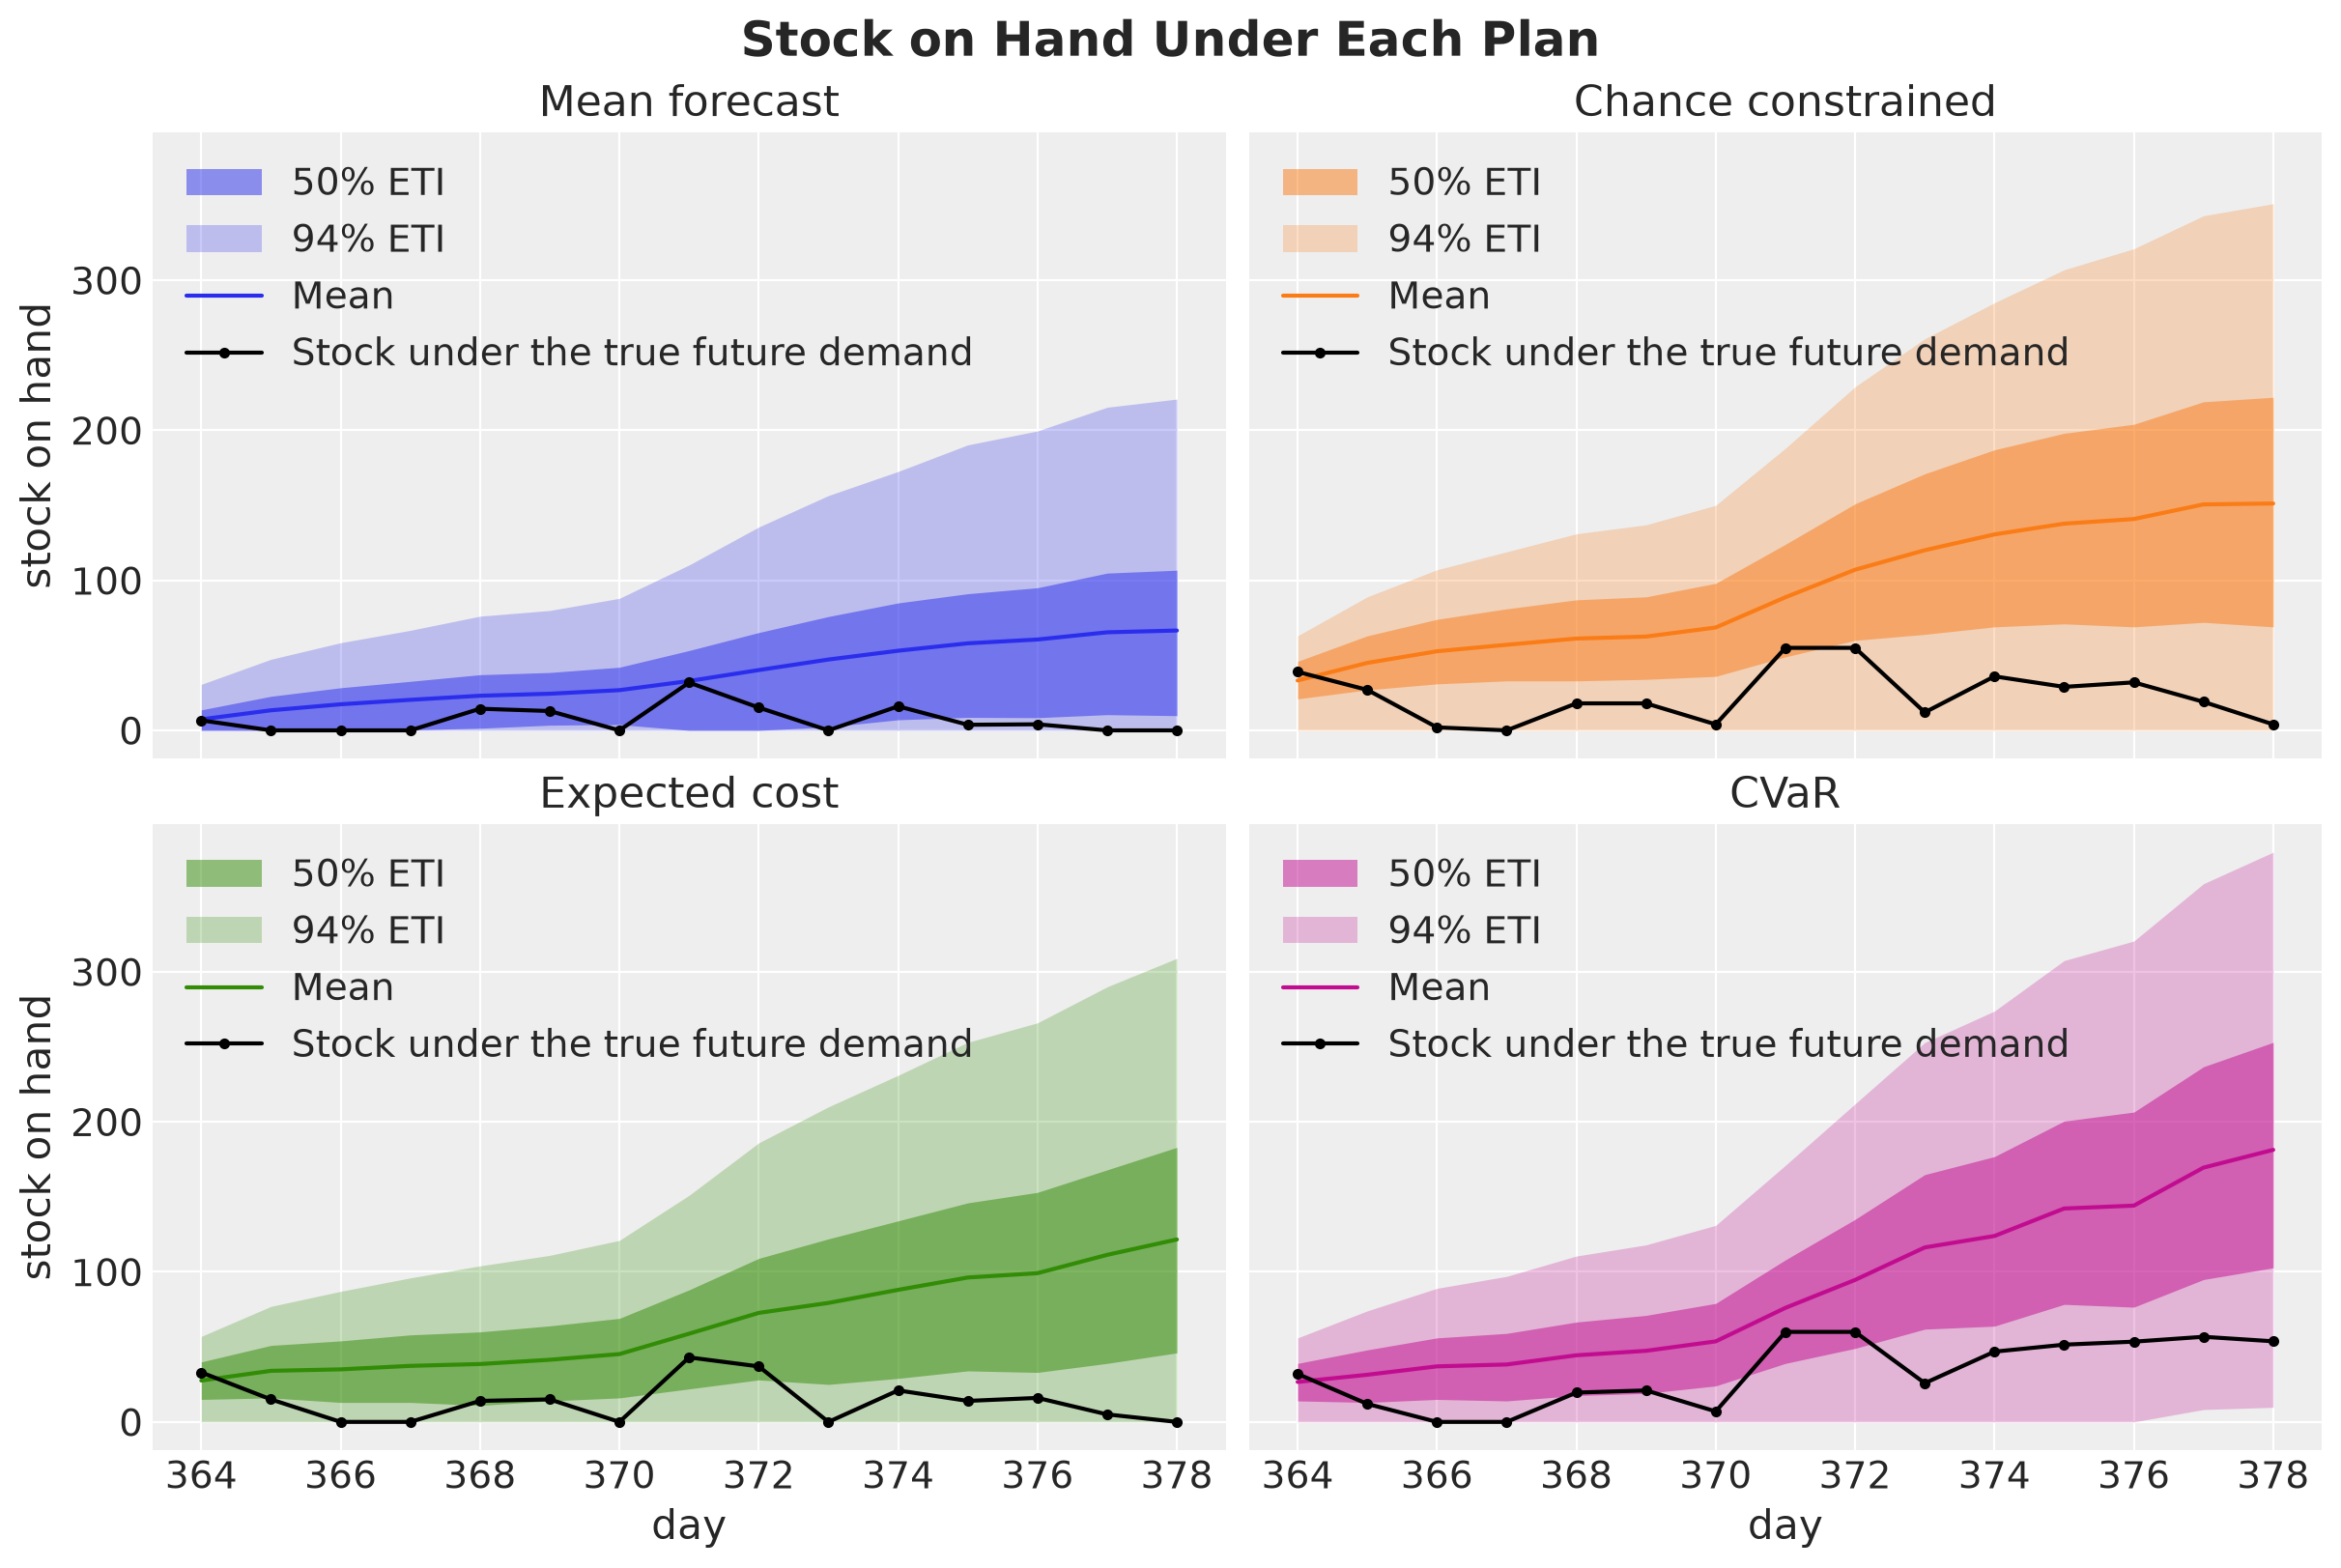

In [36]:
# the true future is one path, so we drop the scenario axis of the three fields
realized_paths = {
    plan.name: Simulation(
        *(
            field[0]
            for field in simulate_scenarios(plan.orders, demand_future_true[None, :])
        )
    )
    for plan in plans
}
inventory_tree = az.from_dict(
    {
        "posterior_predictive": {
            "inventory": np.stack([sim.inventory for sim in scores.values()], axis=1)[
                None
            ]
        },
        "observed_data": {
            "inventory": np.stack([sim.inventory for sim in realized_paths.values()])
        },
        "constant_data": {"day": np.tile(days_future.astype(float), (len(plans), 1))},
    },
    coords={"time": days_future, "plan": plan_names},
    dims={"inventory": ["plan", "time"], "day": ["plan", "time"]},
)

pc = az.plot_lm(
    inventory_tree,
    x="day",
    y="inventory",
    y_obs="inventory",
    plot_dim="time",
    smooth=False,
    ci_kind="eti",
    ci_prob=(0.5, HDI_PROB),
    point_estimate="mean",
    aes={"color": ["plan"]},
    aes_by_visuals={"pe_line": ["color"]},
    color=plan_palette,
    visuals={
        "pe_line": {"alpha": 1.0},
        "observed_scatter": False,
        "xlabel": False,
        "ylabel": False,
    },
    col_wrap=2,
    figure_kwargs={"figsize": (12, 8), "sharex": True, "sharey": True},
)
lighten_bands(pc, "day")

for i, name in enumerate(plan_names):
    ax = pc.get_target("day", {"plan": name})
    bands = pc.viz["ci_band"]["day"].sel(plan=name)
    bands.sel(prob=0.5).item().set_label("50% ETI")
    bands.sel(prob=HDI_PROB).item().set_label(f"{HDI_PROB:.0%} ETI")
    pc.viz["pe_line"]["day"].sel(plan=name).item().set_label("Mean")
    ax.plot(
        days_future,
        realized_paths[name].inventory,
        "o-",
        markersize=3,
        color="black",
        label="Stock under the true future demand",
    )
    ax.set(
        title=name,
        xlabel="day" if i >= 2 else "",
        ylabel="stock on hand" if i % 2 == 0 else "",
    )
    ax.legend(loc="upper left")

fig = pc.viz["figure"].item()
fig.suptitle("Stock on Hand Under Each Plan", fontsize=18, fontweight="bold");

The bands are the $50\%$ and $94\%$ equal-tailed intervals of the stock on hand over the held-out scenarios, and the colored line is the mean. Under the mean forecast plan the lower edge of the narrow band sits at most at $11$ units on every day, because the shelf is empty in a quarter of the scenario and day pairs. The other plans lift the narrow band off the axis on every day.

The wide band separates the CVaR plan from the other two buffered plans. Its lower edge is the $3$rd percentile of the stock, and it lifts off the axis only under the CVaR plan, on the last two days, where that plan runs out in about $2\%$ of the scenarios.

The mean stock grows over the horizon under every plan, and so does the width of the bands. There are two reasons for this.

- **The clip at zero.** In a scenario where the demand is below the stock available, the leftover carries over to the next day. In a scenario where the demand is above it, the stock is zero and the lost sales do not make it negative. So a surplus accumulates and a shortfall does not, and the leftovers pile up in the scenarios with low demand. The plan is fixed in advance, so it cannot cut a later order when the stock piles up.
- **Orders above the mean demand.** From day two on, the three buffered plans order at or above the mean demand on almost every day, as we saw in the *Decision Plans* section, because the forecast fan widens with the horizon and a plan that protects a tail has to carry more stock on the later days. In the typical scenario that extra stock stays on the shelf.

The buffered plans end the horizon with $120$ to $180$ units on the shelf on average. This is the cost of a plan fixed in advance, which cannot react to the demand it observes.

Next, let's score the plans on the one true future path we held out at the start. Keep in mind that the held-out scores of the previous figures are averages over $3{,}000$ demand paths, while here we have one path. The realized loss of a plan on one path can be far from its expected loss, and the order of the plans on one path need not match the order of their expected losses. So we use this path to check that the plans behave as the scores suggest, not to pick one. We show the realized loss and the number of days with lost sales.

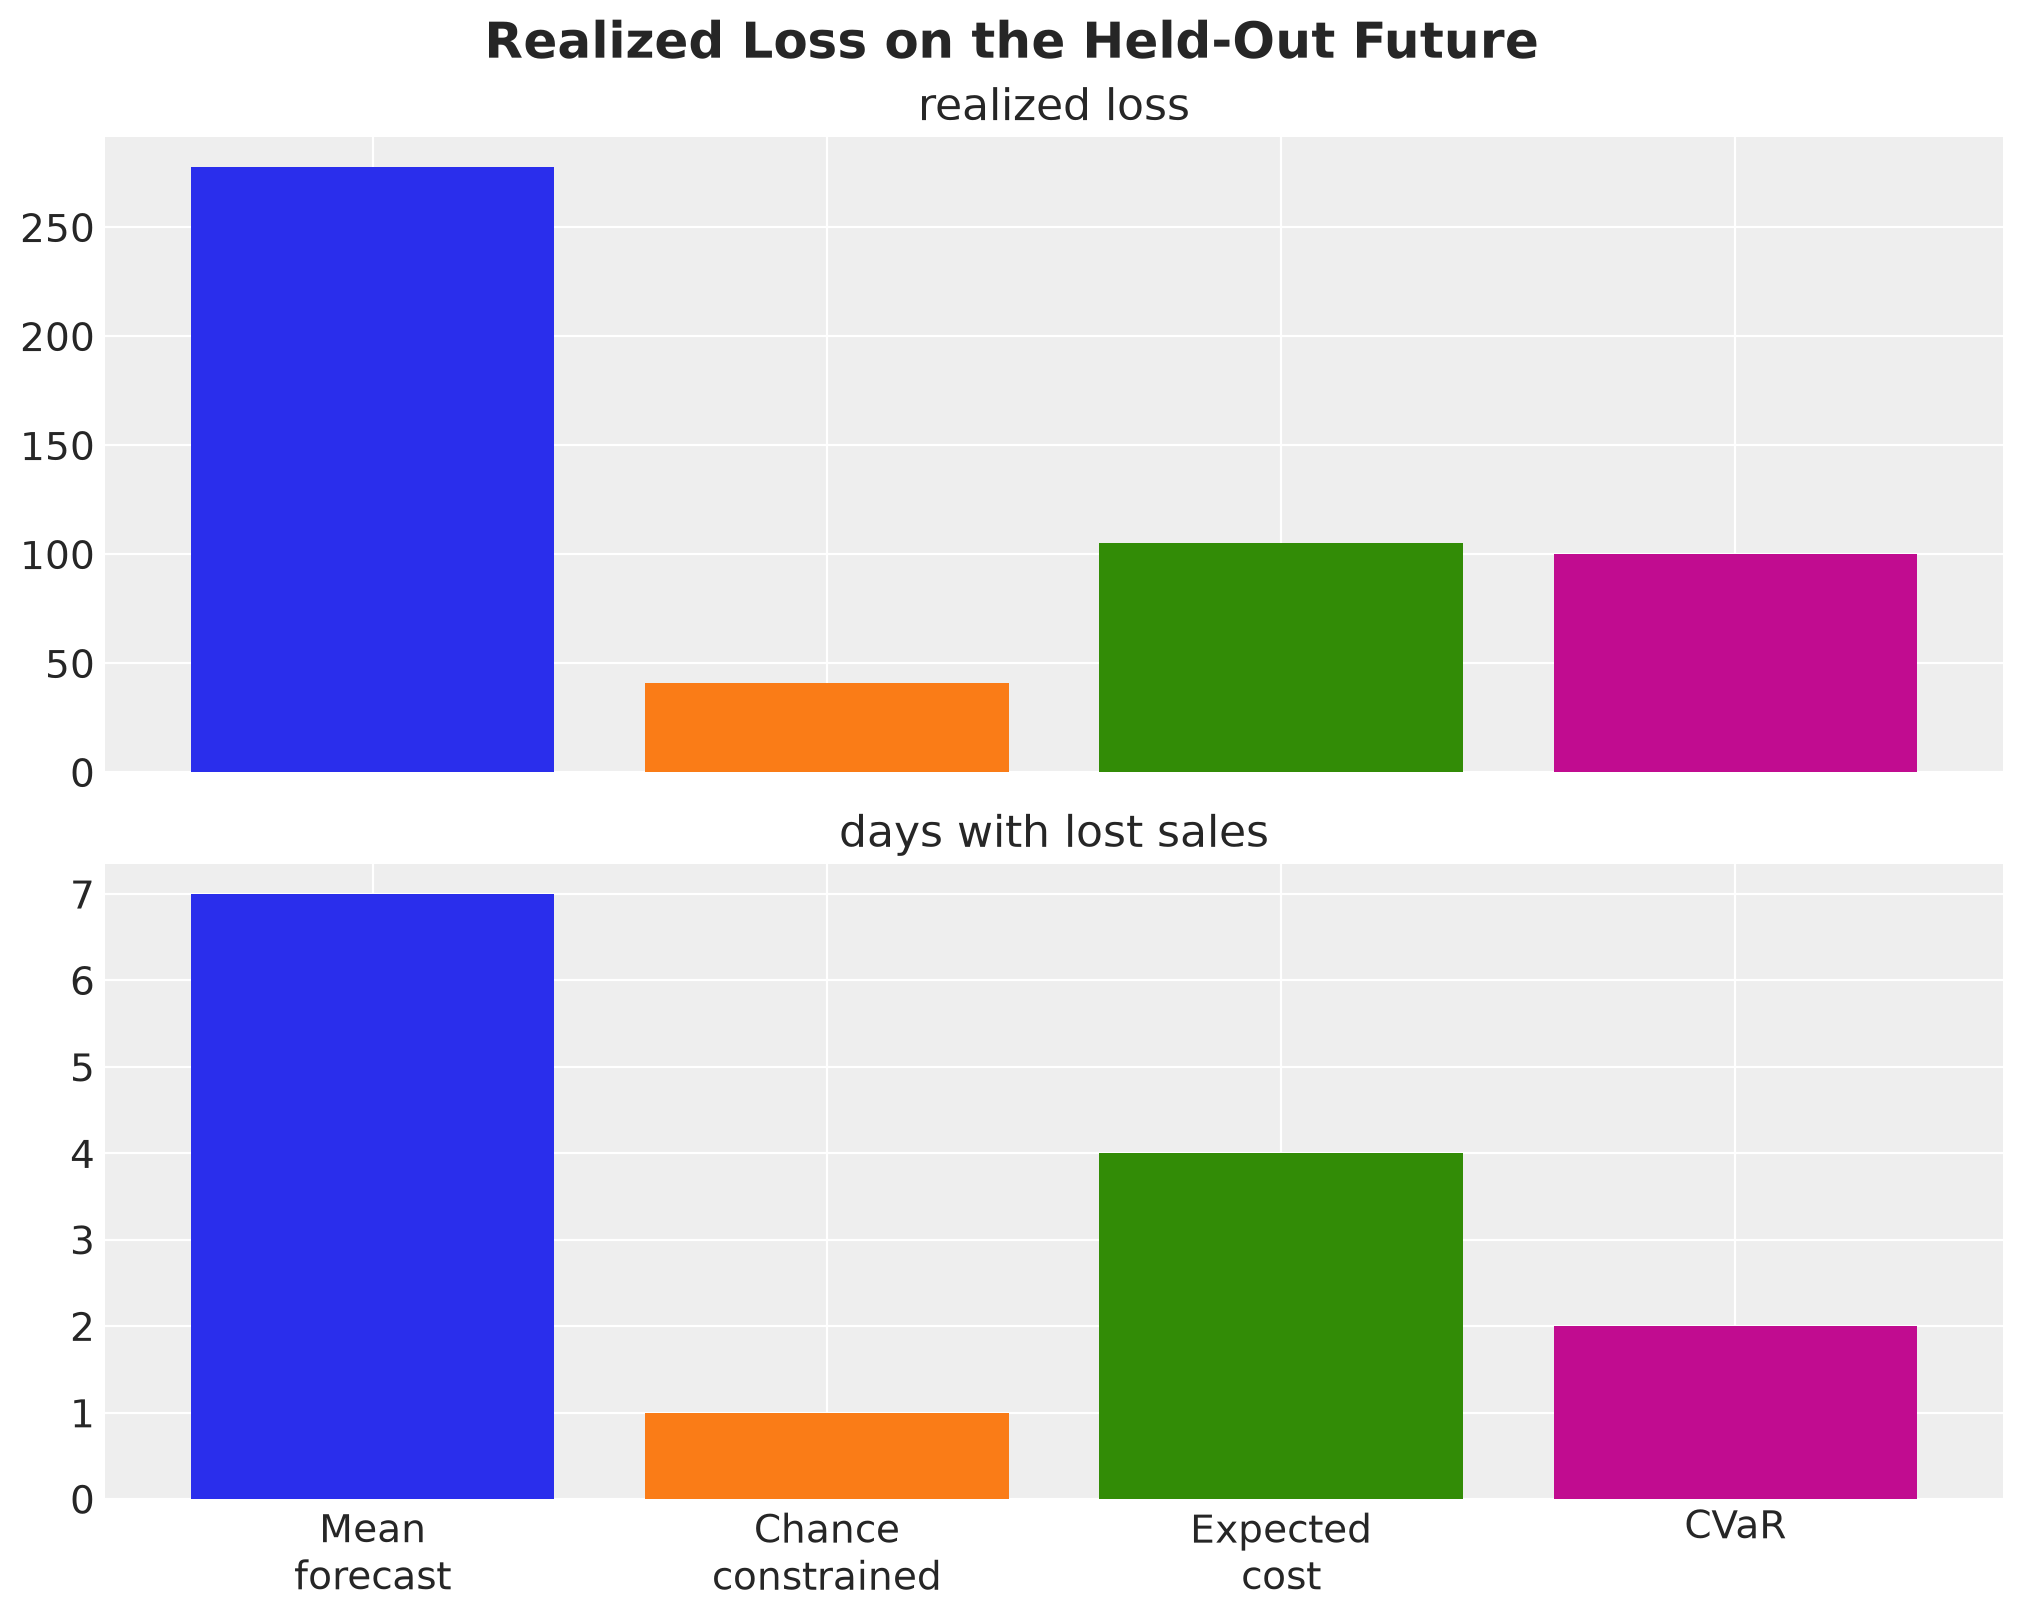

In [37]:
realized = pl.DataFrame(
    [
        {
            "plan": name,
            "realized loss": float(sim.loss),
            "days with lost sales": int(is_stockout(sim).sum()),
        }
        for name, sim in realized_paths.items()
    ]
)

fig, axes = plt.subplots(
    nrows=2, ncols=1, figsize=(10, 8), sharex=True, layout="constrained"
)

for ax, metric in zip(axes, ["realized loss", "days with lost sales"], strict=True):
    ax.bar(range(len(plans)), realized[metric].to_list(), color=plan_palette)
    ax.set(title=metric, xlabel="", ylabel="")

axes[-1].set_xticks(range(len(plans)), plan_labels)
axes[1].yaxis.set_major_locator(MaxNLocator(integer=True))
fig.suptitle("Realized Loss on the Held-Out Future", fontsize=18, fontweight="bold");

The true path ran above the forecast mean on $10$ of the $15$ days and by $9\%$ in total, so it is a high-demand future. The mean forecast plan lost sales on seven days, $133$ units in total, with the largest misses on day three ($32$ units) and day ten ($38$ units), and it paid $278$, more than twice any other plan.

The three buffered plans ran out on one to four days. The chance-constrained plan lost $3$ units on day four and paid $41$, most of it holding cost. The expected cost plan lost $42$ units over four days and paid $105$, and the CVaR plan lost $25$ units on days three and four and paid $100$. On this one path the chance-constrained plan is the cheapest, because the high demand used the buffer it carries in the first week.

## Pareto Frontier

We have two objectives, the expected loss and the tail loss (the CVaR), and no single plan is the best on both. A plan is **Pareto efficient** if no other plan improves one of the objectives without worsening the other. The set of Pareto efficient plans is the **Pareto frontier**. The frontier shows the price of one objective in terms of the other, and the choice of a point on it is a business decision.

The CVaR objective $\text{E}[L] + \lambda \, \text{CVaR}_\alpha(L)$ traces this frontier. Each weight $\lambda$ gives one plan, which is Pareto efficient on the optimization scenarios, and we check what survives on the held-out ones. The weight $\lambda$ has no natural scale, so we sweep over it: for each $\lambda$ we solve the problem, score the plan out of sample, and plot the expected loss against the tail loss and against the stockout frequency. The solver is compiled once, so the sweep is a loop of seven calls to the same function. Let's run the sweep and score every plan on the held-out scenarios.

In [38]:
lambdas = np.array([0.0, 0.1, 0.25, 0.5, 1.0, 2.0, 8.0])
orders_frontier = [solve(orders_mean, demand_opt, lam)[0] for lam in lambdas]

frontier = pl.DataFrame(
    [
        {
            "lambda": float(lam),
            **summarize(simulate_scenarios(orders, demand_eval), demand_eval),
        }
        for lam, orders in zip(lambdas, orders_frontier, strict=True)
    ]
)

We plot the frontier, with the composition of the tail as a third panel, and mark the three plans on it. The mean forecast plan is far outside the panels, so we leave it out. The horizontal axis is the expected loss, so the $\lambda$ points are not evenly spaced, and the labels of the upper panel apply to all three.

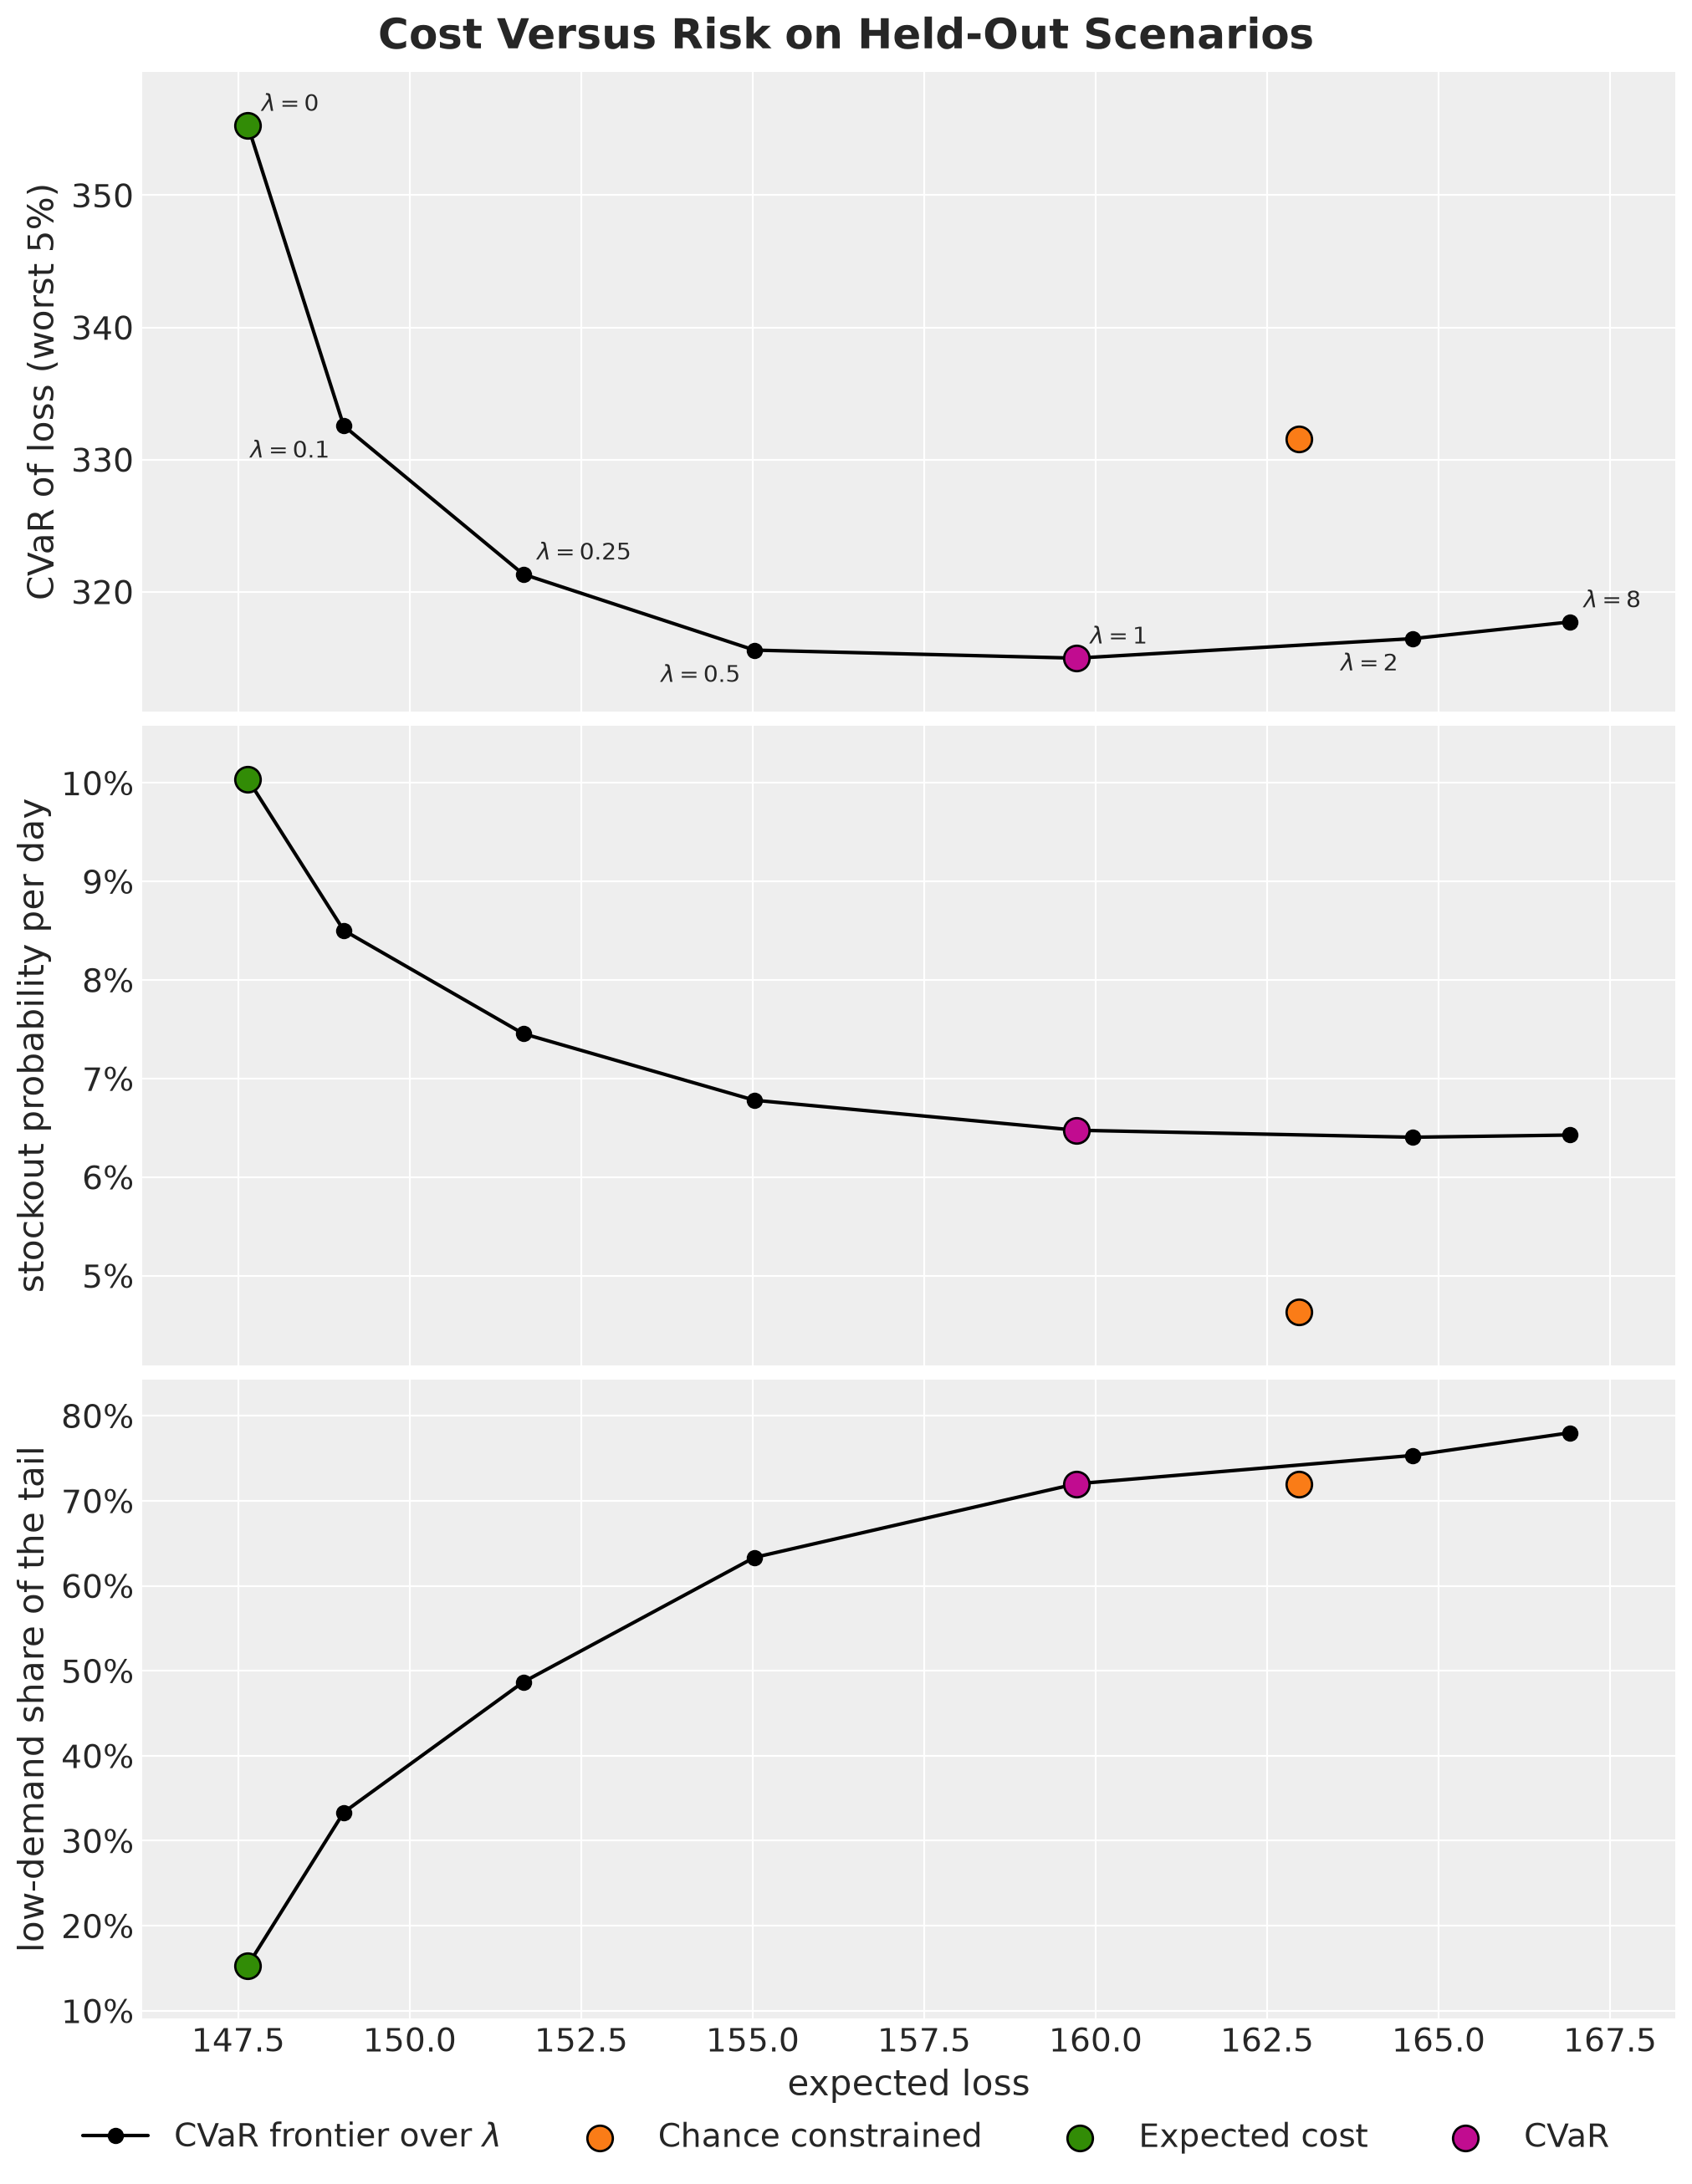

In [39]:
frontier_metrics = [Metric.CVAR, Metric.STOCKOUT, Metric.TAIL_SHARE]

fig, axes = plt.subplots(nrows=3, figsize=(10, 13), sharex=True, layout="constrained")

for ax, metric in zip(axes, frontier_metrics, strict=True):
    ax.plot(
        frontier[Metric.EXPECTED_LOSS],
        frontier[metric],
        "o-",
        color="black",
        label=r"CVaR frontier over $\lambda$",
    )

    # the mean forecast plan is far outside the panels, so we leave it out
    for row in results.filter(pl.col("plan") != plans[0].name).iter_rows(named=True):
        ax.scatter(
            row[Metric.EXPECTED_LOSS],
            row[metric],
            s=120,
            color=PLAN_COLORS[row["plan"]],
            edgecolor="black",
            zorder=5,
            label=row["plan"],
        )

    ax.set(ylabel=metric)
    if metric in PROBABILITY_METRICS:
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    ax.margins(x=0.08, y=0.1)

for j, row in enumerate(frontier.iter_rows(named=True)):
    axes[0].annotate(
        rf"$\lambda={row['lambda']:g}$",
        (row[Metric.EXPECTED_LOSS], row[Metric.CVAR]),
        textcoords="offset points",
        xytext=(6, 6) if j % 2 == 0 else (-6, -14),
        ha="left" if j % 2 == 0 else "right",
    )

axes[-1].set(xlabel=Metric.EXPECTED_LOSS)
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=4)
fig.suptitle("Cost Versus Risk on Held-Out Scenarios", fontsize=18, fontweight="bold");

The expected cost plan sits at $\lambda = 0$ and the CVaR plan at $\lambda = 1$. Here is what the three panels show.

- **Shape of the frontier.** Moving along the frontier to the right lowers the tail loss and raises the expected loss, and the held-out scores keep that order up to $\lambda = 1$. The frontier is steep on the left and flat on the right.
- **Price of tail loss.** $\lambda = 0.1$ cuts the tail loss by $6\%$ at a $1\%$ cost in expected loss, $\lambda = 1$ cuts it by $11\%$ for $8\%$ more expected loss, and beyond $\lambda = 1$ the tail loss hardly moves while the expected loss rises by another $5\%$. The curve tells us how much expected loss one unit of tail loss costs.
- **Chance-constrained plan.** It sits above the frontier in the upper panel: the $\lambda = 0.5$ plan beats it on both metrics, $155$ against $163$ in expected loss and $316$ against $332$ in tail loss. In the middle panel it sits far below the curve, at $4.6\%$ against $6.4\%$ at best. The chance-constrained plan protects every day of the horizon at the same level, while the CVaR plan protects the second week more than the first (its stockout probability is $8\%$ to $12\%$ on the first five days), and the per-day stockout probability counts every day the same.
- **Tail composition.** The stockout frequency stops improving beyond $\lambda = 1$, and the lower panel explains why. At $\lambda = 0$ the worst $5\%$ of the held-out scenarios are mostly high-demand horizons ($15\%$ have a below-median total demand). As $\lambda$ grows the plan carries more stock, so low-demand horizons that pay holding cost on the whole buffer enter the tail, up to $78\%$ of it at $\lambda = 8$. The chance-constrained plan sits on the curve in this panel, with $72\%$ of its tail in low-demand horizons, since it also carries a large buffer.

## Conclusion

### Key Findings

- **Rule and forecast.** The forecast fixes the scenarios, and the decision rule applied to them is a separate choice: expected cost, a service level or a weight on the worst outcomes. Plans built from the same scenarios under different rules differ by tens of percent in cost and in tail loss.
- **Distribution, not point.** The loss has a kink at the stock, so the cost on the mean path underestimates the expected cost, and when the two errors have different prices the best stock is not the mean. A plan built on a point forecast is the most expensive plan on every metric we report, and only a probabilistic forecast gives us the alternatives.
- **Multi-period dynamics.** Carried stock couples the days, so single-period formulas applied day by day miss the multi-period optimum (here they overstock, at a $12\%$ higher expected loss on the held-out scenarios). A loss written as a simulator and optimized directly does not depend on closed forms that hold only for one period.
- **Frequency and severity.** A chance constraint controls how often we run out, and CVaR controls how bad the worst outcomes are. A service level needs the constraint, a bound on bad outcomes needs the tail weight, and the frontier over $\lambda$ shows the price of one in terms of the other. Beyond some weight the stockout frequency stops improving, because the tail fills with low-demand scenarios that pay holding cost.
- **Joint scenarios.** Anything with a term that depends on the demand of several days or products at once (carried stock, or a CVaR or a chance constraint on the total loss) needs joint draws, not per-day quantiles. A posterior predictive gives them directly, and a plan built on shuffled days landed at $7\%$ per day against a $5\%$ target.
- **Simulator as a graph.** The simulator is a PyTensor graph. The same graph scores a plan and gives the gradient that the solver needs, and it compiles into one function that the frontier sweep calls seven times.
- **Out-of-sample scores.** Held-out scenarios score a plan on draws it was not fitted to, which is the fair comparison between plans built with different rules. A cross check against an exact solver, in the *Appendix*, confirms that the gradient solver reaches the optimum.

### Model Limitations

- **No recourse.** All orders are fixed at the start of the horizon. A rolling horizon that re-forecasts and re-solves each day, and commits only the next order, is the practical version of this problem.
- **No lead time.** Orders arrive on the day we planned them for. The VN2 setting has a two-week delivery lead time, which moves the decision to the stock projected at the delivery date.
- **Unconstrained demand history.** The forecasting model sees the demand itself. In a real lost-sales setting the history is sales, which are censored on the days the shelf was empty. The VN2 report handles this with stockout-aware features, Caron (2023) with a censored likelihood, and the [censored demand example](https://pymc-labs.github.io/pymc-forecast/examples/censored_demand.html) of `pymc_forecast` shows the same likelihood in a forecasting model.
- **Same posterior throughout.** The held-out scenarios come from the posterior that produced the optimization set, so they check the plans against new draws from the same forecast (the expected cost plan scores $148.3$ in sample and $147.6$ held out) but not against model misspecification. A backtest on real data would show it.
- **Linear costs.** A lost sale costs the same margin on every day, and leftovers keep their value at the end of the horizon. Perishable goods, order minimums and fixed ordering costs change the simulator, and integer order quantities change the solver.
- **Small tail sample.** With $\alpha = 0.05$ and $1{,}000$ scenarios, the CVaR objective is the mean of $50$ losses, and those $50$ scenarios shape the plan. A real application needs more scenarios, or a check of the plan across resampled scenario sets.

### Recommendations

1. **Elicit the costs.** The holding cost and the margin set the critical fractile and every cost-based plan with it. Agree on them with the business before any optimization, and state what a leftover is worth at the end of the horizon.
2. **Pick from the frontier.** Do not fix a service level or a tail weight by default. Report the expected loss, the tail loss and the stockout frequency of several plans and let the business pick the point.
3. **Backtest the plan.** Score the forecast and the plan together on a rolling window of real data, with the same loss, so that model misspecification shows up as cost.

## Next Steps

1. **Rolling horizon.** Wrap the solve in `pymc_forecast.backtest` so that each window re-forecasts, re-solves and commits one order.
2. **Lead time.** Add a pipeline of in-transit orders to the scan carry, as in the VN2 setting, so that an order placed today arrives in two weeks. Only the simulator changes.
3. **Many products.** Fit a hierarchical forecast, give the scan carry a product axis with the orders as a matrix, and replace the clip at zero by the projection onto non-negative orders within a shared budget, which needs a one-dimensional search for the budget multiplier.
4. **Distributionally robust variant.** Let an adversary reweight the scenarios, within a bound on how far the new weights may move from the uniform weights $1 / N$ (measured by a divergence such as the Kullback-Leibler divergence), and minimize the worst-case weighted loss. This shows how much of the frontier survives when we do not trust the tails of the forecast.

## Appendix

### Convex Solver Cross Check

The projected gradient solver is convenient because it stays in PyTensor, but it is a first-order method on a non-smooth objective. The loss has a kink wherever a positive part switches, that is, wherever the stock available equals the demand of a day in one of the scenarios. The gradient jumps at these kinks, so a first-order method can stop short of the exact optimum. In this appendix we confirm that it does not, with a solver that reaches the exact optimum of a linear program. Two things make the objective a linear program:

- The loss is convex and piecewise linear in the plan, since it is a positive combination of the daily stocks plus a linear term, and each stock is a maximum of affine functions of the plan.
- The CVaR has a representation with a **threshold variable**: an extra decision variable $\zeta$, a loss threshold, such that the CVaR is the minimum over $\zeta$ of a convex piecewise linear function of $\zeta$. Its positive parts become linear constraints once we add one auxiliary variable per scenario.

We start with the second one. The representation of the conditional value at risk of [Rockafellar and Uryasev (2000)](https://www.risk.net/journal-risk/2161159/optimization-conditional-value-risk) is

$$
\text{CVaR}_\alpha(L) = \min_{\zeta} \left\{ \zeta + \frac{1}{\alpha} \, \text{E}\left[(L - \zeta)^{+}\right] \right\},
$$

where a minimizing $\zeta$ is the value at risk. Let's verify this representation on the losses of the expected cost plan over the optimization scenarios, in three steps.

- We write the function inside the braces as `ru_objective`, with the expectation replaced by the average over the scenarios.
- We evaluate it on a grid of thresholds.
- We compare its minimum with the value that `cvar` computes from the $k$ largest losses, and the location of the minimum with the value at risk.

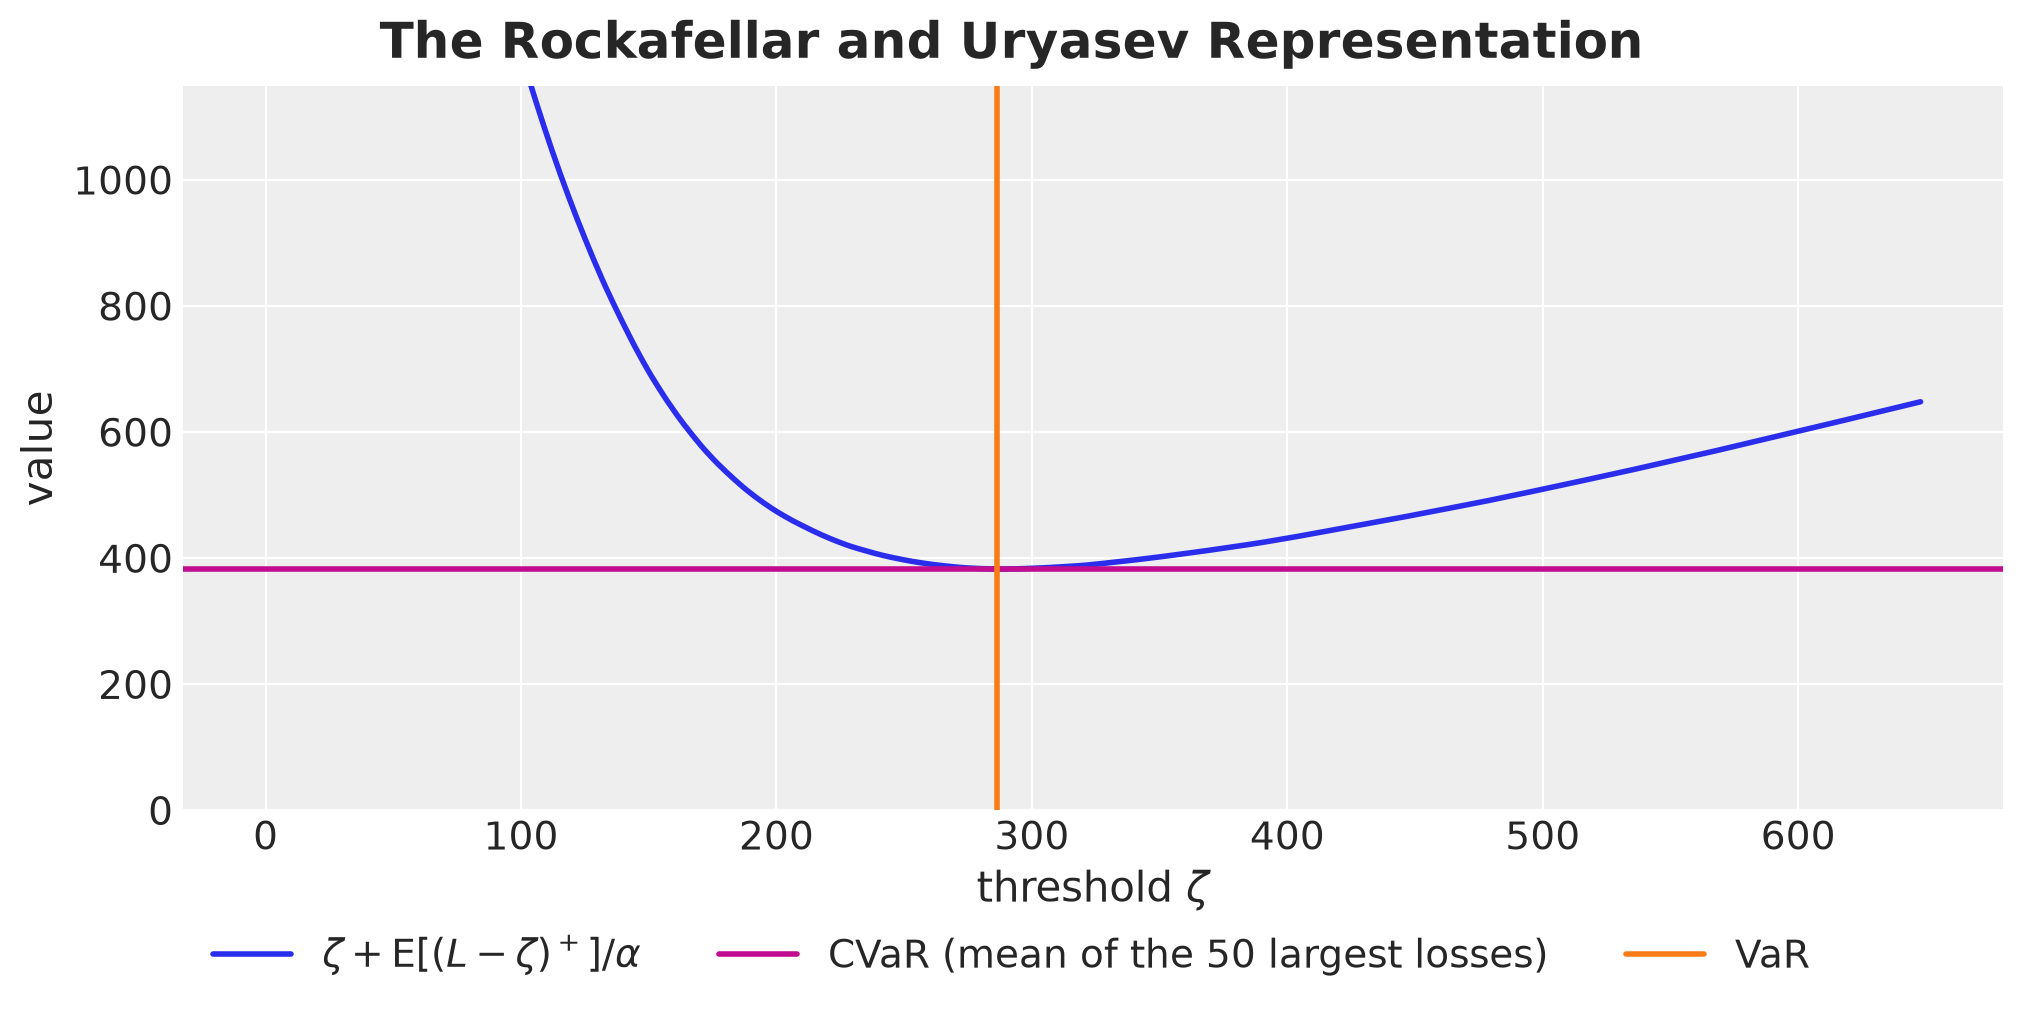

In [40]:
def ru_objective(threshold: np.ndarray, losses: np.ndarray) -> np.ndarray:
    """The threshold zeta plus the scenario average of (L - zeta)^+ over alpha."""
    excess = np.maximum(losses[None, :] - threshold[:, None], 0.0)
    return threshold + excess.mean(axis=1) / ALPHA


losses_saa_opt = simulate_scenarios(orders_saa, demand_opt).loss
threshold_grid = np.linspace(0.0, losses_saa_opt.max(), 400)
ru_values = ru_objective(threshold_grid, losses_saa_opt)
k = tail_size(N_SCENARIOS_OPT)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(
    threshold_grid,
    ru_values,
    color="C0",
    linewidth=2,
    label=r"$\zeta + \text{E}[(L - \zeta)^+] / \alpha$",
)
ax.axhline(
    float(cvar(losses_saa_opt, k)),
    color="C3",
    linewidth=2,
    label=f"CVaR (mean of the {k} largest losses)",
)
ax.axvline(
    float(np.quantile(losses_saa_opt, 1 - ALPHA, method="inverted_cdf")),
    color="C1",
    linewidth=2,
    label="VaR",
)
fig.legend(loc="outside lower center", ncol=3)
ax.set(
    xlabel=r"threshold $\zeta$",
    ylabel="value",
    ylim=(0, 3 * float(cvar(losses_saa_opt, k))),
)
fig.suptitle(
    "The Rockafellar and Uryasev Representation", fontsize=18, fontweight="bold"
);

The curve is convex in $\zeta$, its minimum sits at the value at risk, and the minimum value is the conditional value at risk that `cvar` computes from the sorted losses. So the linear program minimizes the same objective as `solve`. It minimizes over $\zeta$ and over the plan at the same time, with one **auxiliary variable** $u_n \geq (L_n - \zeta)^{+}$ per scenario, where $L_n = L(a, D^{(n)})$ is the loss of scenario $n$.

Now we turn to the loss. The lost sales of a day are the demand minus the stock available, plus the leftover:

$$
U_t = (D_t - y_t)^{+} = D_t - y_t + (y_t - D_t)^{+} = D_t - y_t + I_t.
$$

With $y_t = I_{t-1} + a_t$, we sum $h \, I_t + p \, U_t$ over the days. The stocks $I_{t-1}$ and $I_t$ telescope, and we get

$$
L(a, D) = h \sum_{t=1}^{H} I_t + p \, I_H + p \left( C_H - I_0 - A_H \right),
$$

where $A_H = \sum_t a_t$ is the **total order** and $C_H = \sum_t D_t$ the **total demand**. The last term is linear in the plan. Each stock is the positive part of an affine function of the previous stock and the order,

$$
I_t = \max\left(I_{t-1} + a_t - D_t, \, 0\right),
$$

so by induction on $t$ it is convex in $a$, and the loss is convex in $a$. The mean of the $k$ largest losses is convex and non-decreasing in the losses, so the objective is convex too.

In the linear program we replace every stock $I_t^{(n)}$ by a variable with two constraints,

$$
I_t^{(n)} \geq I_{t-1}^{(n)} + a_t - D_t^{(n)}, \qquad I_t^{(n)} \geq 0.
$$

Every stock variable has a positive coefficient in the objective, so the solver pushes each one down to the larger of the two bounds, which is the positive part we want. We write the program in three pieces: `stock_constraints` builds the stock bounds, `scenario_losses` the loss of every scenario, and `cvar_epigraph` the CVaR term with its auxiliary variables and constraint. Then `solve_lp` assembles them and hands the problem, with $N \times H$ stock variables, to HiGHS through `cvxpy`, and we solve it for the two weights.

In [41]:
def stock_constraints(
    stock: cp.Variable, orders: cp.Variable, demand: np.ndarray, config: InventoryConfig
) -> list[cp.Constraint]:
    """I_t >= I_{t-1} + a_t - D_t for every scenario and day, tight at the optimum."""
    horizon = demand.shape[1]
    first_day = stock[:, 0] >= config.initial_inventory + orders[0] - demand[:, 0]
    later_days = [
        stock[:, t] >= stock[:, t - 1] + orders[t] - demand[:, t]
        for t in range(1, horizon)
    ]
    return [first_day, *later_days]


def scenario_losses(
    stock: cp.Variable, orders: cp.Variable, demand: np.ndarray, config: InventoryConfig
) -> cp.Expression:
    """The loss h sum_t I_t + p I_H + p (C_H - I_0 - A_H) of every scenario."""
    return (
        config.holding_cost * cp.sum(stock, axis=1)
        + config.lost_sales_cost * stock[:, -1]
        + config.lost_sales_cost
        * (demand.sum(axis=1) - config.initial_inventory - cp.sum(orders))
    )


def cvar_epigraph(
    losses: cp.Expression, num_scenarios: int
) -> tuple[cp.Expression, list[cp.Constraint]]:
    """The Rockafellar and Uryasev term zeta + sum_n u_n / k with its constraint."""
    threshold = cp.Variable()  # zeta
    excess = cp.Variable(num_scenarios, nonneg=True)  # u_n >= (L_n - zeta)^+
    # the same integer tail size as `cvar`, so both objectives agree
    term = threshold + cp.sum(excess) / tail_size(num_scenarios)
    return term, [excess >= losses - threshold]


def solve_lp(demand: np.ndarray, lam: float, config: InventoryConfig) -> np.ndarray:
    """The same objective as `solve`, as a linear program."""
    demand = np.asarray(demand, dtype="float64")
    num_scenarios, horizon = demand.shape
    orders = cp.Variable(horizon, nonneg=True)  # the plan a
    stock = cp.Variable((num_scenarios, horizon), nonneg=True)  # I_t of every scenario

    constraints = stock_constraints(stock, orders, demand, config)
    losses = scenario_losses(stock, orders, demand, config)
    cvar_term, cvar_constraints = cvar_epigraph(losses, num_scenarios)
    lp = cp.Problem(
        cp.Minimize(cp.sum(losses) / num_scenarios + lam * cvar_term),
        [*constraints, *cvar_constraints],
    )
    lp.solve(solver=cp.HIGHS)

    assert lp.status == cp.OPTIMAL, lp.status
    return np.asarray(orders.value, dtype="float64")


orders_lp_saa = solve_lp(demand_opt, 0.0, config)
orders_lp_cvar = solve_lp(demand_opt, 1.0, config)

We overlay the order plans of both solvers and evaluate `objective_fn` at both solutions, so that the two values come from the same function. The panel titles carry the relative gap and the largest difference between the two order vectors.

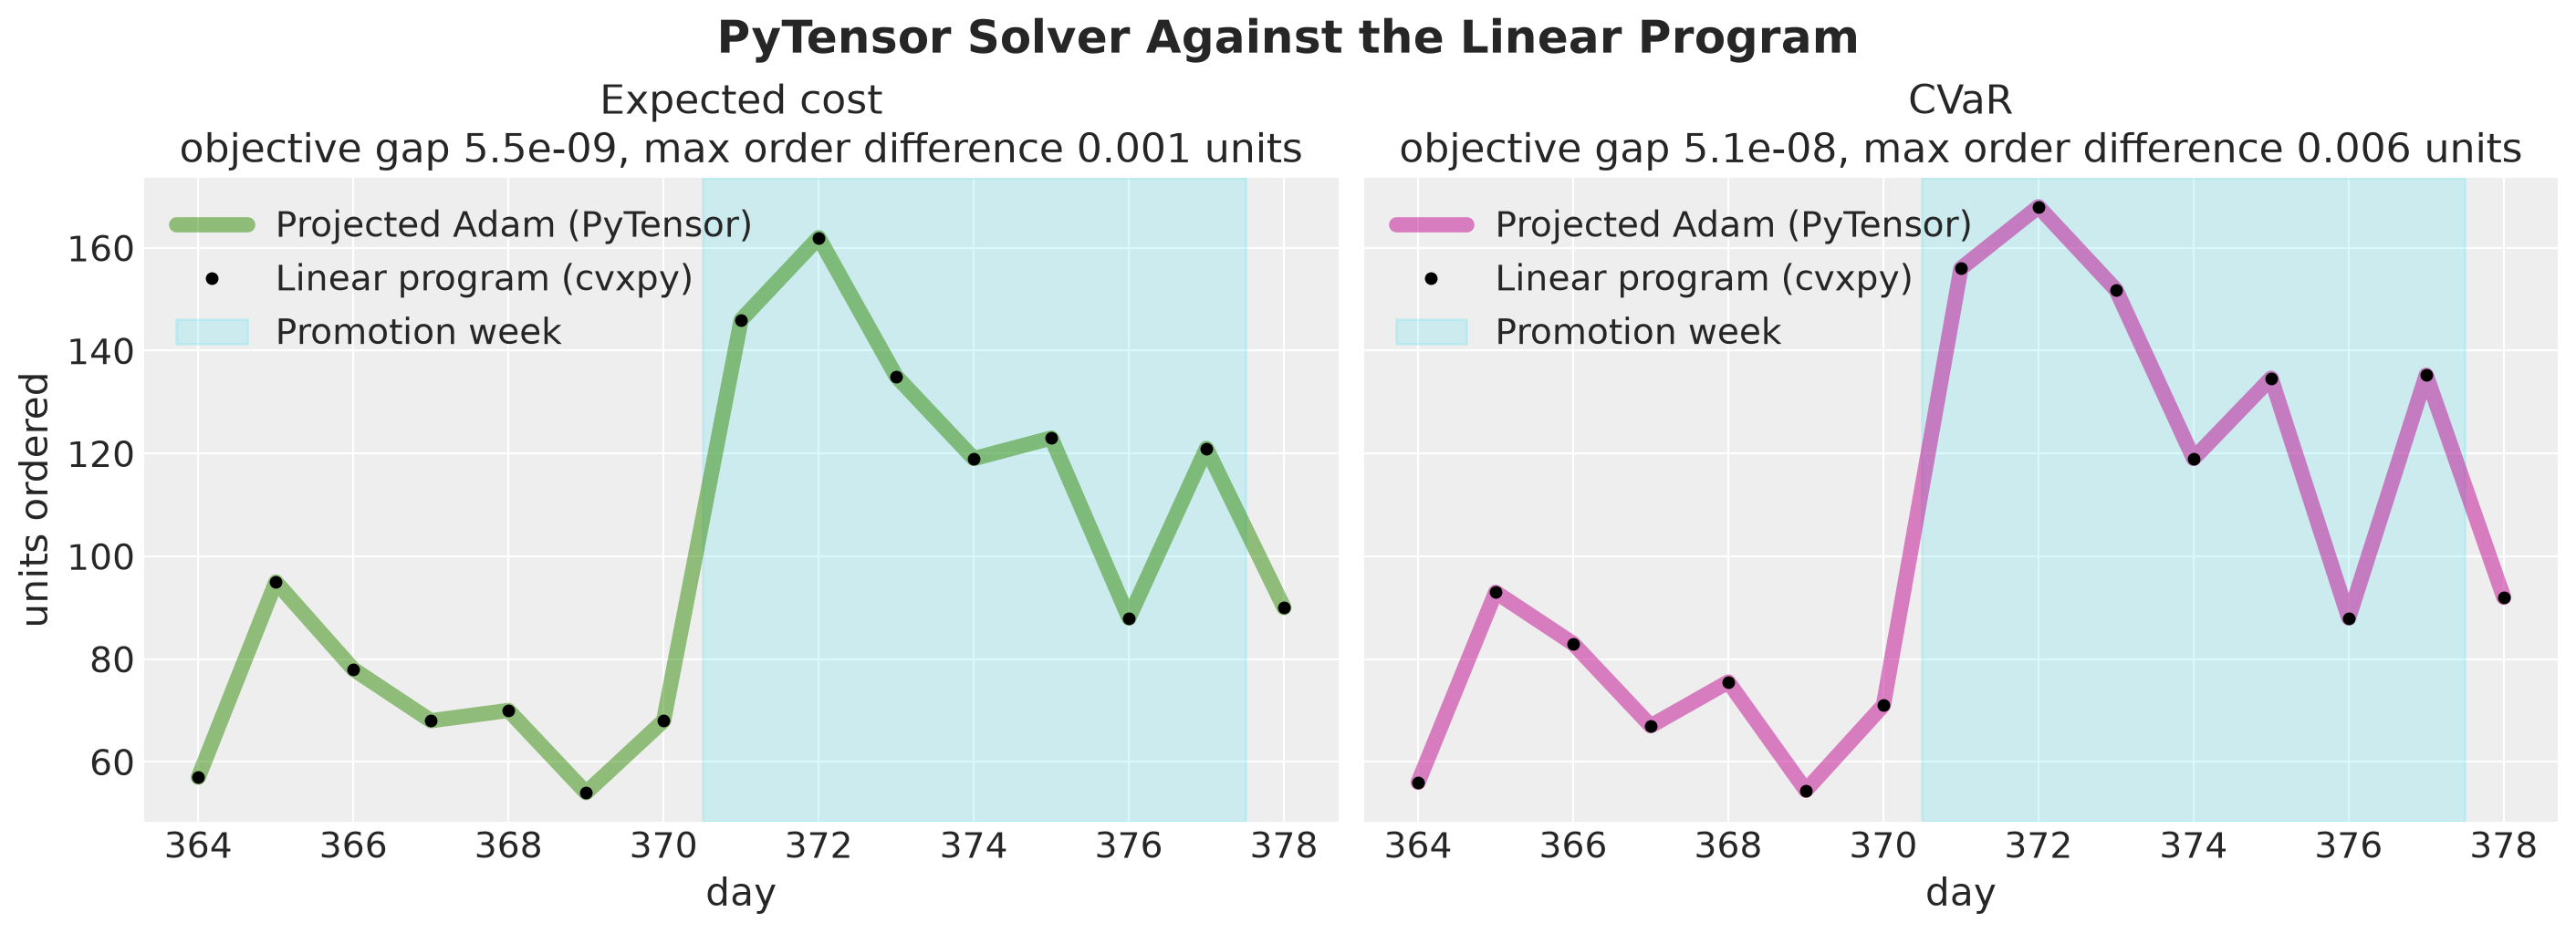

In [42]:
fig, axes = plt.subplots(ncols=2, figsize=(14, 5), sharey=True, layout="constrained")
relative_gaps = []

for ax, (name, lam, orders_pt, orders_lp, color) in zip(
    axes,
    [
        ("Expected cost", 0.0, orders_saa, orders_lp_saa, "C2"),
        ("CVaR", 1.0, orders_cvar, orders_lp_cvar, "C3"),
    ],
    strict=True,
):
    value_pt = float(objective_fn(orders_pt, demand_opt, lam))
    value_lp = float(objective_fn(orders_lp, demand_opt, lam))
    relative_gap = value_pt / value_lp - 1
    relative_gaps.append(relative_gap)
    max_order_diff = float(np.abs(orders_pt - orders_lp).max())
    ax.plot(
        days_future,
        orders_pt,
        color=color,
        linewidth=6,
        alpha=0.5,
        label="Projected Adam (PyTensor)",
    )
    ax.plot(
        days_future,
        orders_lp,
        "o",
        color="black",
        markersize=4,
        label="Linear program (cvxpy)",
    )
    shade_promotion(ax)
    ax.set(
        xlabel="day",
        title=f"{name}\nobjective gap {relative_gap:.1e}, "
        f"max order difference {max_order_diff:.3f} units",
    )
    ax.legend(loc="upper left")

axes[0].set(ylabel="units ordered")
fig.suptitle(
    "PyTensor Solver Against the Linear Program", fontsize=18, fontweight="bold"
);

In [43]:
assert max(abs(gap) for gap in relative_gaps) < 1e-5

The two solvers agree! The relative objective gap is $6 \times 10^{-9}$ for the expected cost plan and $5 \times 10^{-8}$ for the CVaR plan, and the orders differ by at most $0.006$ units on orders between $54$ and $168$ units, so the two solvers land on the same plan.

The LP orders of the expected cost plan are whole numbers on every day, so requiring whole-unit orders would not change that plan. We use the PyTensor solver because it shares the graph of the simulator, so a change in the dynamics carries over to the solver without new code, and a linear or mixed-integer program when the problem gains coupling constraints or integer decisions.

## References

- Szabłowski, B. (2026). [One Global Model, Many Behaviors: Stockout-Aware Feature Engineering and Dynamic Scaling for Multi-Horizon Retail Demand Forecasting with a Cost-Aware Ordering Policy (VN2 Winner Report)](https://arxiv.org/abs/2601.18919). arXiv:2601.18919.
- Saunders, D., Viera, B., Laramore, J. and Wimpey, E. (2026). [Designing Optimal Energy Generation Plans with PyMC and FICO Xpress](https://www.pymc-labs.com/blog-posts/probabilistic-forecasting-optimization-under-uncertainty). PyMC Labs blog.
- Saunders, D. (2025). [A Bayesian decision theory workflow](https://daniel-saunders-phil.github.io/imagination_machine/posts/a-bayesian-decision-theory-workflow/). Imagination Machine blog.
- Caron, K. (2023). [Modeling Anything With First Principles: Demand under extreme stockouts](https://kylejcaron.github.io/posts/censored_demand/2024-02-06-censored-demand.html). Personal blog.
- Arrow, K. J., Harris, T. and Marschak, J. (1951). [Optimal Inventory Policy](https://doi.org/10.2307/1906813). *Econometrica*, 19(3), 250-272.
- Zipkin, P. (2008). [Old and New Methods for Lost-Sales Inventory Systems](https://doi.org/10.1287/opre.1070.0471). *Operations Research*, 56(5), 1256-1263.
- Bijvank, M. and Vis, I. F. A. (2011). [Lost-sales inventory theory: A review](https://doi.org/10.1016/j.ejor.2011.02.004). *European Journal of Operational Research*, 215(1), 1-13.
- Rockafellar, R. T. and Uryasev, S. (2000). [Optimization of conditional value-at-risk](https://www.risk.net/journal-risk/2161159/optimization-conditional-value-risk). *Journal of Risk*, 2(3), 21-41.
- Shapiro, A., Dentcheva, D. and Ruszczyński, A. (2021). [Lectures on Stochastic Programming: Modeling and Theory](https://doi.org/10.1137/1.9781611976595), third edition. SIAM.
- Birge, J. R. and Louveaux, F. (2011). [Introduction to Stochastic Programming](https://link.springer.com/book/10.1007/978-1-4614-0237-4), second edition. Springer.
- FICO Xpress Community. [Stochastic Energy Planning: PyMC + FICO Xpress Optimization](https://github.com/fico-xpress/xpress-community/tree/main/StochasticEnergyPlanning).
- PyMC Labs. [PyMC-Forecast documentation](https://pymc-labs.github.io/pymc-forecast/).
- PyTensor developers. [PyTensor documentation](https://pytensor.readthedocs.io/).
- Diamond, S. and Boyd, S. (2016). [CVXPY: A Python-embedded modeling language for convex optimization](https://jmlr.org/papers/v17/15-408.html). *Journal of Machine Learning Research*, 17(83), 1-5.